# Shared Final Evaluation of Four Conditional VAE/GAN Finalists

**Authors:** Hoon Chun Fei and You Xuan (joint work)<br>
**Purpose:** evaluate the four frozen individual finalists using one identical pipeline.

## Finalists

| Family | Chun Fei | You Xuan |
|---|---|---|
| Conditional VAE | `CF-VAE-A4-CCL` | `YX-VAE-B1`, decoder checkpoint epoch 90 |
| Conditional GAN | `CF-GAN-A0-EQUAL-LR` | `YX-GAN-B4`, generator checkpoint epoch 300 |

This notebook performs **evaluation only**:

- no `.fit()` calls;
- no fallback training;
- no checkpoint overwriting;
- no separate metric implementation for either author;
- metrics are computed independently of the recorded final selection.

It regenerates balanced samples from every frozen checkpoint and calculates:

- repeated FID@5k;
- repeated IS@5k;
- requested-class accuracy and requested-class confidence;
- per-class results and confusion matrices;
- duplicate and diversity evidence;
- fixed-seed visual comparisons;
- the final 1,000-image export after the team records its decision.

## One-classifier fairness rule

Exactly **one frozen evaluation classifier** is used for all four finalists:
`evaluation_classifier.weights.h5`.

- FID and IS do **not** use this classifier; they use ImageNet InceptionV3.
- The shared classifier is used only for class-control metrics, per-class analysis,
  confusion matrices and classifier-feature diversity evidence.
- Individual evaluation classifiers are excluded so all four finalists are assessed using the same shared classifier.


## Required Input Checkpoints

This updated notebook intentionally loads only the five exact files below from
`shared_final_evaluation/inputs/`. It does not search other checkpoint folders,
so a similarly named old checkpoint or a second evaluation classifier cannot be
selected accidentally.

| Owner | Original individual-notebook checkpoint | Required shared filename |
|---|---|---|
| Chun Fei | `chun_fei_ca2_yx_split/checkpoints/evaluation_classifier.weights.h5` | `evaluation_classifier.weights.h5` |
| Chun Fei | `chun_fei_ca2_yx_split/checkpoints/CF-VAE-A4-CCL/best.weights.h5` | `CF_VAE_A4_full.weights.h5` |
| Chun Fei | `chun_fei_ca2_yx_split/checkpoints/CF-GAN-A0-EQUAL-LR/best_generator.weights.h5` | `CF_GAN_A0_generator.weights.h5` |
| You Xuan | `checkpoints/YX_VAE_B1_ep90.weights.h5` | `YX_VAE_B1_ep90.weights.h5` |
| You Xuan | `checkpoints/YX_GAN_B4_ep300.weights.h5` | `YX_GAN_B4_ep300.weights.h5` |

Required structure:

```text
shared_final_evaluation/
├── inputs/
│   ├── evaluation_classifier.weights.h5
│   ├── CF_VAE_A4_full.weights.h5
│   ├── CF_GAN_A0_generator.weights.h5
│   ├── YX_VAE_B1_ep90.weights.h5
│   └── YX_GAN_B4_ep300.weights.h5
├── cache/
├── results/
├── figures/
└── final_1000_images/
```

### How the five files are used

- The four VAE/GAN checkpoints generate the images used for **all** metrics.
- `evaluation_classifier.weights.h5` evaluates conditioning accuracy,
  requested-class confidence, per-class performance and confusion matrices.
- ImageNet InceptionV3 evaluates FID and IS.
- The same generated 5,000-image set is reused for FID, IS and class-control
  evaluation within each repeat.

Evaluation stages compute metrics directly from the frozen checkpoints, while the saved-results review stage reloads the already-computed outputs for presentation without repeating the expensive evaluation.


In [2]:
# Purpose: Reduce TensorFlow console noise and let GPU memory grow only as needed.
# Run this cell first, before importing TensorFlow.
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_FORCE_GPU_ALLOW_GROWTH", "true")

# Use logical GPU 0 when GPU acceleration is available.
# Restart the kernel before changing this value.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")


'0'

In [3]:
# Purpose: Import the libraries used for checkpoint loading, evaluation, plotting and file export.
# ============================================================
# 1. Imports
# ============================================================
from pathlib import Path
import gc
import hashlib
import json
import pickle
import random
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from scipy import linalg
from sklearn.metrics import (
    confusion_matrix,
    pairwise_distances,
)
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import Image as IPyImage, Markdown, display

print("TensorFlow:", tf.__version__)
print("Physical GPUs:", tf.config.list_physical_devices("GPU"))

physical_gpus = tf.config.list_physical_devices("GPU")
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass


TensorFlow: 2.19.0
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# Purpose: Keep all user-editable experiment settings and stage flags in one place.
# ============================================================
# 2. Configuration — edit only this cell
# ============================================================
SEED = 42
NUM_CLASSES = 10
IMAGE_SHAPE = (32, 32, 3)

CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

# --------------------------
# One-stage-at-a-time flags
# --------------------------
CHECK_INPUT_FILES = False
EVALUATE_CF_VAE_A4 = False
EVALUATE_YX_VAE_B1 = False
EVALUATE_CF_GAN_A0 = False
EVALUATE_YX_GAN_B4 = False
BUILD_FINAL_COMPARISON = False
EXPORT_FIXED_GRIDS = False
REVIEW_SAVED_OUTPUTS = True
RUN_VAE_INTERPOLATION = False
EXPORT_FINAL_1000 = False
# --------------------------
# Shared metric protocol
# --------------------------
GENERATED_IMAGES_PER_REPEAT = 5_000
IMAGES_PER_CLASS = 500
EVALUATION_REPEATS = 5
INCEPTION_SPLITS = 10
INCEPTION_BATCH_SIZE = 32
CLASSIFIER_BATCH_SIZE = 256
FID_EPSILON = 1e-6
IS_EPSILON = 1e-16
MIN_SHARED_CLASSIFIER_TEST_ACCURACY = 0.80

# Per-class FID requires many extra 2048x2048 matrix square roots.
# Keep False unless the team specifically needs it.
COMPUTE_PER_CLASS_FID = False

# --------------------------
# Shared visual setup
# --------------------------
GRID_IMAGES_PER_CLASS = 10

# --------------------------
# Final decision — recorded from the completed shared evaluation
# --------------------------
SELECTED_VAE_ID = "CF-VAE-A4-CCL"
SELECTED_GAN_ID = "YX-GAN-B4-E300"
OVERALL_WINNER_ID = "YX-GAN-B4-E300"

ALLOW_OVERWRITE_FINAL_EXPORT = False

# --------------------------
# Workspace
# --------------------------
ROOT = Path("shared_final_evaluation")
INPUT_DIR = ROOT / "inputs"
CACHE_DIR = ROOT / "cache"
RESULT_DIR = ROOT / "results"
FIGURE_DIR = ROOT / "figures"
FINAL_DIR = ROOT / "final_1000_images"

# CIFAR-10 manual extraction folder. Keras download is the fallback.
MANUAL_CIFAR_DIR = Path("cifar-10-batches-py")

# Checkpoint type is fixed to match the five required files.
CHECKPOINT_KIND = {
    "CF-VAE-A4-CCL": "full_model",
    "YX-VAE-B1": "decoder",
    "CF-GAN-A0-EQUAL-LR": "generator",
    "YX-GAN-B4-E300": "generator",
}

print("Workspace:", ROOT.resolve())


Workspace: /workspace/shared_final_evaluation


## Run order

The expensive four-finalist evaluations have already been completed. Keep the
existing `shared_final_evaluation/` folder in the same workspace because this
notebook reuses the saved metrics and figures.

When intentionally rerunning a stage, enable **one flag only**, then use
**Restart Kernel and Run All Cells**.

```text
Saved evaluation work already completed:
1. CHECK_INPUT_FILES
2. EVALUATE_CF_VAE_A4
3. EVALUATE_YX_VAE_B1
4. EVALUATE_CF_GAN_A0
5. EVALUATE_YX_GAN_B4
6. BUILD_FINAL_COMPARISON
7. EXPORT_FIXED_GRIDS
8. RUN_VAE_INTERPOLATION

Presentation / verification stages:
9. REVIEW_SAVED_OUTPUTS
   - reloads the already-saved tables and figures;
   - places each graph beside its written interpretation;
   - does NOT rerun the expensive 5 × 5,000-image FID/IS evaluation.

10. EXPORT_FINAL_1000
    - final export stage;
    - the final 1,000-image export has already been completed and verified;
    - rerun this stage only if the saved final export is intentionally being replaced.
```

**Important:** a stage flag set to `False` means only that the stage is **not
being rerun in the current kernel session**. It does **not** mean that the work
was never completed. Completion is determined from the saved result files and
the explicit verification messages in the notebook.


Only one stage flag may be `True` in a kernel run. The notebook enforces this.

### Saved-results review behaviour

`REVIEW_SAVED_OUTPUTS` reuses the lightweight summary-building logic from the
completed comparison stage. Only the review stage is active in this mode.

The notebook refreshes comparison tables/figures from the already-saved four
finalist results, refreshes the class-difficulty/confusion summaries, and then
displays each graph (or small related group) immediately followed by its
interpretation. This preserves a clear evidence-to-analysis flow without
rerunning the expensive FID/IS evaluation.

The completed shared results support the recorded decisions:

- selected VAE: `CF-VAE-A4-CCL`;
- selected GAN: `YX-GAN-B4-E300`;
- overall winner: `YX-GAN-B4-E300`.

The manual-rating workflow has been removed. The final decision is based on the
common automated metrics, per-class/confusion evidence, diversity checks and
fixed-seed visual comparison.


In [5]:
# Purpose: Create output folders, enforce one active stage, and fix random seeds for reproducibility.
# ============================================================
# 3. Folder creation, flag validation and reproducibility
# ============================================================
for folder in [
    INPUT_DIR,
    CACHE_DIR,
    RESULT_DIR,
    FIGURE_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

STAGE_FLAGS = {
    "CHECK_INPUT_FILES": CHECK_INPUT_FILES,
    "EVALUATE_CF_VAE_A4": EVALUATE_CF_VAE_A4,
    "EVALUATE_YX_VAE_B1": EVALUATE_YX_VAE_B1,
    "EVALUATE_CF_GAN_A0": EVALUATE_CF_GAN_A0,
    "EVALUATE_YX_GAN_B4": EVALUATE_YX_GAN_B4,
    "BUILD_FINAL_COMPARISON": BUILD_FINAL_COMPARISON,
    "EXPORT_FIXED_GRIDS": EXPORT_FIXED_GRIDS,
    "REVIEW_SAVED_OUTPUTS": REVIEW_SAVED_OUTPUTS,
    "RUN_VAE_INTERPOLATION": RUN_VAE_INTERPOLATION,
    "EXPORT_FINAL_1000": EXPORT_FINAL_1000,
}

ENABLED_STAGES = [
    name for name, enabled in STAGE_FLAGS.items() if enabled
]

if len(ENABLED_STAGES) != 1:
    raise ValueError(
        "Exactly one stage flag must be True. "
        f"Currently enabled: {ENABLED_STAGES}"
    )

ACTIVE_STAGE = ENABLED_STAGES[0]

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception as exc:
    print("Deterministic-operation request was not applied:", exc)

print("=" * 72)
print("Active stage:", ACTIVE_STAGE)
print("One stage per kernel run: enforced")
print("=" * 72)


Active stage: REVIEW_SAVED_OUTPUTS
One stage per kernel run: enforced


In [6]:
# Purpose: Accept only the five intended frozen checkpoint files and record their hashes for traceability.
# ============================================================
# 4. Strict checkpoint manifest
#    Only these five files are accepted by this notebook.
# ============================================================
EXPECTED_INPUT_FILES = {
    "evaluation_classifier": {
        "filename": "evaluation_classifier.weights.h5",
        "owner": "Chun Fei / shared evaluator",
        "component": "Frozen CIFAR-10 evaluation classifier",
        "used_for": (
            "conditioning accuracy, requested-class confidence, "
            "per-class metrics, confusion matrices and diversity features"
        ),
    },
    "CF-VAE-A4-CCL": {
        "filename": "CF_VAE_A4_full.weights.h5",
        "owner": "Chun Fei",
        "component": "Full conditional VAE A4 checkpoint",
        "used_for": "generation for FID, IS, class-control and visual evaluation",
    },
    "CF-GAN-A0-EQUAL-LR": {
        "filename": "CF_GAN_A0_generator.weights.h5",
        "owner": "Chun Fei",
        "component": "Conditional GAN A0 generator",
        "used_for": "generation for FID, IS, class-control and visual evaluation",
    },
    "YX-VAE-B1": {
        "filename": "YX_VAE_B1_ep90.weights.h5",
        "owner": "You Xuan",
        "component": "Conditional VAE B1 decoder at epoch 90",
        "used_for": "generation for FID, IS, class-control and visual evaluation",
    },
    "YX-GAN-B4-E300": {
        "filename": "YX_GAN_B4_ep300.weights.h5",
        "owner": "You Xuan",
        "component": "Conditional GAN B4 generator at epoch 300",
        "used_for": "generation for FID, IS, class-control and visual evaluation",
    },
}

CHECKPOINT_PATHS = {
    key: INPUT_DIR / metadata["filename"]
    for key, metadata in EXPECTED_INPUT_FILES.items()
}


def sha256_file(path, chunk_size=1024 * 1024):
    path = Path(path)
    digest = hashlib.sha256()
    with path.open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


manifest_rows = []
INPUT_SHA256 = {}

for key, metadata in EXPECTED_INPUT_FILES.items():
    path = CHECKPOINT_PATHS[key]
    exists = path.is_file()
    size_mib = path.stat().st_size / (1024 ** 2) if exists else np.nan
    checksum = sha256_file(path) if exists else None
    INPUT_SHA256[key] = checksum

    manifest_rows.append({
        "registry_key": key,
        "owner": metadata["owner"],
        "component": metadata["component"],
        "required_filename": metadata["filename"],
        "exists": exists,
        "size_MiB": size_mib,
        "sha256": checksum,
        "used_for": metadata["used_for"],
        "resolved_path": str(path.resolve()),
    })

INPUT_MANIFEST = pd.DataFrame(manifest_rows)
INPUT_CHECK_PASSED = bool(INPUT_MANIFEST["exists"].all())

# Extra classifier files are not selected. This prevents one classifier from
# evaluating Chun Fei and a different classifier from evaluating You Xuan.
expected_classifier_path = CHECKPOINT_PATHS["evaluation_classifier"].resolve()
extra_classifier_files = [
    path
    for path in INPUT_DIR.glob("*classifier*.h5")
    if path.resolve() != expected_classifier_path
]

print("Strict input directory:", INPUT_DIR.resolve())
for _, row in INPUT_MANIFEST.iterrows():
    status = "FOUND" if row["exists"] else "MISSING"
    print(
        f"{status:7s} {row['registry_key']:27s} -> "
        f"{row['required_filename']}"
    )

if extra_classifier_files:
    print()
    print("Ignored extra classifier files:")
    for path in extra_classifier_files:
        print(" -", path)
    print(
        "Only evaluation_classifier.weights.h5 is used for all four models."
    )

if ACTIVE_STAGE == "CHECK_INPUT_FILES":
    display(INPUT_MANIFEST)
    manifest_csv = RESULT_DIR / "input_checkpoint_manifest.csv"
    INPUT_MANIFEST.to_csv(manifest_csv, index=False)
    print()
    print("Saved checkpoint manifest:", manifest_csv)
    print("Input check passed:", INPUT_CHECK_PASSED)

    if not INPUT_CHECK_PASSED:
        missing_names = INPUT_MANIFEST.loc[
            ~INPUT_MANIFEST["exists"],
            "required_filename",
        ].tolist()
        print("Missing required files:", missing_names)
        print(
            "Copy and rename them into shared_final_evaluation/inputs/."
        )
else:
    if not INPUT_CHECK_PASSED:
        missing_names = INPUT_MANIFEST.loc[
            ~INPUT_MANIFEST["exists"],
            "required_filename",
        ].tolist()
        raise FileNotFoundError(
            "The active evaluation stage cannot start because these exact "
            f"files are missing: {missing_names}"
        )


Strict input directory: /workspace/shared_final_evaluation/inputs
FOUND   evaluation_classifier       -> evaluation_classifier.weights.h5
FOUND   CF-VAE-A4-CCL               -> CF_VAE_A4_full.weights.h5
FOUND   CF-GAN-A0-EQUAL-LR          -> CF_GAN_A0_generator.weights.h5
FOUND   YX-VAE-B1                   -> YX_VAE_B1_ep90.weights.h5
FOUND   YX-GAN-B4-E300              -> YX_GAN_B4_ep300.weights.h5


In [7]:
# Purpose: Load the official CIFAR-10 test set used as the common real-data reference for evaluation.
# ============================================================
# 5. Official CIFAR-10 test set
# ============================================================
def load_pickle(path):
    with open(path, "rb") as file:
        return pickle.load(file, encoding="bytes")


def load_official_cifar10_test():
    candidates = [
        MANUAL_CIFAR_DIR / "test_batch",
        Path("test_batch"),
        ROOT / "cifar-10-batches-py" / "test_batch",
    ]

    for path in candidates:
        if path.exists():
            batch = load_pickle(path)
            images = (
                batch[b"data"]
                .reshape(-1, 3, 32, 32)
                .transpose(0, 2, 3, 1)
                .astype(np.uint8)
            )
            labels = np.asarray(batch[b"labels"], dtype=np.int32)
            print("Loaded official manual test_batch:", path)
            return images, labels

    print("Manual test_batch not found; using keras.datasets.cifar10.")
    (_, _), (images, labels) = keras.datasets.cifar10.load_data()
    return images.astype(np.uint8), labels.reshape(-1).astype(np.int32)


x_test_uint8, y_test = load_official_cifar10_test()
x_test_01 = x_test_uint8.astype(np.float32) / 255.0

assert x_test_uint8.shape == (10_000, 32, 32, 3)
assert y_test.shape == (10_000,)
assert np.all(np.bincount(y_test, minlength=NUM_CLASSES) == 1_000)

print("Official test set:", x_test_uint8.shape)
print("Class counts:", np.bincount(y_test, minlength=NUM_CLASSES))


Loaded official manual test_batch: test_batch
Official test set: (10000, 32, 32, 3)
Class counts: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [8]:
# Purpose: Rebuild and load the single frozen CIFAR-10 evaluator used only for class-control metrics.
# ============================================================
# 6. Frozen shared evaluation classifier
# ============================================================
def build_evaluation_classifier():
    inputs = keras.Input(shape=IMAGE_SHAPE, name="image")

    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.20)(x)

    x = layers.Conv2D(
        128, 3, padding="same", activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(
        128, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Conv2D(
        256, 3, padding="same", activation="relu"
    )(x)
    features = layers.GlobalAveragePooling2D(
        name="evaluation_features"
    )(x)
    x = layers.Dropout(0.30)(features)

    probabilities = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="class_probabilities",
    )(x)

    return keras.Model(
        inputs,
        probabilities,
        name="cifar10_evaluation_classifier",
    )


def load_frozen_evaluator():
    path = CHECKPOINT_PATHS["evaluation_classifier"]

    if not path.exists():
        raise FileNotFoundError(
            "Shared evaluation-classifier weights are missing: "
            f"{path}. This notebook will not train a replacement."
        )

    classifier = build_evaluation_classifier()
    classifier.load_weights(path)
    classifier.trainable = False

    feature_and_probability_model = keras.Model(
        classifier.input,
        [
            classifier.get_layer("evaluation_features").output,
            classifier.output,
        ],
        name="evaluation_feature_and_probability_model",
    )
    feature_and_probability_model.trainable = False

    probabilities = classifier.predict(
        x_test_01,
        batch_size=CLASSIFIER_BATCH_SIZE,
        verbose=0,
    )
    accuracy = float(
        np.mean(probabilities.argmax(axis=1) == y_test)
    )

    print("Loaded the one shared frozen evaluator:", path)
    print("Classifier SHA-256:", INPUT_SHA256["evaluation_classifier"])
    print("Official CIFAR-10 test accuracy:", f"{accuracy:.4f}")
    print("This same frozen classifier will evaluate all four finalists.")

    if accuracy < MIN_SHARED_CLASSIFIER_TEST_ACCURACY:
        raise ValueError(
            "Evaluation-classifier accuracy is unexpectedly low. "
            "Check the architecture, checkpoint and test data."
        )

    return classifier, feature_and_probability_model


## Exact finalist generation architectures

Only the inference components are needed:

- CF A4: decoder extracted after loading `CF_VAE_A4_full.weights.h5`;
- YX B1: `YX_VAE_B1_ep90.weights.h5`, the selected epoch-90 decoder;
- CF GAN A0: `CF_GAN_A0_generator.weights.h5`, the equal-LR generator;
- YX GAN B4: `YX_GAN_B4_ep300.weights.h5`, the epoch-300 generator.

The GAN discriminators and training losses are not used for FID, IS,
requested-class evaluation or final image generation.


In [9]:
# Purpose: Rebuild Chun Fei's selected conditional VAE architecture so the frozen A4 weights can be loaded.
# ============================================================
# 7A. Chun Fei VAE A4 architecture and loader
# ============================================================
CF_VAE_LATENT_DIM = 32


@keras.utils.register_keras_serializable(package="CA2")
class CFSampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


def build_cf_vae_encoder(latent_dim=CF_VAE_LATENT_DIM):
    image_input = keras.Input(shape=IMAGE_SHAPE, name="image")
    label_input = keras.Input(
        shape=(), dtype="int32", name="label"
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES,
        16,
        name="encoder_label_embedding",
    )(label_input)
    label_map = layers.Dense(
        32 * 32,
        activation="relu",
        name="encoder_label_map_dense",
    )(label_embedding)
    label_map = layers.Reshape(
        (32, 32, 1),
        name="encoder_label_map",
    )(label_map)

    x = layers.Concatenate(name="encoder_conditioning")(
        [image_input, label_map]
    )
    x = layers.Conv2D(
        32, 4, strides=2, padding="same"
    )(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Conv2D(
        64, 4, strides=2, padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Conv2D(
        128, 4, strides=2, padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)

    z_mean = layers.Dense(
        latent_dim, name="z_mean"
    )(x)
    z_log_var = layers.Dense(
        latent_dim, name="z_log_var"
    )(x)
    z = CFSampling(name="z")([z_mean, z_log_var])

    return keras.Model(
        [image_input, label_input],
        [z_mean, z_log_var, z],
        name="CF_VAE_A4_CCL_encoder",
    )


def cf_label_map(label_embedding, resolution, prefix):
    label_map = layers.Dense(
        resolution * resolution,
        activation="relu",
        name=f"{prefix}_dense",
    )(label_embedding)
    return layers.Reshape(
        (resolution, resolution, 1),
        name=f"{prefix}_reshape",
    )(label_map)


def build_cf_vae_a4_decoder():
    latent_input = keras.Input(
        shape=(CF_VAE_LATENT_DIM,),
        name="latent",
    )
    label_input = keras.Input(
        shape=(), dtype="int32", name="label"
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES,
        16,
        name="decoder_label_embedding",
    )(label_input)

    x = layers.Concatenate(
        name="decoder_initial_conditioning"
    )([latent_input, label_embedding])
    x = layers.Dense(
        4 * 4 * 128, activation="relu"
    )(x)
    x = layers.Reshape((4, 4, 128))(x)

    x = layers.Conv2DTranspose(
        128, 4, strides=2, padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Concatenate(
        name="decoder_conditioning_8"
    )([
        x,
        cf_label_map(
            label_embedding,
            8,
            "decoder_label_map_8",
        ),
    ])

    x = layers.Conv2DTranspose(
        64, 4, strides=2, padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Concatenate(
        name="decoder_conditioning_16"
    )([
        x,
        cf_label_map(
            label_embedding,
            16,
            "decoder_label_map_16",
        ),
    ])

    x = layers.Conv2DTranspose(
        32, 4, strides=2, padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Concatenate(
        name="decoder_conditioning_32"
    )([
        x,
        cf_label_map(
            label_embedding,
            32,
            "decoder_label_map_32",
        ),
    ])

    output = layers.Conv2D(
        3,
        3,
        padding="same",
        activation="sigmoid",
        name="reconstruction",
    )(x)

    return keras.Model(
        [latent_input, label_input],
        output,
        name="CF_VAE_A4_CCL_decoder",
    )


def build_cf_class_consistency_helper():
    inputs = keras.Input(
        shape=IMAGE_SHAPE,
        name="helper_image",
    )

    x = layers.Conv2D(
        48, 3, padding="same", activation="relu"
    )(inputs)
    x = layers.Conv2D(
        48, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.20)(x)

    x = layers.Conv2D(
        96, 3, padding="same", activation="relu"
    )(x)
    x = layers.Conv2D(
        96, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Conv2D(
        192, 3, padding="same", activation="relu"
    )(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="helper_class_probabilities",
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="class_consistency_helper",
    )


class CFConditionalVAEForLoading(keras.Model):
    # Inference-compatible topology for Chun Fei's full A4 checkpoint.

    def __init__(self, encoder, decoder, helper):
        super().__init__(name="CF_VAE_A4_CCL")
        self.encoder = encoder
        self.decoder = decoder
        self.target_beta = 1.0
        self.warmup_epochs = 20
        self.free_bits_per_dim = 0.0
        self.reconstruction_type = "mse"
        self.class_consistency_weight = 1.0
        self.class_consistency_prior_fraction = 0.5
        self.class_helper_model = helper
        self.class_helper_model.trainable = False

        self.current_beta = self.add_weight(
            name="current_beta",
            shape=(),
            initializer=keras.initializers.Constant(0.0),
            trainable=False,
        )

        # Match the metric objects present in the training model.
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.raw_kl_loss_tracker = keras.metrics.Mean(name="raw_kl_loss")
        self.effective_kl_loss_tracker = keras.metrics.Mean(
            name="effective_kl_loss"
        )
        self.beta_tracker = keras.metrics.Mean(name="beta_value")
        self.free_bits_fraction_tracker = keras.metrics.Mean(
            name="free_bits_active_fraction"
        )
        self.class_consistency_loss_tracker = keras.metrics.Mean(
            name="class_consistency_loss"
        )
        self.reconstruction_class_loss_tracker = keras.metrics.Mean(
            name="reconstruction_class_loss"
        )
        self.prior_class_loss_tracker = keras.metrics.Mean(
            name="prior_class_loss"
        )

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.raw_kl_loss_tracker,
            self.effective_kl_loss_tracker,
            self.beta_tracker,
            self.free_bits_fraction_tracker,
            self.class_consistency_loss_tracker,
            self.reconstruction_class_loss_tracker,
            self.prior_class_loss_tracker,
        ]

    def call(self, inputs, training=False):
        images, labels = inputs
        _, _, z = self.encoder(
            [images, labels],
            training=training,
        )
        return self.decoder(
            [z, labels],
            training=training,
        )


def load_cf_vae_a4(path, checkpoint_kind="auto"):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    inferred_kind = checkpoint_kind
    if inferred_kind == "auto":
        inferred_kind = (
            "decoder"
            if "decoder" in path.name.lower()
            else "full_model"
        )

    if inferred_kind == "decoder":
        decoder = build_cf_vae_a4_decoder()
        decoder.load_weights(path)
        return decoder

    if inferred_kind != "full_model":
        raise ValueError(
            "CF A4 checkpoint kind must be auto, decoder or full_model."
        )

    encoder = build_cf_vae_encoder()
    decoder = build_cf_vae_a4_decoder()
    helper = build_cf_class_consistency_helper()
    full_model = CFConditionalVAEForLoading(
        encoder,
        decoder,
        helper,
    )

    dummy_images = tf.zeros((1, *IMAGE_SHAPE), dtype=tf.float32)
    dummy_labels = tf.zeros((1,), dtype=tf.int32)
    full_model([dummy_images, dummy_labels], training=False)

    try:
        full_model.load_weights(path)
    except Exception as exc:
        raise RuntimeError(
            "The full CF A4 checkpoint could not be loaded. "
            "Export decoder-only weights from the individual notebook and "
            "set CHECKPOINT_KIND['CF-VAE-A4-CCL']='decoder'."
        ) from exc

    return full_model.decoder


In [10]:
# Purpose: Rebuild You Xuan's selected conditional VAE decoder so the epoch-90 weights can be loaded.
# ============================================================
# 7B. You Xuan VAE B1 decoder — latent dimension 64
# ============================================================
YX_VAE_LATENT_DIM = 64


def build_yx_vae_b1_decoder():
    latent_input = keras.Input(
        shape=(YX_VAE_LATENT_DIM,),
        name="z",
    )
    label_input = keras.Input(
        shape=(1,),
        dtype="int32",
        name="label",
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES, 50
    )(label_input)
    label_embedding = layers.Flatten()(label_embedding)

    x = layers.Concatenate()([
        latent_input,
        label_embedding,
    ])
    x = layers.Dense(
        4 * 4 * 256,
        activation="relu",
    )(x)
    x = layers.Reshape((4, 4, 256))(x)

    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(
        128, 3, padding="same", activation="relu"
    )(x)

    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)

    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(x)

    output = layers.Conv2D(
        3,
        3,
        padding="same",
        activation="sigmoid",
    )(x)

    return keras.Model(
        [latent_input, label_input],
        output,
        name="decoder_B",
    )


def load_yx_vae_b1(path, checkpoint_kind="decoder"):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    if checkpoint_kind != "decoder":
        raise ValueError(
            "The shared notebook expects the selected periodic "
            "YX-VAE-B1 epoch-90 decoder checkpoint."
        )

    decoder = build_yx_vae_b1_decoder()
    decoder.load_weights(path)
    return decoder


In [11]:
# Purpose: Rebuild both selected conditional GAN generators so their frozen checkpoints can be compared fairly.
# ============================================================
# 7C. GAN finalist generators
# ============================================================
CF_GAN_LATENT_DIM = 100
YX_GAN_LATENT_DIM = 100


def build_cf_gan_a0_generator():
    noise_input = keras.Input(
        shape=(CF_GAN_LATENT_DIM,),
        name="noise",
    )
    label_input = keras.Input(
        shape=(), dtype="int32", name="label"
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES, 32
    )(label_input)

    x = layers.Concatenate()([
        noise_input,
        label_embedding,
    ])
    x = layers.Dense(
        4 * 4 * 256,
        use_bias=False,
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((4, 4, 256))(x)

    for filters in (128, 64, 32):
        x = layers.Conv2DTranspose(
            filters,
            4,
            strides=2,
            padding="same",
            use_bias=False,
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)

    output = layers.Conv2D(
        3,
        3,
        padding="same",
        activation="tanh",
    )(x)

    return keras.Model(
        [noise_input, label_input],
        output,
        name="CF_GAN_A0_EQUAL_LR_generator",
    )


def build_yx_gan_b4_generator():
    noise_input = keras.Input(
        shape=(YX_GAN_LATENT_DIM,),
        name="noise",
    )
    label_input = keras.Input(
        shape=(1,), dtype="int32", name="label"
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES, 50
    )(label_input)
    label_embedding = layers.Flatten()(label_embedding)

    x = layers.Concatenate()([
        noise_input,
        label_embedding,
    ])
    x = layers.Dense(
        4 * 4 * 256,
        use_bias=False,
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((4, 4, 256))(x)

    for filters in (128, 64, 32):
        x = layers.Conv2DTranspose(
            filters,
            4,
            strides=2,
            padding="same",
            use_bias=False,
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)

    output = layers.Conv2D(
        3,
        3,
        padding="same",
        activation="tanh",
    )(x)

    return keras.Model(
        [noise_input, label_input],
        output,
        name="generator_B",
    )


def load_generator_weights(builder, path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    model = builder()
    model.load_weights(path)
    return model


In [12]:
# Purpose: Register each finalist's owner, family, latent size, output range and checkpoint in one lookup table.
# ============================================================
# 8. Model registry and single-model loader
# ============================================================
MODEL_SPECS = {
    "CF-VAE-A4-CCL": {
        "owner": "Chun Fei",
        "family": "VAE",
        "latent_dim": CF_VAE_LATENT_DIM,
        "label_rank": 1,
        "output_range": "01",
        "checkpoint": CHECKPOINT_PATHS["CF-VAE-A4-CCL"],
        "checkpoint_kind": CHECKPOINT_KIND["CF-VAE-A4-CCL"],
        "loader": load_cf_vae_a4,
        "selected_checkpoint": "CF_VAE_A4_full.weights.h5 (best validation checkpoint)",
    },
    "YX-VAE-B1": {
        "owner": "You Xuan",
        "family": "VAE",
        "latent_dim": YX_VAE_LATENT_DIM,
        "label_rank": 2,
        "output_range": "01",
        "checkpoint": CHECKPOINT_PATHS["YX-VAE-B1"],
        "checkpoint_kind": CHECKPOINT_KIND["YX-VAE-B1"],
        "loader": load_yx_vae_b1,
        "selected_checkpoint": "YX_VAE_B1_ep90.weights.h5 (epoch 90 decoder)",
    },
    "CF-GAN-A0-EQUAL-LR": {
        "owner": "Chun Fei",
        "family": "GAN",
        "latent_dim": CF_GAN_LATENT_DIM,
        "label_rank": 1,
        "output_range": "minus1_plus1",
        "checkpoint": CHECKPOINT_PATHS["CF-GAN-A0-EQUAL-LR"],
        "checkpoint_kind": "generator",
        "loader": lambda path, checkpoint_kind="generator": (
            load_generator_weights(
                build_cf_gan_a0_generator,
                path,
            )
        ),
        "selected_checkpoint": "CF_GAN_A0_generator.weights.h5 (selected equal-LR generator)",
    },
    "YX-GAN-B4-E300": {
        "owner": "You Xuan",
        "family": "GAN",
        "latent_dim": YX_GAN_LATENT_DIM,
        "label_rank": 2,
        "output_range": "minus1_plus1",
        "checkpoint": CHECKPOINT_PATHS["YX-GAN-B4-E300"],
        "checkpoint_kind": "generator",
        "loader": lambda path, checkpoint_kind="generator": (
            load_generator_weights(
                build_yx_gan_b4_generator,
                path,
            )
        ),
        "selected_checkpoint": "YX_GAN_B4_ep300.weights.h5 (epoch 300 generator)",
    },
}

EVALUATION_STAGE_TO_MODEL = {
    "EVALUATE_CF_VAE_A4": "CF-VAE-A4-CCL",
    "EVALUATE_YX_VAE_B1": "YX-VAE-B1",
    "EVALUATE_CF_GAN_A0": "CF-GAN-A0-EQUAL-LR",
    "EVALUATE_YX_GAN_B4": "YX-GAN-B4-E300",
}


def load_generation_model(model_id):
    if model_id not in MODEL_SPECS:
        raise KeyError(f"Unknown finalist: {model_id}")

    spec = MODEL_SPECS[model_id]
    checkpoint = Path(spec["checkpoint"])

    if not checkpoint.exists():
        raise FileNotFoundError(
            f"Missing checkpoint for {model_id}: {checkpoint}"
        )

    model = spec["loader"](
        checkpoint,
        spec["checkpoint_kind"],
    )
    model.trainable = False

    print(
        f"Loaded {model_id}: {model.count_params():,} "
        f"generation-component parameters"
    )
    print("Checkpoint:", checkpoint)
    print("Checkpoint SHA-256:", INPUT_SHA256[model_id])

    return model, spec


In [13]:
# Purpose: Standardise generated outputs and create balanced samples with the same number of images per class.
# ============================================================
# 9. Common balanced-generation adapter
# ============================================================
def ensure_01(images):
    images = np.asarray(images, dtype=np.float32)
    if images.min() < -0.05:
        images = (images + 1.0) / 2.0
    return np.clip(images, 0.0, 1.0)


def generate_balanced(
    model,
    spec,
    n_per_class,
    seed,
    batch_size=128,
    return_latents=False,
):
    labels = np.repeat(
        np.arange(NUM_CLASSES, dtype=np.int32),
        n_per_class,
    )

    rng = np.random.default_rng(seed)
    latents = rng.standard_normal(
        (len(labels), spec["latent_dim"])
    ).astype(np.float32)

    batches = []

    for start in range(0, len(labels), batch_size):
        stop = min(start + batch_size, len(labels))

        batch_labels = labels[start:stop]
        if spec["label_rank"] == 2:
            batch_labels = batch_labels.reshape(-1, 1)

        batch = model(
            [
                tf.convert_to_tensor(latents[start:stop]),
                tf.convert_to_tensor(batch_labels),
            ],
            training=False,
        ).numpy()

        if spec["output_range"] == "minus1_plus1":
            batch = (batch + 1.0) / 2.0

        batches.append(batch)

    images = ensure_01(np.concatenate(batches, axis=0))

    expected = NUM_CLASSES * n_per_class
    assert images.shape == (expected, *IMAGE_SHAPE)
    assert np.all(
        np.bincount(labels, minlength=NUM_CLASSES)
        == n_per_class
    )

    if return_latents:
        return images, labels, latents

    return images, labels


In [14]:
# Purpose: Use one ImageNet InceptionV3 pipeline for both FID features and Inception Score probabilities.
# ============================================================
# 10. One shared Inception network for both FID and IS
# ============================================================
def build_inception_joint_model():
    base = keras.applications.InceptionV3(
        include_top=True,
        weights="imagenet",
        classifier_activation="softmax",
    )
    features = base.get_layer("avg_pool").output

    model = keras.Model(
        base.input,
        [features, base.output],
        name="inception_features_and_probabilities",
    )
    model.trainable = False
    return model


def preprocess_for_inception(images_01):
    batch = tf.convert_to_tensor(
        ensure_01(images_01),
        dtype=tf.float32,
    )
    batch = tf.image.resize(
        batch,
        (299, 299),
        method="bilinear",
    )
    return keras.applications.inception_v3.preprocess_input(
        batch * 255.0
    )


def extract_inception_outputs(
    images_01,
    joint_model,
    batch_size=INCEPTION_BATCH_SIZE,
):
    feature_batches = []
    probability_batches = []

    for start in range(0, len(images_01), batch_size):
        batch = preprocess_for_inception(
            images_01[start:start + batch_size]
        )
        features, probabilities = joint_model(
            batch,
            training=False,
        )
        feature_batches.append(features.numpy())
        probability_batches.append(probabilities.numpy())

    features = np.concatenate(feature_batches, axis=0)
    probabilities = np.concatenate(
        probability_batches,
        axis=0,
    )
    probabilities = np.clip(
        probabilities,
        IS_EPSILON,
        1.0,
    )
    probabilities /= probabilities.sum(
        axis=1,
        keepdims=True,
    )

    return features, probabilities


def calculate_fid(
    real_mean,
    real_covariance,
    generated_features,
    epsilon=FID_EPSILON,
):
    generated_mean = generated_features.mean(axis=0)
    generated_covariance = np.cov(
        generated_features,
        rowvar=False,
    )

    difference = real_mean - generated_mean
    identity = np.eye(
        real_covariance.shape[0],
        dtype=np.float64,
    ) * epsilon

    covariance_product = (
        real_covariance + identity
    ) @ (
        generated_covariance + identity
    )

    covariance_mean = linalg.sqrtm(covariance_product)

    if np.iscomplexobj(covariance_mean):
        covariance_mean = covariance_mean.real

    fid = (
        difference @ difference
        + np.trace(real_covariance)
        + np.trace(generated_covariance)
        - 2.0 * np.trace(covariance_mean)
    )
    return float(fid)


def calculate_inception_score(
    probabilities,
    splits=INCEPTION_SPLITS,
):
    split_scores = []

    for split_probabilities in np.array_split(
        np.asarray(probabilities, dtype=np.float64),
        splits,
    ):
        marginal = split_probabilities.mean(
            axis=0,
            keepdims=True,
        )
        kl = split_probabilities * (
            np.log(split_probabilities)
            - np.log(
                np.clip(
                    marginal,
                    IS_EPSILON,
                    1.0,
                )
            )
        )
        score = np.exp(
            np.mean(np.sum(kl, axis=1))
        )
        split_scores.append(float(score))

    return {
        "split_scores": split_scores,
        "mean": float(np.mean(split_scores)),
        "split_sample_std": float(
            np.std(split_scores, ddof=1)
        ),
    }


def get_real_inception_statistics(joint_model):
    cache_path = CACHE_DIR / "official_test_inception_stats.npz"

    if cache_path.exists():
        cached = np.load(cache_path)
        if int(cached["n"]) == len(x_test_01):
            print("Loaded cached official-test Inception statistics.")
            return cached["mean"], cached["covariance"]

    print("Extracting official-test Inception features once...")
    real_features, _ = extract_inception_outputs(
        x_test_01,
        joint_model,
    )
    real_mean = real_features.mean(axis=0)
    real_covariance = np.cov(
        real_features,
        rowvar=False,
    )

    np.savez_compressed(
        cache_path,
        n=np.asarray(len(x_test_01)),
        mean=real_mean,
        covariance=real_covariance,
    )
    print("Saved:", cache_path)

    return real_mean, real_covariance


In [15]:
# Purpose: Compute shared classifier metrics and diversity evidence using the same utilities for every finalist.
# ============================================================
# 11. Shared class-control and diversity utilities
# ============================================================
def evaluate_with_shared_classifier(
    images,
    requested_labels,
    feature_probability_model,
):
    features, probabilities = feature_probability_model.predict(
        images,
        batch_size=CLASSIFIER_BATCH_SIZE,
        verbose=0,
    )

    predictions = probabilities.argmax(axis=1)
    requested_confidence = probabilities[
        np.arange(len(requested_labels)),
        requested_labels,
    ]
    maximum_confidence = probabilities.max(axis=1)

    return {
        "features": features,
        "probabilities": probabilities,
        "predictions": predictions,
        "requested_confidence": requested_confidence,
        "maximum_confidence": maximum_confidence,
        "accuracy": float(
            np.mean(predictions == requested_labels)
        ),
        "mean_requested_confidence": float(
            requested_confidence.mean()
        ),
        "mean_maximum_confidence": float(
            maximum_confidence.mean()
        ),
        "confusion_matrix": confusion_matrix(
            requested_labels,
            predictions,
            labels=np.arange(NUM_CLASSES),
        ),
    }


def exact_duplicate_rate(images, decimals=3):
    flattened = np.round(
        ensure_01(images),
        decimals,
    ).reshape(len(images), -1)

    unique_count = len(
        np.unique(flattened, axis=0)
    )
    return float(
        1.0 - unique_count / len(images)
    )


def per_class_diversity(
    images,
    labels,
    classifier_features,
):
    rows = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        mask = labels == class_id
        class_images = images[mask]
        class_features = classifier_features[mask]

        distances = pairwise_distances(
            class_features,
            metric="euclidean",
        )
        np.fill_diagonal(distances, np.inf)
        nearest_neighbour_distance = float(
            distances.min(axis=1).mean()
        )

        rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "pixel_variation": float(
                np.std(class_images, axis=0).mean()
            ),
            "mean_feature_nearest_neighbour_distance": (
                nearest_neighbour_distance
            ),
            "unique_images": int(
                len(
                    np.unique(
                        np.round(
                            class_images,
                            3,
                        ).reshape(len(class_images), -1),
                        axis=0,
                    )
                )
            ),
        })

    return pd.DataFrame(rows)


In [16]:
# Purpose: Evaluate one frozen finalist under the complete repeated FID/IS and class-control protocol.
# ============================================================
# 12. Full same-protocol evaluation for one finalist
# ============================================================
def evaluate_finalist(model_id):
    # Load only the frozen generation component for the selected finalist.
    model, spec = load_generation_model(model_id)
    _, evaluator = load_frozen_evaluator()

    inception_model = build_inception_joint_model()
    real_mean, real_covariance = (
        get_real_inception_statistics(inception_model)
    )

    model_result_dir = RESULT_DIR / model_id
    model_result_dir.mkdir(parents=True, exist_ok=True)

    # Store repeat-level results so the final mean and sample SD can be reported.
    repeat_rows = []
    accumulated_confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64,
    )
    per_class_correct = np.zeros(NUM_CLASSES, dtype=np.int64)
    per_class_count = np.zeros(NUM_CLASSES, dtype=np.int64)
    per_class_requested_confidence_sum = np.zeros(
        NUM_CLASSES,
        dtype=np.float64,
    )
    per_class_maximum_confidence_sum = np.zeros(
        NUM_CLASSES,
        dtype=np.float64,
    )
    first_repeat_diversity = None
    per_class_fid_rows = []

    # Each repeat generates a fresh balanced 5,000-image set using a fixed protocol.
    for repeat_index in range(EVALUATION_REPEATS):
        repeat_seed = SEED + 10_000 + repeat_index

        start = time.perf_counter()
        images, labels = generate_balanced(
            model,
            spec,
            n_per_class=IMAGES_PER_CLASS,
            seed=repeat_seed,
        )
        generation_seconds = time.perf_counter() - start

        inception_features, inception_probabilities = (
            extract_inception_outputs(
                images,
                inception_model,
            )
        )

        fid_value = calculate_fid(
            real_mean,
            real_covariance,
            inception_features,
        )
        is_result = calculate_inception_score(
            inception_probabilities,
            splits=INCEPTION_SPLITS,
        )

        classifier_result = evaluate_with_shared_classifier(
            images,
            labels,
            evaluator,
        )
        duplicate_rate = exact_duplicate_rate(images)

        predictions = classifier_result["predictions"]
        requested_confidence = classifier_result[
            "requested_confidence"
        ]
        maximum_confidence = classifier_result[
            "maximum_confidence"
        ]

        accumulated_confusion += classifier_result[
            "confusion_matrix"
        ]

        for class_id in range(NUM_CLASSES):
            mask = labels == class_id
            per_class_count[class_id] += int(mask.sum())
            per_class_correct[class_id] += int(
                np.sum(predictions[mask] == class_id)
            )
            per_class_requested_confidence_sum[class_id] += float(
                requested_confidence[mask].sum()
            )
            per_class_maximum_confidence_sum[class_id] += float(
                maximum_confidence[mask].sum()
            )

        if repeat_index == 0:
            first_repeat_diversity = per_class_diversity(
                images,
                labels,
                classifier_result["features"],
            )

            if COMPUTE_PER_CLASS_FID:
                for class_id, class_name in enumerate(CLASS_NAMES):
                    generated_class_features = inception_features[
                        labels == class_id
                    ]

                    real_class_images = x_test_01[
                        y_test == class_id
                    ]
                    real_class_features, _ = (
                        extract_inception_outputs(
                            real_class_images,
                            inception_model,
                        )
                    )

                    per_class_fid_rows.append({
                        "class_id": class_id,
                        "class_name": class_name,
                        "fid_first_repeat": calculate_fid(
                            real_class_features.mean(axis=0),
                            np.cov(
                                real_class_features,
                                rowvar=False,
                            ),
                            generated_class_features,
                        ),
                    })

        repeat_rows.append({
            "model_id": model_id,
            "repeat": repeat_index + 1,
            "seed": repeat_seed,
            "generated_images": len(images),
            "images_per_class": IMAGES_PER_CLASS,
            "fid5k": fid_value,
            "is5k_mean": is_result["mean"],
            "is_within_repeat_split_sample_std": (
                is_result["split_sample_std"]
            ),
            "conditioning_accuracy": classifier_result[
                "accuracy"
            ],
            "requested_class_confidence": classifier_result[
                "mean_requested_confidence"
            ],
            "maximum_classifier_confidence": classifier_result[
                "mean_maximum_confidence"
            ],
            "exact_duplicate_rate": duplicate_rate,
            "generation_seconds": generation_seconds,
        })

        print(
            f"{model_id} repeat {repeat_index + 1}/"
            f"{EVALUATION_REPEATS}: "
            f"FID={fid_value:.3f}, "
            f"IS={is_result['mean']:.3f} ± "
            f"{is_result['split_sample_std']:.3f} across splits, "
            f"cond_acc={classifier_result['accuracy']:.4f}, "
            f"req_conf={classifier_result['mean_requested_confidence']:.4f}"
        )

        del images
        del inception_features
        del inception_probabilities
        del classifier_result
        gc.collect()

    repeat_table = pd.DataFrame(repeat_rows)
    repeat_table.to_csv(
        model_result_dir / "repeat_metrics.csv",
        index=False,
    )

    metric_columns = [
        "fid5k",
        "is5k_mean",
        "conditioning_accuracy",
        "requested_class_confidence",
        "maximum_classifier_confidence",
        "exact_duplicate_rate",
        "generation_seconds",
    ]

    summary = {
        "model_id": model_id,
        "owner": spec["owner"],
        "family": spec["family"],
        "checkpoint": str(spec["checkpoint"]),
        "checkpoint_sha256": INPUT_SHA256[model_id],
        "shared_classifier_checkpoint": str(
            CHECKPOINT_PATHS["evaluation_classifier"]
        ),
        "shared_classifier_sha256": INPUT_SHA256[
            "evaluation_classifier"
        ],
        "selected_checkpoint": spec["selected_checkpoint"],
        "latent_dim": int(spec["latent_dim"]),
        "generation_component_parameters": int(model.count_params()),
        "generated_images_per_repeat": GENERATED_IMAGES_PER_REPEAT,
        "images_per_class": IMAGES_PER_CLASS,
        "repeats": EVALUATION_REPEATS,
        "is_splits": INCEPTION_SPLITS,
        "seeds": [
            SEED + 10_000 + index
            for index in range(EVALUATION_REPEATS)
        ],
    }

    for column in metric_columns:
        values = repeat_table[column].to_numpy(dtype=np.float64)
        summary[f"{column}_mean"] = float(values.mean())
        summary[f"{column}_sample_std"] = float(
            values.std(ddof=1)
        )

    with open(
        model_result_dir / "overall_metrics.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(summary, file, indent=2)

    diversity_by_class = (
        first_repeat_diversity.set_index("class_id")
    )

    per_class_rows = []
    for class_id, class_name in enumerate(CLASS_NAMES):
        diversity_row = diversity_by_class.loc[class_id]

        row = {
            "model_id": model_id,
            "class_id": class_id,
            "class_name": class_name,
            "conditioning_accuracy": float(
                per_class_correct[class_id]
                / per_class_count[class_id]
            ),
            "requested_class_confidence": float(
                per_class_requested_confidence_sum[class_id]
                / per_class_count[class_id]
            ),
            "maximum_classifier_confidence": float(
                per_class_maximum_confidence_sum[class_id]
                / per_class_count[class_id]
            ),
            "pixel_variation_first_repeat": float(
                diversity_row["pixel_variation"]
            ),
            "mean_feature_nearest_neighbour_distance_first_repeat": float(
                diversity_row[
                    "mean_feature_nearest_neighbour_distance"
                ]
            ),
            "unique_images_first_repeat": int(
                diversity_row["unique_images"]
            ),
        }
        per_class_rows.append(row)

    per_class_table = pd.DataFrame(per_class_rows)

    if per_class_fid_rows:
        per_class_table = per_class_table.merge(
            pd.DataFrame(per_class_fid_rows),
            on=["class_id", "class_name"],
            how="left",
        )

    # Save per-class evidence separately so later comparison cells can reuse it cheaply.
    per_class_table.to_csv(
        model_result_dir / "per_class_metrics.csv",
        index=False,
    )
    np.save(
        model_result_dir / "confusion_matrix.npy",
        accumulated_confusion,
    )

    with open(
        model_result_dir / "protocol.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            {
                "real_reference": "official CIFAR-10 10,000-image test set",
                "generated_sets": EVALUATION_REPEATS,
                "generated_images_per_set": GENERATED_IMAGES_PER_REPEAT,
                "images_per_class": IMAGES_PER_CLASS,
                "inception_resize": "299x299 bilinear",
                "inception_model": "ImageNet InceptionV3",
                "fid_features": "avg_pool 2048-dimensional features",
                "is_splits": INCEPTION_SPLITS,
                "final_uncertainty": "sample SD across five repeat-level values, ddof=1",
                "same_generated_set_for_fid_and_is": True,
                "shared_classifier": str(
                    CHECKPOINT_PATHS["evaluation_classifier"]
                ),
                "shared_classifier_sha256": INPUT_SHA256[
                    "evaluation_classifier"
                ],
                "model_checkpoint_sha256": INPUT_SHA256[model_id],
                "classifier_used_for_fid_or_is": False,
            },
            file,
            indent=2,
        )

    print("\nSaved results to:", model_result_dir)
    display(repeat_table)
    display(pd.DataFrame([summary]))
    display(per_class_table)

    return repeat_table, summary, per_class_table


In [17]:
# Purpose: Dispatch exactly one finalist evaluation according to the active stage flag.
# ============================================================
# 13. Evaluation-stage dispatcher
# ============================================================
if ACTIVE_STAGE in EVALUATION_STAGE_TO_MODEL:
    ACTIVE_MODEL_ID = EVALUATION_STAGE_TO_MODEL[ACTIVE_STAGE]
    evaluation_outputs = evaluate_finalist(ACTIVE_MODEL_ID)
else:
    print(
        f"Repeated finalist evaluation is not rerun during {ACTIVE_STAGE}. "
        "Completed saved finalist results are reused instead."
    )


Repeated finalist evaluation is not rerun during REVIEW_SAVED_OUTPUTS. Completed saved finalist results are reused instead.


In [18]:
# Purpose: Combine the four saved finalist results into common tables, graphs and per-class summaries.
# ============================================================
# 14. Build the four-model comparison from saved results
# ============================================================
def load_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


def build_final_comparison(show_inline=True):
    # Read only completed saved evaluations; no model inference is repeated here.
    overall_rows = []
    per_class_tables = []

    for model_id, spec in MODEL_SPECS.items():
        model_dir = RESULT_DIR / model_id
        overall_path = model_dir / "overall_metrics.json"
        per_class_path = model_dir / "per_class_metrics.csv"

        if not overall_path.exists():
            print("Missing evaluation result:", model_id)
            continue

        row = load_json(overall_path)
        overall_rows.append(row)

        if per_class_path.exists():
            per_class_tables.append(
                pd.read_csv(per_class_path)
            )

    if not overall_rows:
        raise FileNotFoundError(
            "No completed shared evaluation results were found."
        )

    overall = pd.DataFrame(overall_rows)


    # Save one common four-model table used by the review and final decision sections.
    overall.to_csv(
        RESULT_DIR / "overall_model_metrics.csv",
        index=False,
    )

    overall[overall["family"] == "VAE"].to_csv(
        RESULT_DIR / "vae_finalist_comparison.csv",
        index=False,
    )
    overall[overall["family"] == "GAN"].to_csv(
        RESULT_DIR / "gan_finalist_comparison.csv",
        index=False,
    )

    if per_class_tables:
        per_class = pd.concat(
            per_class_tables,
            ignore_index=True,
        )
        per_class.to_csv(
            RESULT_DIR / "all_models_per_class_metrics.csv",
            index=False,
        )
    else:
        per_class = pd.DataFrame()

    display_columns = [
        "model_id",
        "owner",
        "family",
        "fid5k_mean",
        "fid5k_sample_std",
        "is5k_mean_mean",
        "is5k_mean_sample_std",
        "conditioning_accuracy_mean",
        "requested_class_confidence_mean",
        "exact_duplicate_rate_mean",
        "generation_component_parameters",
    ]
    if show_inline:
        display(overall[display_columns])

    # Create one distinct plot per major metric so each can be discussed separately.
    plots = [
        ("fid5k_mean", "FID@5k (lower is better)", "fid_comparison.png"),
        ("is5k_mean_mean", "IS@5k (higher is better)", "is_comparison.png"),
        (
            "conditioning_accuracy_mean",
            "Requested-class accuracy (higher is better)",
            "conditioning_accuracy_comparison.png",
        ),
        (
            "requested_class_confidence_mean",
            "Requested-class confidence (higher is better)",
            "requested_confidence_comparison.png",
        ),
    ]

    for column, title, filename in plots:
        if column not in overall:
            continue

        plt.figure(figsize=(9, 5))
        plt.bar(overall["model_id"], overall[column])
        plt.xticks(rotation=25, ha="right")
        plt.ylabel(column)
        plt.title(title)
        plt.tight_layout()
        plt.savefig(
            FIGURE_DIR / filename,
            dpi=180,
            bbox_inches="tight",
        )
        if show_inline:
            plt.show()
        else:
            plt.close()

    # Save one confusion matrix per finalist to expose class-specific failure patterns.
    for model_id in overall["model_id"]:
        matrix_path = RESULT_DIR / model_id / "confusion_matrix.npy"
        if not matrix_path.exists():
            continue

        matrix = np.load(matrix_path)
        plt.figure(figsize=(8, 7))
        plt.imshow(matrix)
        plt.colorbar()
        plt.xticks(
            range(NUM_CLASSES),
            CLASS_NAMES,
            rotation=45,
            ha="right",
        )
        plt.yticks(
            range(NUM_CLASSES),
            CLASS_NAMES,
        )
        plt.xlabel("Shared classifier prediction")
        plt.ylabel("Requested class")
        plt.title(f"Requested versus predicted: {model_id}")
        plt.tight_layout()
        plt.savefig(
            FIGURE_DIR / f"{model_id}_confusion_matrix.png",
            dpi=180,
            bbox_inches="tight",
        )
        if show_inline:
            plt.show()
        else:
            plt.close()

    if not per_class.empty:
        class_summary_rows = []

        for model_id, group in per_class.groupby("model_id"):
            best_row = group.loc[
                group["conditioning_accuracy"].idxmax()
            ]
            worst_row = group.loc[
                group["conditioning_accuracy"].idxmin()
            ]

            class_summary_rows.append({
                "model_id": model_id,
                "easiest_class": best_row["class_name"],
                "easiest_class_accuracy": float(
                    best_row["conditioning_accuracy"]
                ),
                "hardest_class": worst_row["class_name"],
                "hardest_class_accuracy": float(
                    worst_row["conditioning_accuracy"]
                ),
            })

        class_summary = pd.DataFrame(class_summary_rows)
        class_summary.to_csv(
            RESULT_DIR / "easiest_hardest_classes.csv",
            index=False,
        )
        if show_inline:
            display(class_summary)

        for metric, title, filename in [
            (
                "conditioning_accuracy",
                "Per-class requested-label accuracy",
                "per_class_accuracy.png",
            ),
            (
                "requested_class_confidence",
                "Per-class requested-label confidence",
                "per_class_confidence.png",
            ),
        ]:
            pivot = per_class.pivot(
                index="class_name",
                columns="model_id",
                values=metric,
            ).reindex(CLASS_NAMES)

            pivot.plot(kind="bar", figsize=(12, 6))
            plt.ylabel(metric)
            plt.title(title)
            plt.xticks(rotation=35, ha="right")
            plt.tight_layout()
            plt.savefig(
                FIGURE_DIR / filename,
                dpi=180,
                bbox_inches="tight",
            )
            if show_inline:
                plt.show()
            else:
                plt.close()

    leaders = {}

    if "fid5k_mean" in overall:
        leaders["lowest_fid"] = overall.loc[
            overall["fid5k_mean"].idxmin(),
            "model_id",
        ]
    if "is5k_mean_mean" in overall:
        leaders["highest_is"] = overall.loc[
            overall["is5k_mean_mean"].idxmax(),
            "model_id",
        ]
    if "conditioning_accuracy_mean" in overall:
        leaders["highest_conditioning_accuracy"] = overall.loc[
            overall["conditioning_accuracy_mean"].idxmax(),
            "model_id",
        ]
    if "requested_class_confidence_mean" in overall:
        leaders["highest_requested_confidence"] = overall.loc[
            overall["requested_class_confidence_mean"].idxmax(),
            "model_id",
        ]

    with open(
        RESULT_DIR / "metric_leaders.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(leaders, file, indent=2)

    decision = {
        "selected_vae_id": SELECTED_VAE_ID,
        "selected_gan_id": SELECTED_GAN_ID,
        "overall_winner_id": OVERALL_WINNER_ID,
        "decision_rule": [
            "Reject severe collapse or unusable outputs.",
            "Compare requested-class accuracy and confidence.",
            "Compare repeated FID@5k.",
            "Use IS, diversity and fixed-seed visual evidence as supporting evidence.",
            "Use efficiency and training stability as tie-breakers.",
        ],
        "metric_leaders": leaders,
        "note": (
            "The recorded winner is a group decision based on the completed "
            "shared evaluation; no automatic weighted score is used."
        ),
    }

    with open(
        RESULT_DIR / "final_decision.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(decision, file, indent=2)

    print("Metric leaders:", leaders)
    print("Recorded group decision:", OVERALL_WINNER_ID)

    return overall, per_class


if ACTIVE_STAGE in {
    "BUILD_FINAL_COMPARISON",
    "REVIEW_SAVED_OUTPUTS",
}:
    # BUILD_FINAL_COMPARISON shows the freshly built plots immediately.
    # REVIEW_SAVED_OUTPUTS refreshes the same lightweight files silently;
    # the dedicated review cell later displays every saved output together.
    _show_build_outputs = (
        ACTIVE_STAGE == "BUILD_FINAL_COMPARISON"
    )
    overall_comparison, all_per_class_metrics = (
        build_final_comparison(
            show_inline=_show_build_outputs,
        )
    )
    if ACTIVE_STAGE == "REVIEW_SAVED_OUTPUTS":
        print(
            "Refreshed saved four-model comparison from completed "
            "evaluation files for the review stage."
        )
else:
    _comparison_artifacts = [
        RESULT_DIR / "overall_model_metrics.csv",
        RESULT_DIR / "final_decision.json",
        FIGURE_DIR / "fid_comparison.png",
        FIGURE_DIR / "is_comparison.png",
        FIGURE_DIR / "conditioning_accuracy_comparison.png",
    ]
    _missing_comparison_artifacts = [
        path.name for path in _comparison_artifacts if not path.exists()
    ]

    if not _missing_comparison_artifacts:
        print(
            f"Saved final-comparison artifacts are already available; "
            f"they are not regenerated during {ACTIVE_STAGE}."
        )
    else:
        print(
            f"Final-comparison regeneration is not part of {ACTIVE_STAGE}. "
            "Missing saved artifact(s): "
            + ", ".join(_missing_comparison_artifacts)
        )


Metric leaders: {'lowest_fid': 'YX-GAN-B4-E300', 'highest_is': 'CF-GAN-A0-EQUAL-LR', 'highest_conditioning_accuracy': 'YX-GAN-B4-E300', 'highest_requested_confidence': 'YX-GAN-B4-E300'}
Recorded group decision: YX-GAN-B4-E300
Refreshed saved four-model comparison from completed evaluation files for the review stage.


In [19]:
# Purpose: Generate fixed-seed grids so visual comparison is reproducible and not cherry-picked.
# ============================================================
# 15. Reproducible fixed-seed visual comparison
# ============================================================
def save_model_grid(
    model_id,
    images_per_class=GRID_IMAGES_PER_CLASS,
    seed=SEED + 30_000,
):
    # Use the same fixed seed and balanced class layout for every finalist.
    model, spec = load_generation_model(model_id)
    images, labels = generate_balanced(
        model,
        spec,
        n_per_class=images_per_class,
        seed=seed,
    )

    figure, axes = plt.subplots(
        NUM_CLASSES,
        images_per_class,
        figsize=(12, 12),
    )

    for index, image in enumerate(images):
        row = index // images_per_class
        column = index % images_per_class

        axes[row, column].imshow(image)
        axes[row, column].axis("off")

        if column == 0:
            axes[row, column].set_ylabel(
                CLASS_NAMES[row],
                rotation=0,
                ha="right",
                va="center",
                fontsize=8,
            )

    figure.suptitle(
        f"{model_id}: fixed-seed balanced generation",
        y=1.01,
    )
    figure.tight_layout()
    figure.savefig(
        FIGURE_DIR / f"{model_id}_fixed_grid.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

    del model
    gc.collect()


def save_four_model_direct_comparison(
    seed=SEED + 31_000,
):
    rows = []

    # Collect one generated example per class from each finalist for direct side-by-side review.
    for model_id in MODEL_SPECS:
        model, spec = load_generation_model(model_id)
        images, labels = generate_balanced(
            model,
            spec,
            n_per_class=1,
            seed=seed,
        )
        rows.append((model_id, images, labels))
        del model
        gc.collect()

    figure, axes = plt.subplots(
        len(rows),
        NUM_CLASSES,
        figsize=(14, 6),
    )

    for row_index, (model_id, images, labels) in enumerate(rows):
        for class_id in range(NUM_CLASSES):
            axis = axes[row_index, class_id]
            axis.imshow(images[class_id])
            axis.axis("off")

            if row_index == 0:
                axis.set_title(
                    CLASS_NAMES[class_id],
                    fontsize=8,
                )
            if class_id == 0:
                axis.set_ylabel(
                    model_id,
                    rotation=0,
                    ha="right",
                    va="center",
                    fontsize=8,
                )

    figure.suptitle(
        "Four finalists: one fixed-seed sample per requested class"
    )
    figure.tight_layout()
    figure.savefig(
        FIGURE_DIR / "four_model_direct_comparison.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()


if ACTIVE_STAGE == "EXPORT_FIXED_GRIDS":
    for _model_id in MODEL_SPECS:
        save_model_grid(_model_id)
    save_four_model_direct_comparison()
else:
    _expected_grid_files = [
        FIGURE_DIR / f"{model_id}_fixed_grid.png"
        for model_id in MODEL_SPECS
    ] + [
        FIGURE_DIR / "four_model_direct_comparison.png"
    ]
    _missing_grid_files = [
        path.name for path in _expected_grid_files if not path.exists()
    ]

    if not _missing_grid_files:
        print(
            f"Saved fixed-seed visual evidence is already available for all "
            f"four finalists; grids are not regenerated during {ACTIVE_STAGE}."
        )
    else:
        print(
            f"Fixed-seed grids are not regenerated during {ACTIVE_STAGE}. "
            "Missing saved grid artifact(s): "
            + ", ".join(_missing_grid_files)
        )


Saved fixed-seed visual evidence is already available for all four finalists; grids are not regenerated during REVIEW_SAVED_OUTPUTS.


In [20]:
# Purpose: Generate VAE latent interpolations as supporting evidence of latent-space smoothness.
# ============================================================
# 16. VAE-only latent interpolation
# ============================================================
def interpolate_latents(
    model,
    spec,
    class_id,
    steps,
    seed,
):
    # Sample two latent endpoints, then decode evenly spaced points between them.
    rng = np.random.default_rng(seed)
    start = rng.standard_normal(
        (1, spec["latent_dim"])
    ).astype(np.float32)
    end = rng.standard_normal(
        (1, spec["latent_dim"])
    ).astype(np.float32)

    alphas = np.linspace(
        0.0,
        1.0,
        steps,
        dtype=np.float32,
    )[:, None]

    latents = (
        (1.0 - alphas) * start
        + alphas * end
    )
    labels = np.full(
        (steps,),
        class_id,
        dtype=np.int32,
    )

    model_labels = (
        labels.reshape(-1, 1)
        if spec["label_rank"] == 2
        else labels
    )

    images = model(
        [latents, model_labels],
        training=False,
    ).numpy()

    if spec["output_range"] == "minus1_plus1":
        images = (images + 1.0) / 2.0

    return ensure_01(images)


def export_vae_interpolations(
    classes=(3, 8),
    steps=12,
):
    vae_ids = [
        model_id
        for model_id, spec in MODEL_SPECS.items()
        if spec["family"] == "VAE"
    ]

    # Run the same interpolation setup for both VAE finalists.
    for model_id in vae_ids:
        model, spec = load_generation_model(model_id)

        for class_id in classes:
            images = interpolate_latents(
                model,
                spec,
                class_id=class_id,
                steps=steps,
                seed=SEED + 50_000 + class_id,
            )

            figure, axes = plt.subplots(
                1,
                steps,
                figsize=(steps * 1.35, 1.8),
            )
            for index, image in enumerate(images):
                axes[index].imshow(image)
                axes[index].axis("off")

            figure.suptitle(
                f"{model_id}: latent interpolation — "
                f"{CLASS_NAMES[class_id]}"
            )
            figure.tight_layout()
            figure.savefig(
                FIGURE_DIR
                / f"{model_id}_interpolation_{CLASS_NAMES[class_id]}.png",
                dpi=180,
                bbox_inches="tight",
            )
            plt.show()

        del model
        gc.collect()


if ACTIVE_STAGE == "RUN_VAE_INTERPOLATION":
    export_vae_interpolations()
else:
    _saved_interpolations = sorted(
        FIGURE_DIR.glob("*_interpolation_*.png")
    )

    if _saved_interpolations:
        print(
            f"Saved VAE interpolation evidence is already available "
            f"({len(_saved_interpolations)} figure(s)); interpolation is "
            f"not regenerated during {ACTIVE_STAGE}."
        )
    else:
        print(
            f"VAE interpolation is not generated during {ACTIVE_STAGE}, "
            "and no saved interpolation figures were detected. "
            "This is optional supporting analysis."
        )


Saved VAE interpolation evidence is already available (4 figure(s)); interpolation is not regenerated during REVIEW_SAVED_OUTPUTS.


In [21]:
# Purpose: Summarise easiest/hardest classes and the most common class confusions from saved results.
# ============================================================
# 17. Refresh evidence-based class-difficulty summaries
# ============================================================
def build_class_difficulty_discussion(show_inline=True):
    per_class_path = RESULT_DIR / "all_models_per_class_metrics.csv"

    if not per_class_path.exists():
        raise FileNotFoundError(
            "Run all four finalist evaluations and "
            "BUILD_FINAL_COMPARISON first. Missing: "
            f"{per_class_path}"
        )

    per_class = pd.read_csv(per_class_path)

    required = {
        "model_id",
        "class_id",
        "class_name",
        "conditioning_accuracy",
        "requested_class_confidence",
    }
    missing = required - set(per_class.columns)
    if missing:
        raise ValueError(
            "Missing required per-class columns: "
            f"{sorted(missing)}"
        )

    # Identify each finalist's easiest and hardest requested class by conditioning accuracy.
    model_rows = []
    for model_id, group in per_class.groupby("model_id"):
        easiest = group.loc[group["conditioning_accuracy"].idxmax()]
        hardest = group.loc[group["conditioning_accuracy"].idxmin()]

        model_rows.append({
            "model_id": model_id,
            "easiest_class": easiest["class_name"],
            "easiest_accuracy": float(
                easiest["conditioning_accuracy"]
            ),
            "easiest_requested_confidence": float(
                easiest["requested_class_confidence"]
            ),
            "hardest_class": hardest["class_name"],
            "hardest_accuracy": float(
                hardest["conditioning_accuracy"]
            ),
            "hardest_requested_confidence": float(
                hardest["requested_class_confidence"]
            ),
        })

    model_difficulty = pd.DataFrame(model_rows)

    class_average = (
        per_class
        .groupby(["class_id", "class_name"], as_index=False)
        .agg(
            mean_conditioning_accuracy=(
                "conditioning_accuracy",
                "mean",
            ),
            mean_requested_confidence=(
                "requested_class_confidence",
                "mean",
            ),
            models_evaluated=("model_id", "nunique"),
        )
        .sort_values(
            "mean_conditioning_accuracy",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    # Find the largest off-diagonal confusion for each finalist.
    confusion_rows = []
    for model_id in sorted(per_class["model_id"].unique()):
        matrix_path = RESULT_DIR / model_id / "confusion_matrix.npy"
        if not matrix_path.exists():
            continue

        matrix = np.load(matrix_path).astype(np.int64)
        wrong_only = matrix.copy()
        np.fill_diagonal(wrong_only, 0)

        requested_id, predicted_id = np.unravel_index(
            np.argmax(wrong_only),
            wrong_only.shape,
        )

        confusion_rows.append({
            "model_id": model_id,
            "requested_class": CLASS_NAMES[requested_id],
            "most_common_wrong_prediction": CLASS_NAMES[predicted_id],
            "count": int(wrong_only[requested_id, predicted_id]),
        })

    confusion_summary = pd.DataFrame(confusion_rows)

    model_difficulty.to_csv(
        RESULT_DIR / "model_easiest_hardest_classes.csv",
        index=False,
    )
    class_average.to_csv(
        RESULT_DIR / "overall_class_difficulty.csv",
        index=False,
    )
    confusion_summary.to_csv(
        RESULT_DIR / "most_common_class_confusions.csv",
        index=False,
    )

    easiest = class_average.iloc[0]
    hardest = class_average.iloc[-1]

    if show_inline:
        print("Easiest and hardest class for each finalist")
        display(model_difficulty)

        print("Average class difficulty across completed finalists")
        display(class_average)

        if not confusion_summary.empty:
            print("Most common wrong prediction by finalist")
            display(confusion_summary)

        print("\nEvidence-based summary")
        print("-" * 72)
        print(
            f"Across the completed finalists, "
            f"{easiest['class_name']} was easiest by mean "
            f"conditioning accuracy "
            f"({easiest['mean_conditioning_accuracy']:.2%})."
        )
        print(
            f"{hardest['class_name']} was hardest by mean "
            f"conditioning accuracy "
            f"({hardest['mean_conditioning_accuracy']:.2%})."
        )
        print(
            "\nThe confusion table and fixed-seed grids provide supporting "
            "evidence for the class-difficulty interpretation, including "
            "visually similar classes, pose variation, weak boundaries at "
            "32×32, and more consistent shapes or backgrounds."
        )

    return model_difficulty, class_average, confusion_summary


if ACTIVE_STAGE in {
    "BUILD_FINAL_COMPARISON",
    "REVIEW_SAVED_OUTPUTS",
}:
    _show_class_outputs = (
        ACTIVE_STAGE == "BUILD_FINAL_COMPARISON"
    )
    (
        model_class_difficulty,
        overall_class_difficulty,
        common_class_confusions,
    ) = build_class_difficulty_discussion(
        show_inline=_show_class_outputs,
    )
    if ACTIVE_STAGE == "REVIEW_SAVED_OUTPUTS":
        print(
            "Refreshed saved class-difficulty/confusion summaries "
            "for the review stage."
        )
else:
    _class_summary_files = [
        RESULT_DIR / "model_easiest_hardest_classes.csv",
        RESULT_DIR / "overall_class_difficulty.csv",
        RESULT_DIR / "most_common_class_confusions.csv",
    ]
    _missing_class_summary_files = [
        path.name for path in _class_summary_files if not path.exists()
    ]

    if not _missing_class_summary_files:
        print(
            f"Saved class-difficulty/confusion summaries are already "
            f"available; they are not refreshed during {ACTIVE_STAGE}."
        )
    else:
        print(
            f"Class-difficulty summaries are not refreshed during "
            f"{ACTIVE_STAGE}. Missing saved artifact(s): "
            + ", ".join(_missing_class_summary_files)
        )

Refreshed saved class-difficulty/confusion summaries for the review stage.


# 18. Shared Evaluation Results and Interpretation

This section reads only the **already-saved** shared results. It does not retrain
any model and does not recompute the five 5,000-image FID/IS repeats.

For readability, each graph (or one small set of directly related graphs) is
shown in its own output cell. The interpretation is placed **immediately below
the graph**, so the evidence and conclusion can be read together without
scrolling back and forth.

The four finalists were evaluated under the same protocol, so their shared
metrics are directly comparable.


In [22]:
# Purpose: Provide small helper functions that display saved tables and figures without recomputing metrics.
# ============================================================
# 18A. Saved-result display helpers
# ============================================================
def _review_png(filename, title=None):
    path = FIGURE_DIR / filename
    if not path.exists():
        print(f"[Saved review artifact not found in this workspace] {filename}")
        return False
    if title:
        display(Markdown(f"### {title}"))
    display(IPyImage(filename=str(path)))
    return True


def _review_csv(filename, title=None, columns=None):
    path = RESULT_DIR / filename
    if not path.exists():
        print(f"[Saved review artifact not found in this workspace] {filename}")
        return False
    table = pd.read_csv(path)
    if columns is not None:
        available = [c for c in columns if c in table.columns]
        if available:
            table = table[available]
    if title:
        display(Markdown(f"### {title}"))
    display(table)
    return True


def _review_is_active():
    return ACTIVE_STAGE == "REVIEW_SAVED_OUTPUTS"


if _review_is_active():
    print(
        "Saved-result review mode is active. "
        "Each visual is followed immediately by its interpretation."
    )
else:
    print(
        f"Saved-result display is not requested during {ACTIVE_STAGE}. "
        f"The completed evaluation remains unchanged."
    )


Saved-result review mode is active. Each visual is followed immediately by its interpretation.


## 18.1 Overall four-finalist metrics


In [23]:
# Purpose: Display the overall four-finalist metric table for direct comparison.
if _review_is_active():
    _review_csv(
        "overall_model_metrics.csv",
        "Overall finalist metrics",
        columns=[
            "model_id",
            "owner",
            "family",
            "fid5k_mean",
            "fid5k_sample_std",
            "is5k_mean_mean",
            "is5k_mean_sample_std",
            "conditioning_accuracy_mean",
            "requested_class_confidence_mean",
            "exact_duplicate_rate_mean",
            "generation_component_parameters",
        ],
    )
else:
    # Display only during the saved-results review stage.
    pass


### Overall finalist metrics

,model_id,owner,family,fid5k_mean,fid5k_sample_std,is5k_mean_mean,is5k_mean_sample_std,conditioning_accuracy_mean,requested_class_confidence_mean,exact_duplicate_rate_mean,generation_component_parameters
0,CF-VAE-A4-CCL,Chun Fei,VAE,200.076287,0.413386,2.145852,0.018353,0.57452,0.522629,0.0,552894
1,YX-VAE-B1,You Xuan,VAE,220.317659,0.607231,2.156863,0.015110,0.21728,0.196534,0.0,859703
2,CF-GAN-A0-EQUAL-LR,Chun Fei,GAN,40.492415,0.477700,4.566573,0.015653,0.60160,0.574549,0.0,1247267
3,YX-GAN-B4-E300,You Xuan,GAN,40.428542,0.387554,4.033279,0.045990,0.72748,0.695857,0.0,1321175


### Evaluation

The overall table shows that the two GAN finalists are much stronger than the
two VAE finalists on distribution quality: their FID values are around 40,
whereas the VAEs are around 200–220. Among the VAEs, `CF-VAE-A4-CCL` is the
clearer finalist because it combines lower FID with far stronger class control.
Among the GANs, FID is effectively tied, so the decision depends on the
trade-off between Inception Score and requested-class control.

All four finalists recorded a 0% exact-duplicate rate in the repeated shared
evaluation. This is useful evidence against exact-copy collapse, although it
does not rule out subtler diversity limitations.


## 18.2 Direct fixed-seed visual comparison


### Four finalists — direct fixed-seed comparison

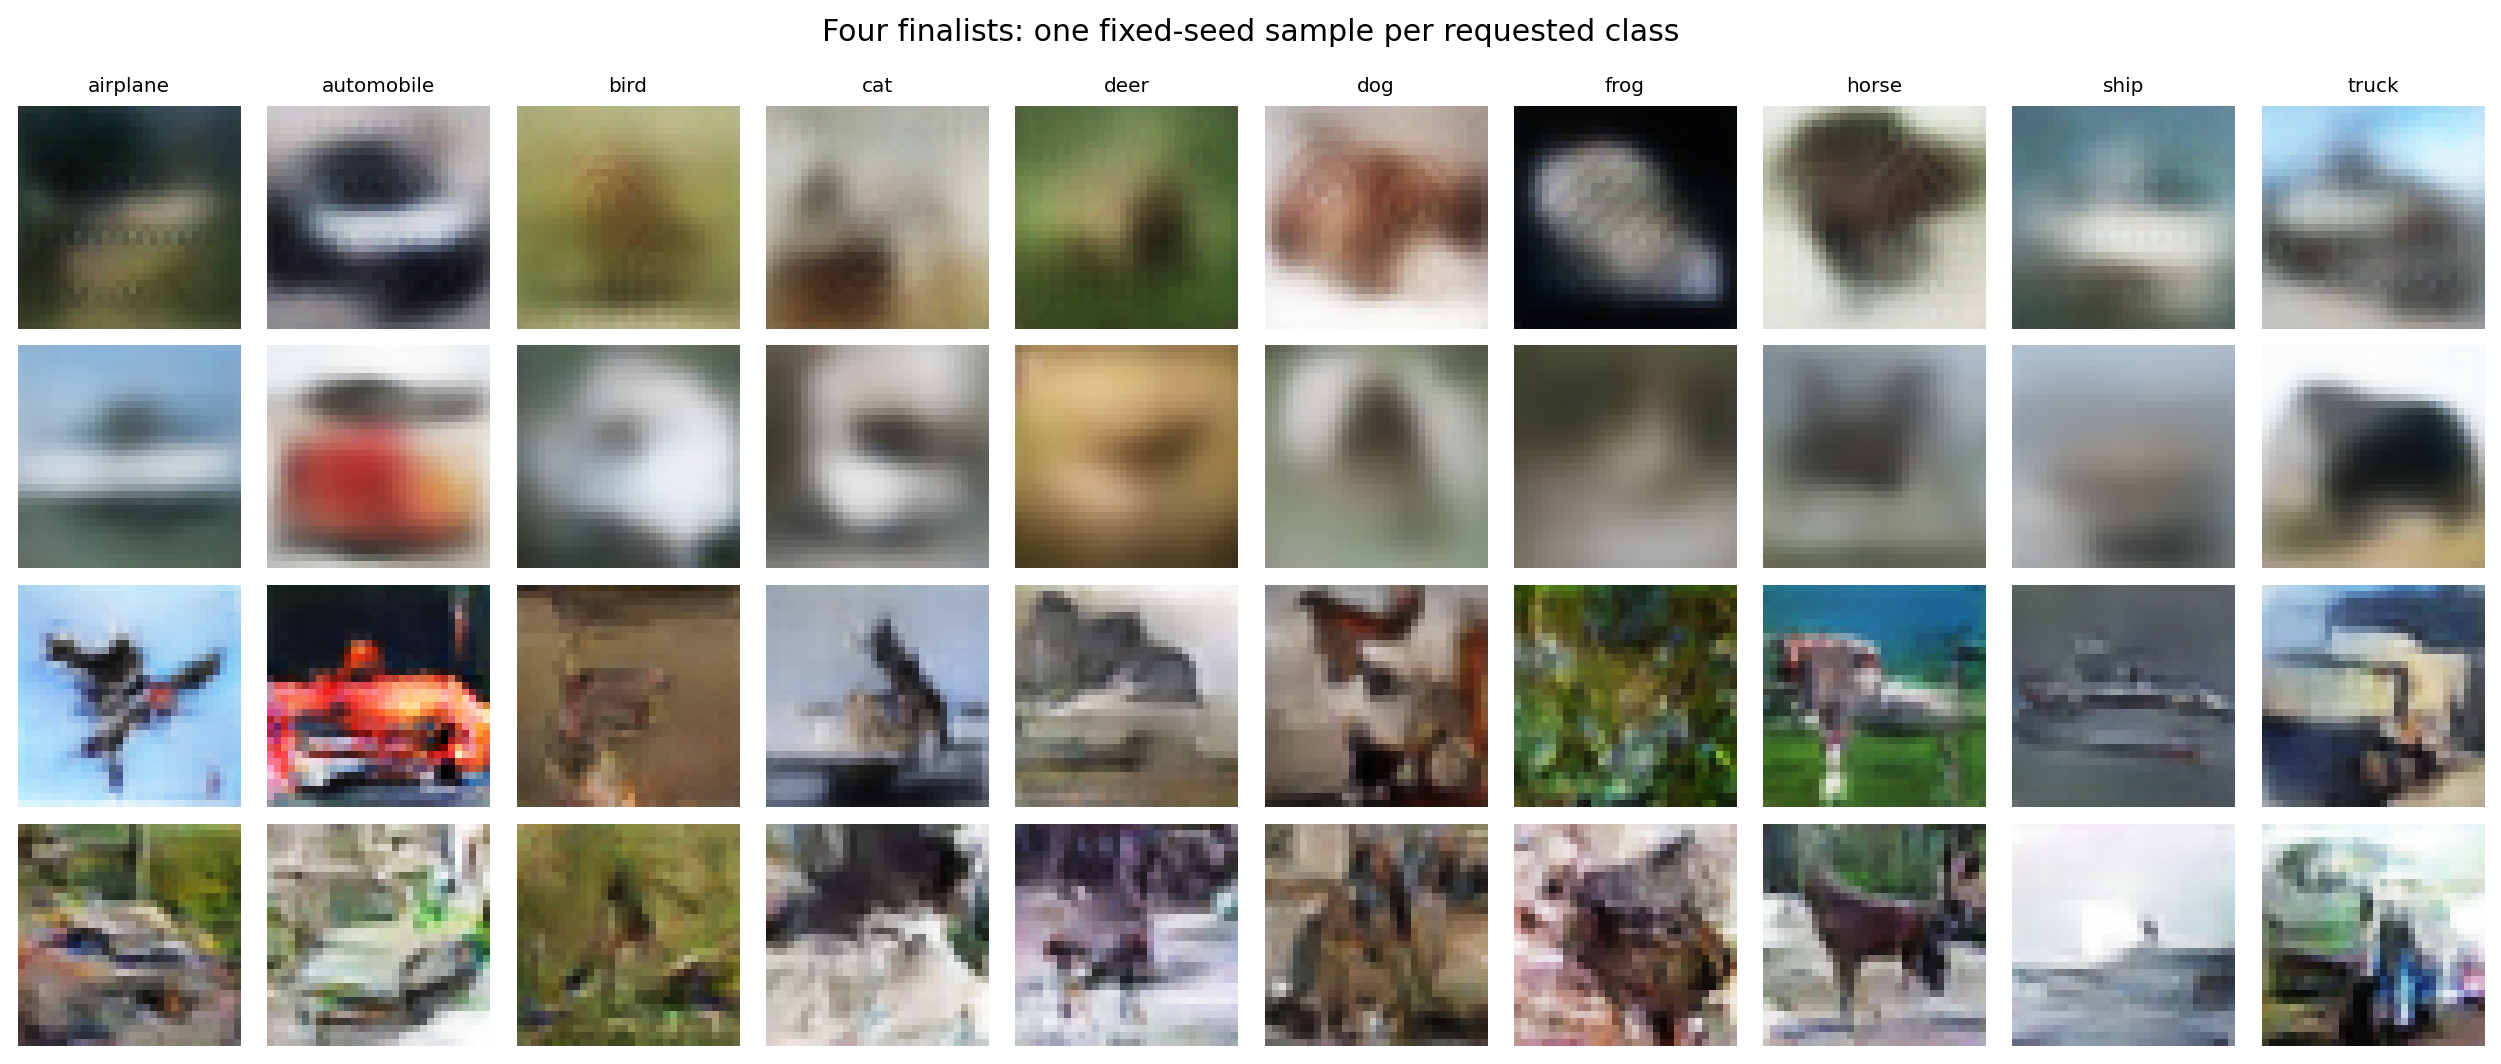

In [24]:
# Purpose: Display one matched fixed-seed sample per class from all four finalists.
if _review_is_active():
    _review_png(
        "four_model_direct_comparison.png",
        "Four finalists — direct fixed-seed comparison",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

The fixed-seed comparison supports the quantitative results. The VAE outputs
are generally smoother and blurrier, while the GAN outputs show sharper edges,
stronger local texture and more recognisable object structure. The comparison
also makes class-control differences visible because every finalist receives a
matched requested-class setup rather than hand-picked examples.

This visual evidence is used as supporting evidence rather than as a replacement
for FID, IS and classifier-based class-control metrics.


## 18.3 FID@5k comparison


### FID@5k comparison — lower is better

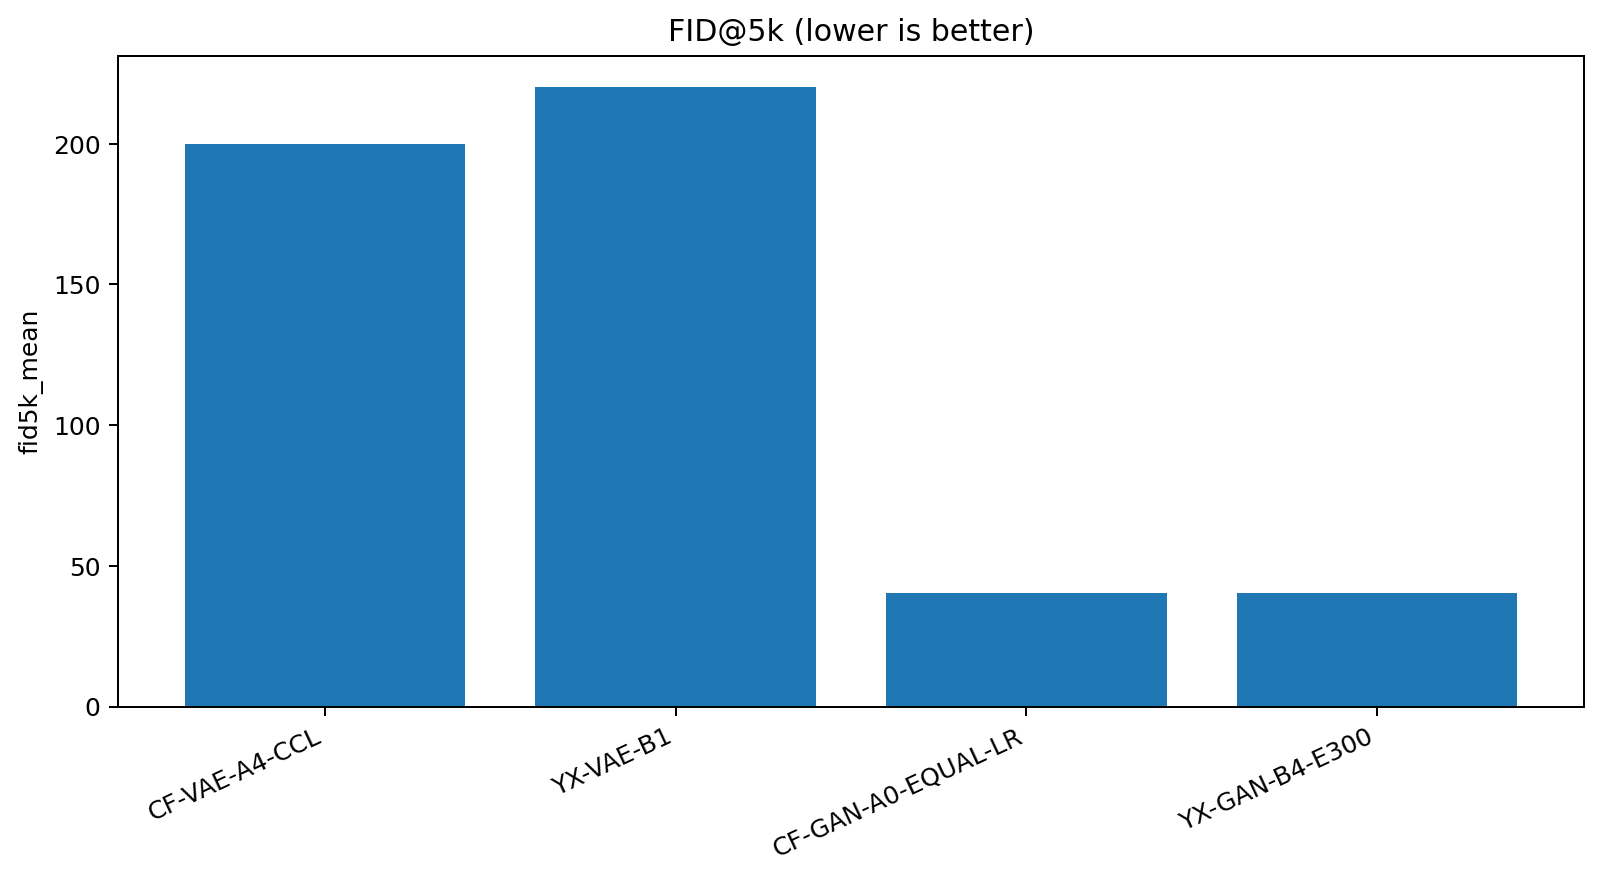

In [25]:
# Purpose: Display the saved FID comparison; lower values indicate better distribution similarity.
if _review_is_active():
    _review_png("fid_comparison.png", "FID@5k comparison — lower is better")
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`CF-VAE-A4-CCL` clearly outperforms `YX-VAE-B1` on FID
(**200.076 ± 0.413** versus **220.318 ± 0.607**).

For the GANs, `YX-GAN-B4-E300` records **40.429 ± 0.388** and
`CF-GAN-A0-EQUAL-LR` records **40.492 ± 0.478**. The difference is only about
0.064, which is much smaller than the repeat-to-repeat standard deviations.
Therefore, the GAN FID results should be treated as **effectively tied**, not
as a meaningful win for either model.


## 18.4 Inception Score comparison


### Inception Score comparison — higher is better

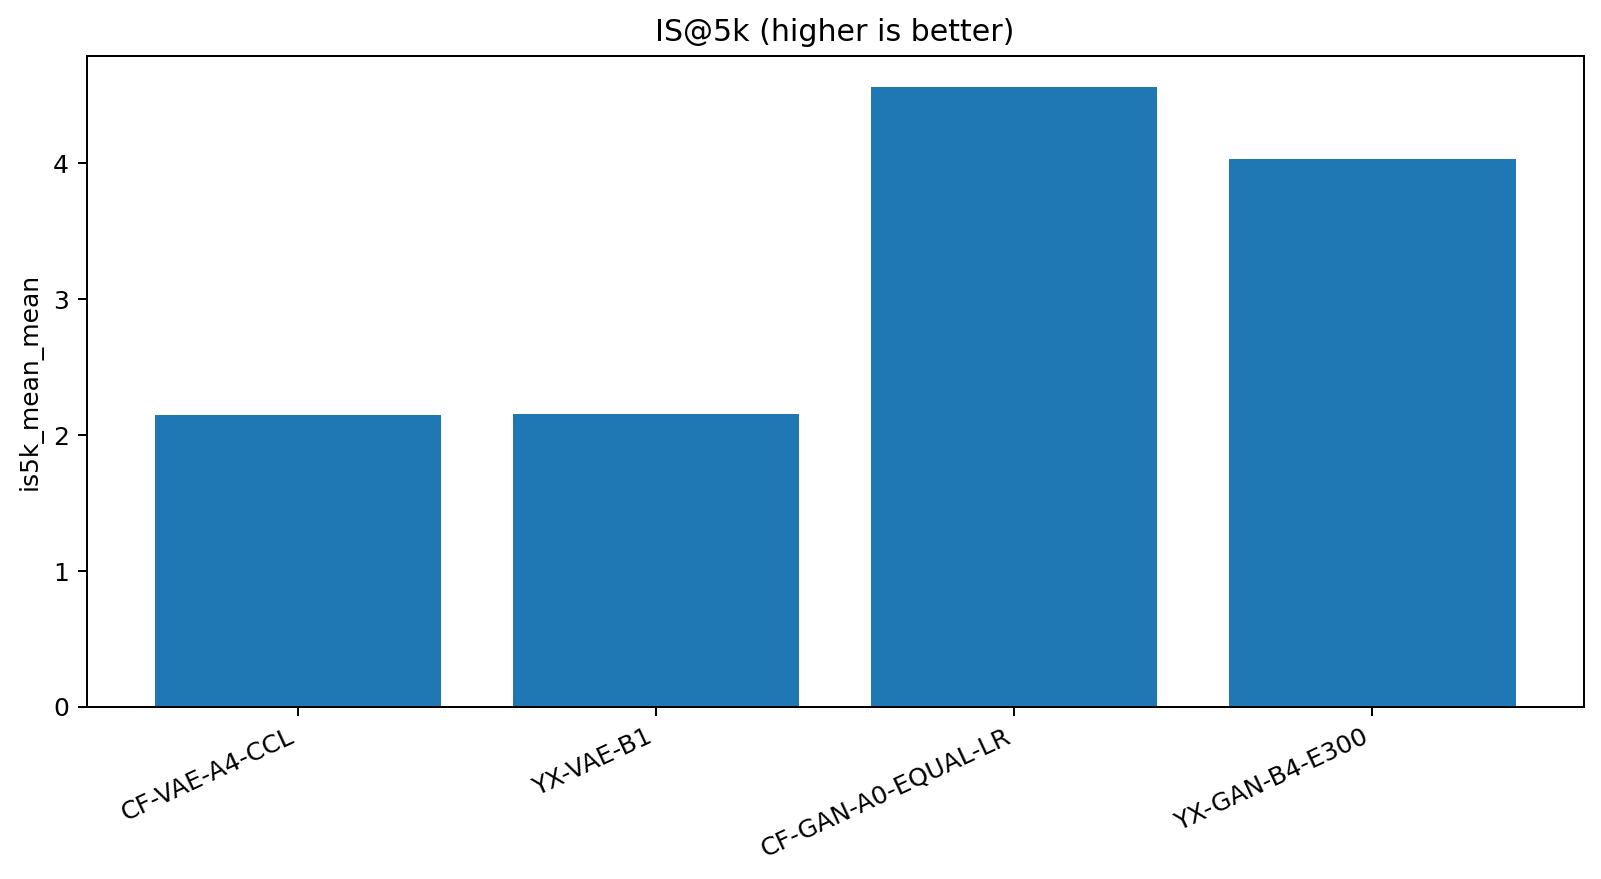

In [26]:
# Purpose: Display the saved Inception Score comparison; higher values support quality/diversity.
if _review_is_active():
    _review_png("is_comparison.png", "Inception Score comparison — higher is better")
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`CF-GAN-A0-EQUAL-LR` has the strongest Inception Score at
**4.567 ± 0.016**, compared with **4.033 ± 0.046** for
`YX-GAN-B4-E300`. This is an important advantage for Chun Fei's GAN and is
retained as part of the final trade-off.

For the VAEs, `YX-VAE-B1` has only a very small IS advantage
(**2.157 ± 0.015** versus **2.146 ± 0.018**), which is not large enough to
offset its much weaker FID and class control.


## 18.5 Requested-class control

These two graphs measure the same idea from complementary angles, so they are
kept together: whether the generated image matches the requested class, and
how confidently the evaluator assigns that requested class.


### Requested-class accuracy comparison

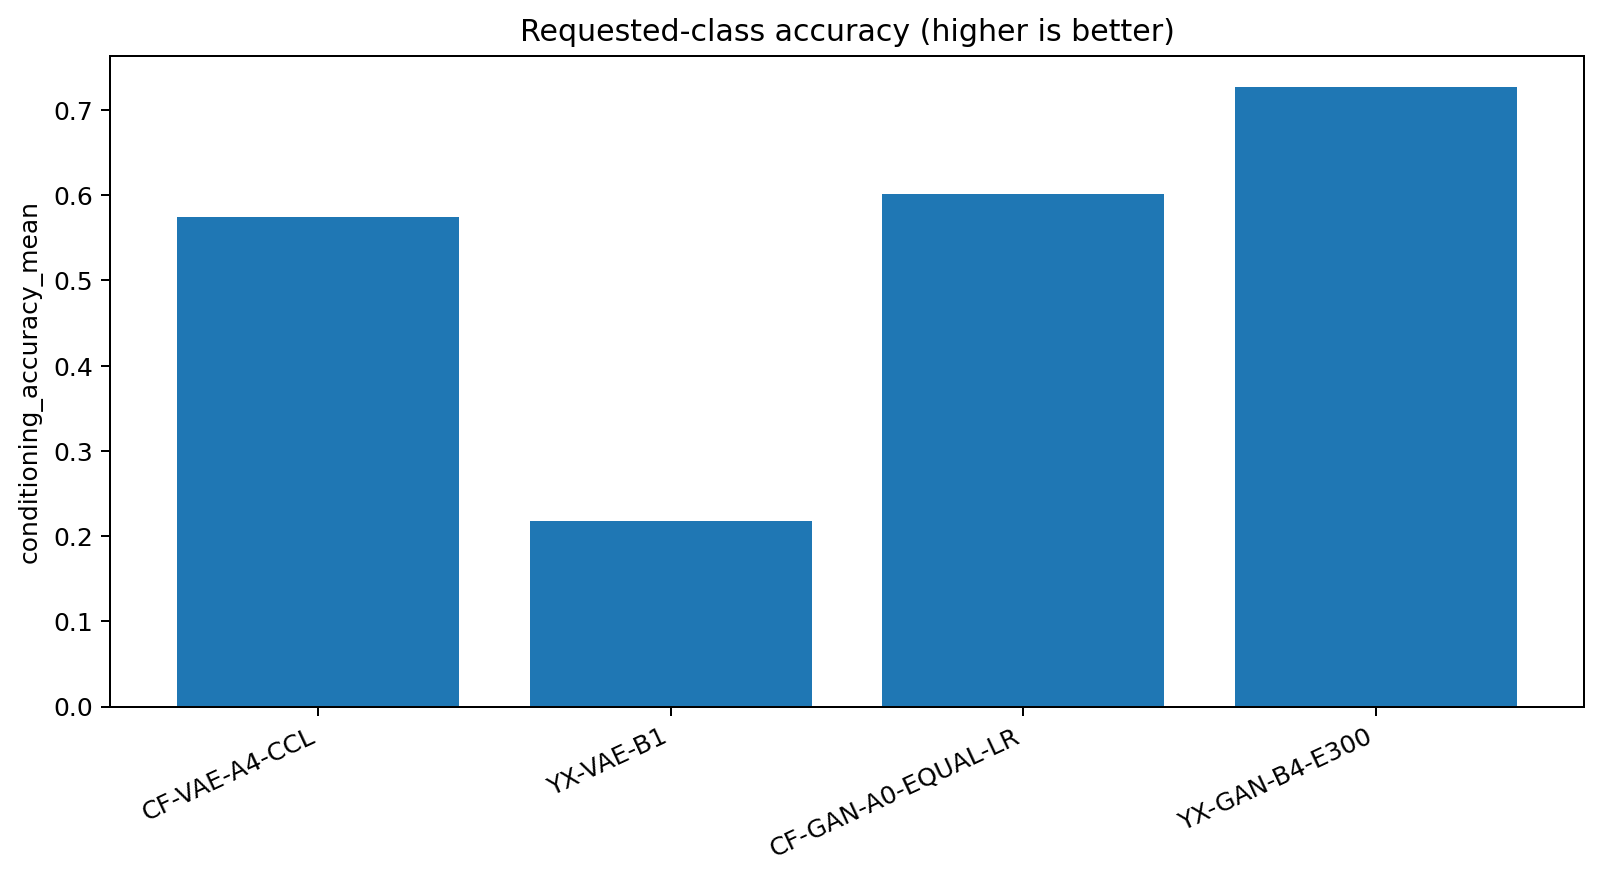

### Requested-class confidence comparison

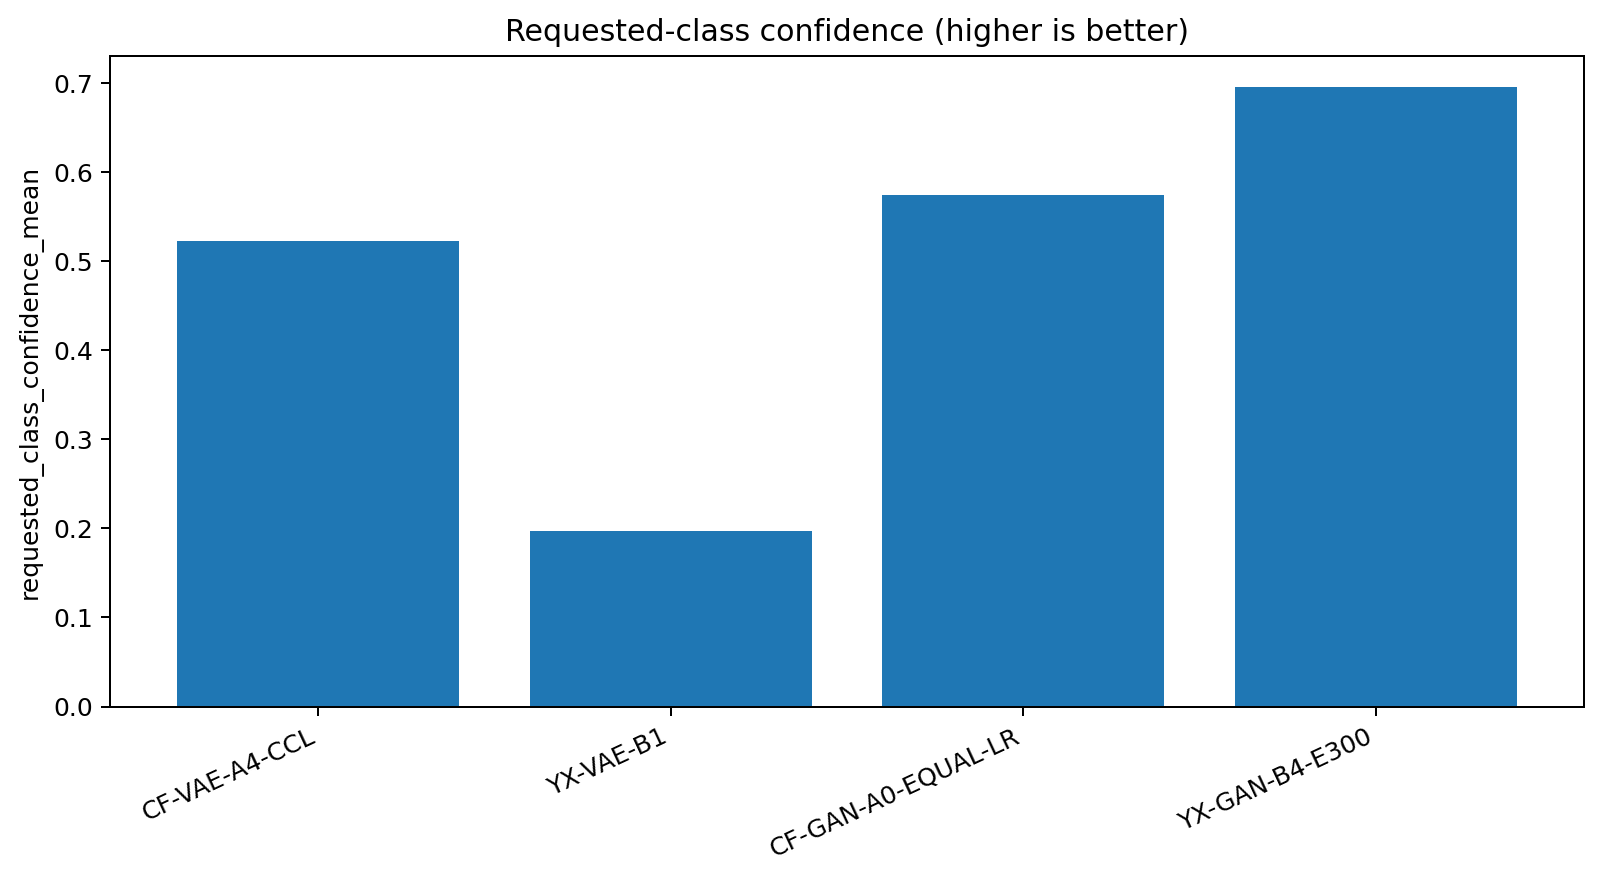

In [27]:
# Purpose: Display the two complementary requested-class control graphs together.
if _review_is_active():
    _review_png(
        "conditioning_accuracy_comparison.png",
        "Requested-class accuracy comparison",
    )
    _review_png(
        "requested_confidence_comparison.png",
        "Requested-class confidence comparison",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

Class control strongly separates the finalists.

- `CF-VAE-A4-CCL`: **57.45%** conditioning accuracy and **52.26%**
  requested-class confidence.
- `YX-VAE-B1`: **21.73%** accuracy and **19.65%** confidence.
- `CF-GAN-A0-EQUAL-LR`: **60.16%** accuracy and **57.45%** confidence.
- `YX-GAN-B4-E300`: **72.75%** accuracy and **69.59%** confidence.

`YX-GAN-B4-E300` has the strongest class controllability of all four
finalists. Because the goal is generation across ten named
CIFAR-10 classes, this is a central reason for selecting it over
`CF-GAN-A0-EQUAL-LR` when their FID results are effectively tied.


## 18.6 Per-class accuracy and confidence

These two plots are directly related and are therefore shown together.


### Per-class requested-label accuracy

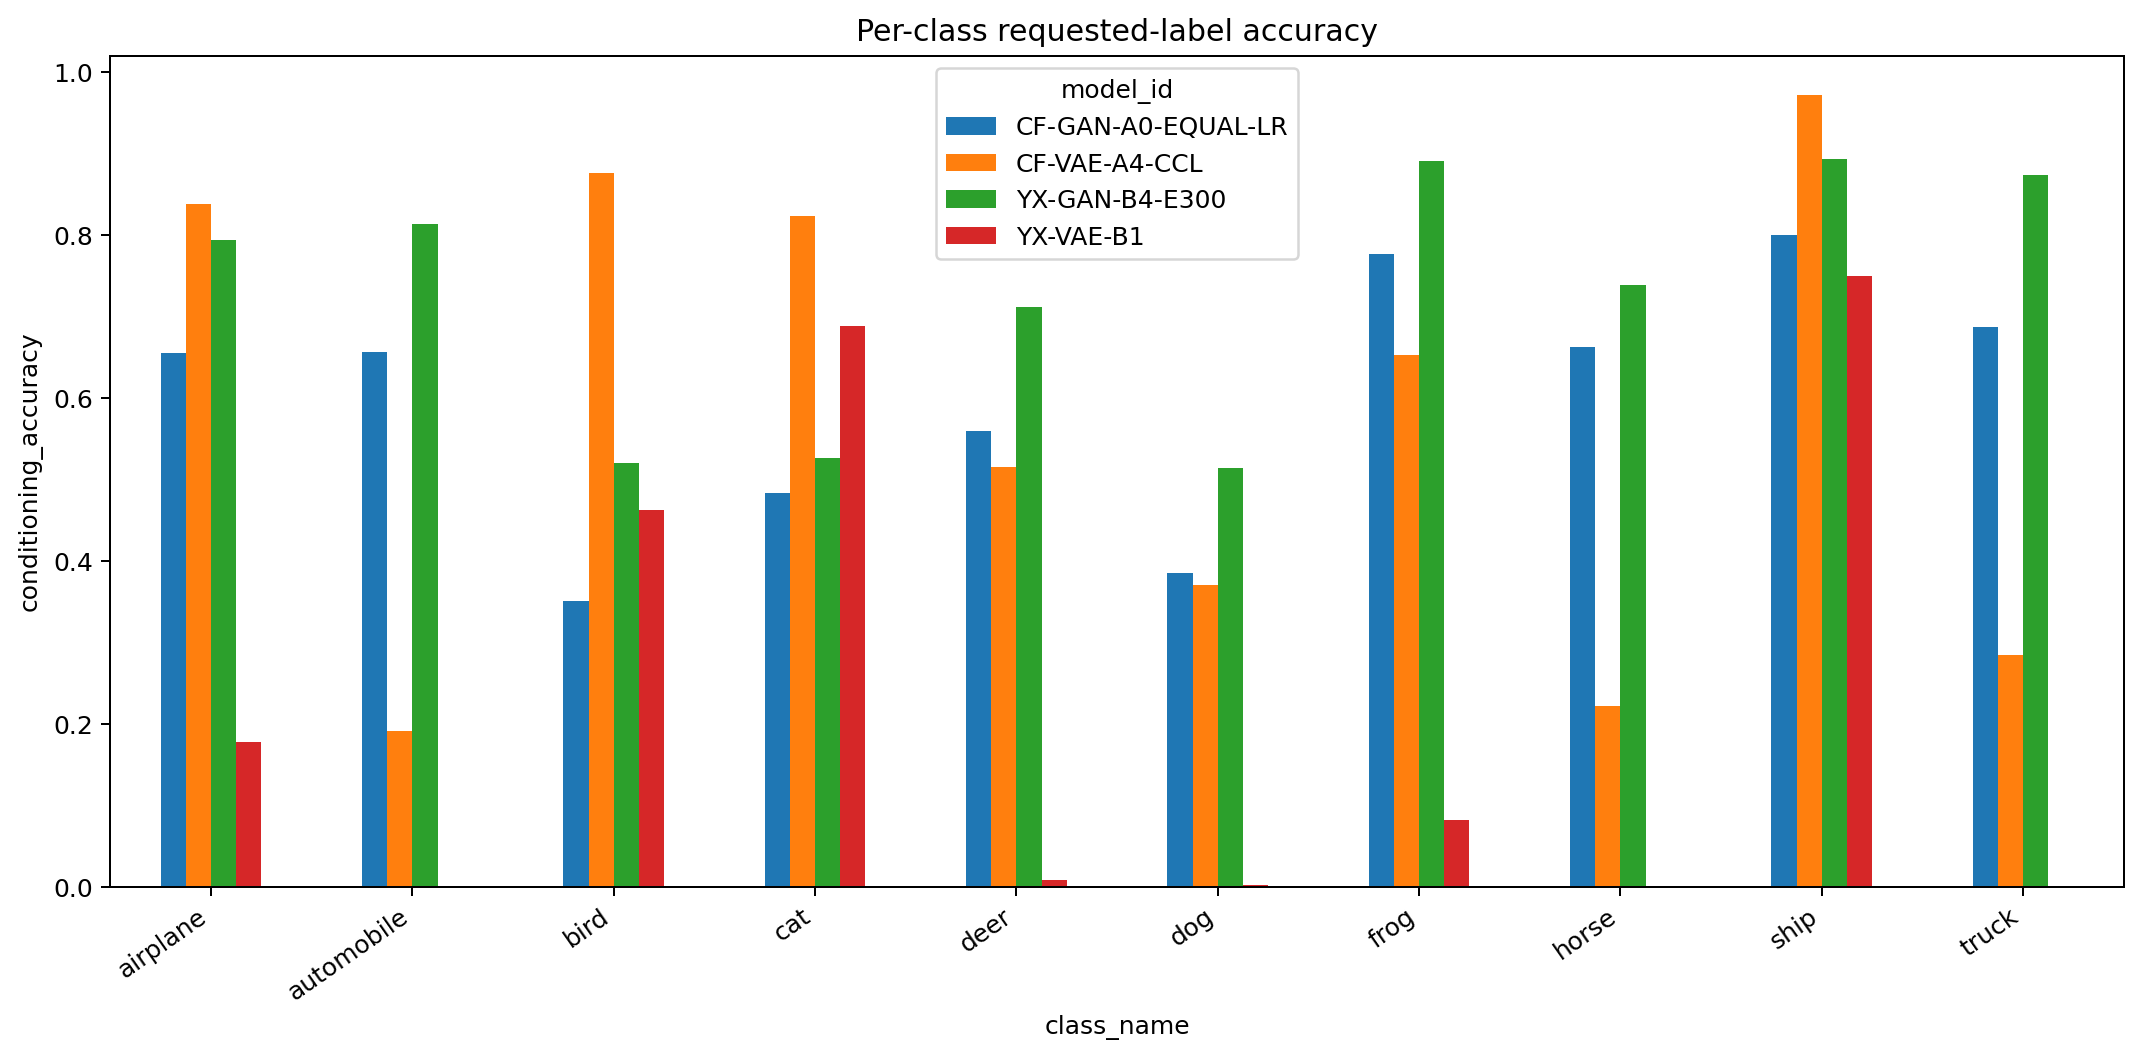

### Per-class requested-label confidence

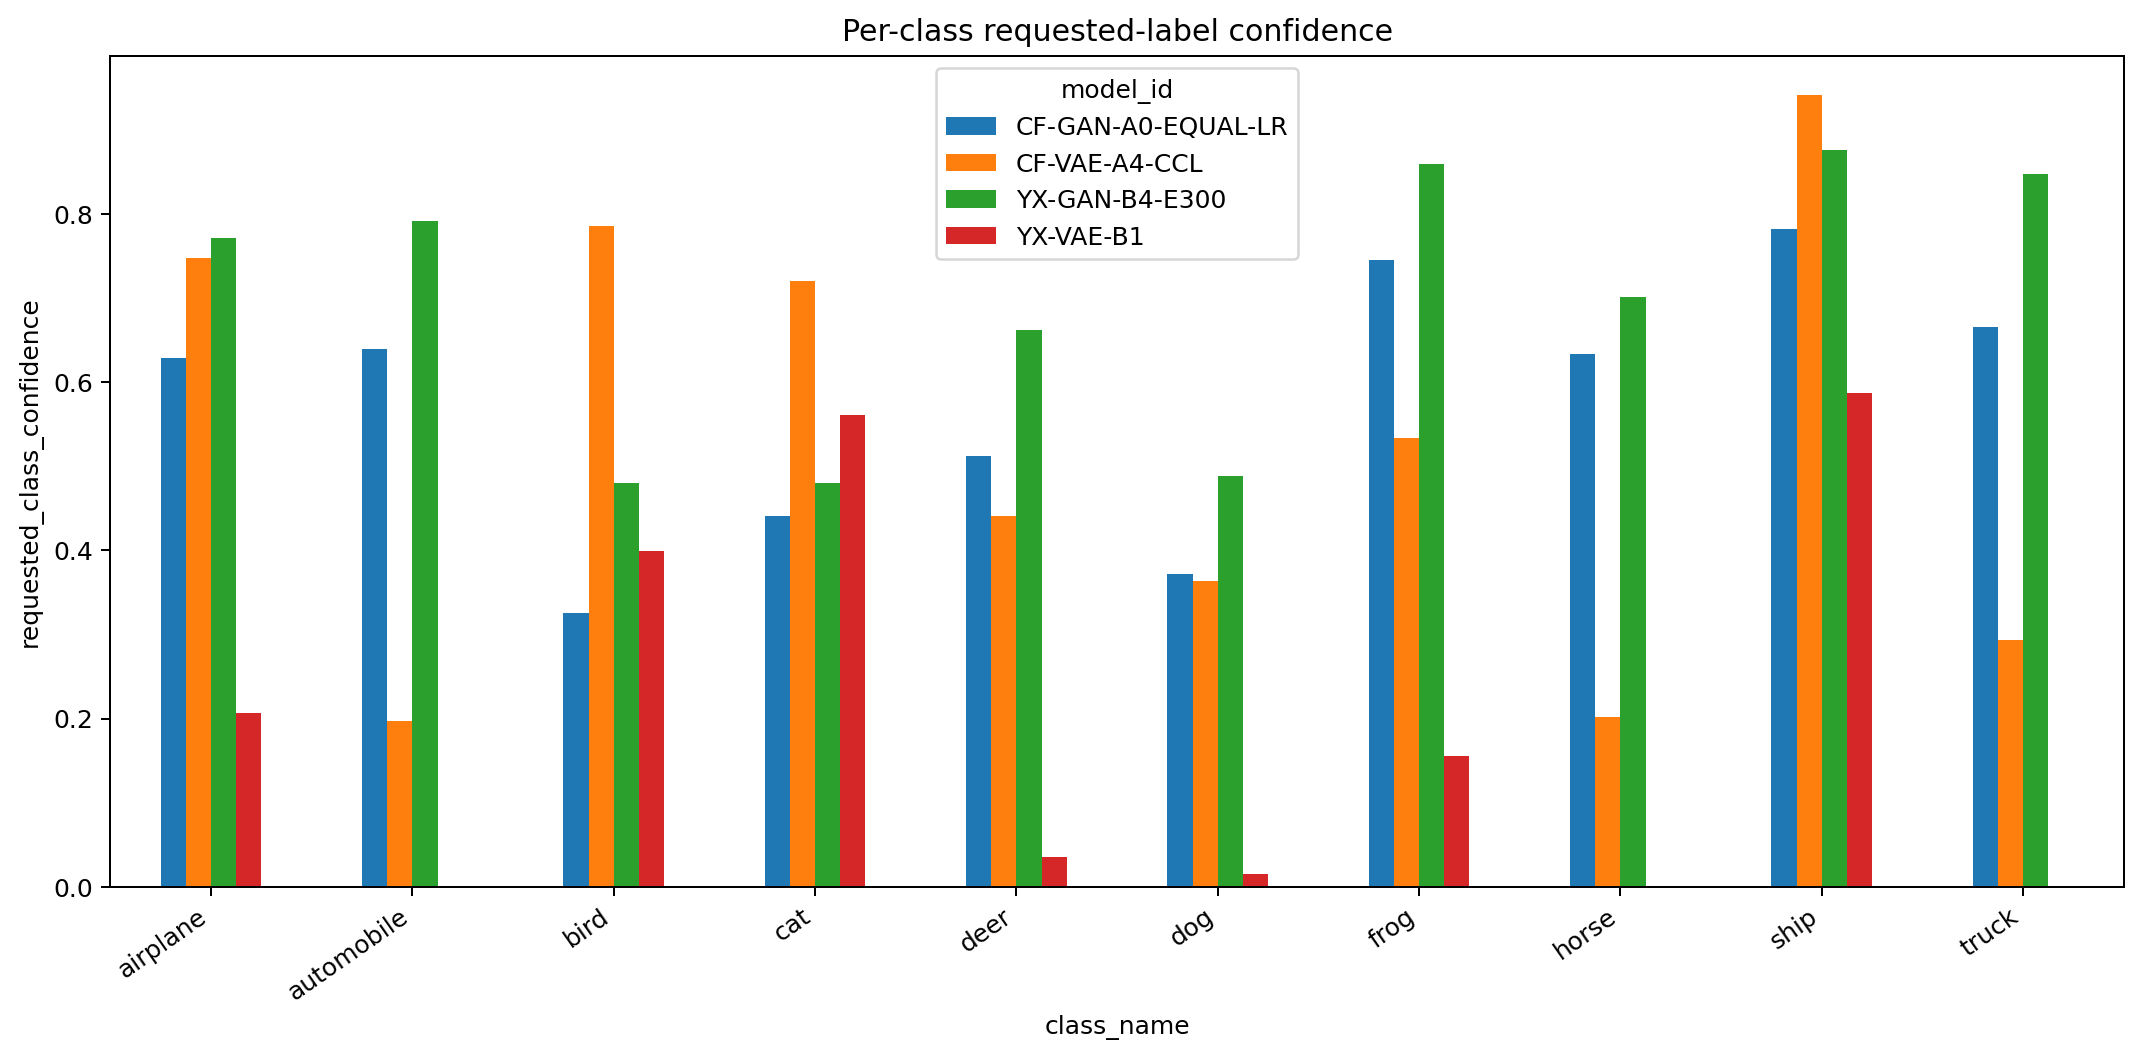

In [28]:
# Purpose: Display per-class accuracy and confidence to identify class-specific strengths and weaknesses.
if _review_is_active():
    _review_png(
        "per_class_accuracy.png",
        "Per-class requested-label accuracy",
    )
    _review_png(
        "per_class_confidence.png",
        "Per-class requested-label confidence",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

Across the four finalists, **ship is the easiest class overall**, reaching
**85.37% mean conditioning accuracy**, while **dog is the hardest overall** at
**31.78%**.

Ship is the easiest class for every finalist, suggesting that its broad
large-scale structure is more consistently captured by these models. Dog is
much less reliable, particularly because animal categories can share similar
coarse shapes, textures, poses and backgrounds at CIFAR-10's 32×32 resolution.

The per-class confidence plot supports the same conclusion by showing that
strong classes are not only predicted correctly more often but also tend to
receive stronger probability for the requested label.


## 18.7 Easiest/hardest-class summary tables


In [29]:
# Purpose: Display the saved easiest/hardest-class and common-confusion summary tables.
if _review_is_active():
    _review_csv(
        "model_easiest_hardest_classes.csv",
        "Easiest and hardest class for each finalist",
    )
    _review_csv(
        "overall_class_difficulty.csv",
        "Average class difficulty across finalists",
    )
    _review_csv(
        "most_common_class_confusions.csv",
        "Most common wrong prediction by finalist",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Easiest and hardest class for each finalist

,model_id,easiest_class,easiest_accuracy,easiest_requested_confidence,hardest_class,hardest_accuracy,hardest_requested_confidence
0,CF-GAN-A0-EQUAL-LR,ship,0.8000,0.782669,bird,0.3504,0.325576
1,CF-VAE-A4-CCL,ship,0.9712,0.940925,automobile,0.1908,0.197741
2,YX-GAN-B4-E300,ship,0.8936,0.876482,dog,0.5136,0.487955
3,YX-VAE-B1,ship,0.7500,0.587039,horse,0.0000,0.000789


### Average class difficulty across finalists

,class_id,class_name,mean_conditioning_accuracy,mean_requested_confidence,models_evaluated
0,8,ship,0.8537,0.796779,4
1,3,cat,0.6302,0.550794,4
2,0,airplane,0.6161,0.588745,4
3,6,frog,0.6007,0.573350,4
4,2,bird,0.5523,0.497959,4
5,9,truck,0.4615,0.452127,4
6,4,deer,0.4488,0.412728,4
7,1,automobile,0.4153,0.407352,4
8,7,horse,0.4058,0.384409,4
9,5,dog,0.3178,0.309679,4


### Most common wrong prediction by finalist

,model_id,requested_class,most_common_wrong_prediction,count
0,CF-GAN-A0-EQUAL-LR,dog,cat,665
1,CF-VAE-A4-CCL,truck,ship,1346
2,YX-GAN-B4-E300,dog,cat,641
3,YX-VAE-B1,dog,cat,1679


### Evaluation

The per-model extremes show that class difficulty is partly model-dependent:

| Finalist | Easiest | Hardest |
|---|---|---|
| `CF-VAE-A4-CCL` | ship (97.12%) | automobile (19.08%) |
| `YX-VAE-B1` | ship (75.00%) | horse (0.00%) |
| `CF-GAN-A0-EQUAL-LR` | ship (80.00%) | bird (35.04%) |
| `YX-GAN-B4-E300` | ship (89.36%) | dog (51.36%) |

Therefore, the group-level conclusion is not that every model struggles with
exactly the same class. Instead, **ship is consistently easiest**, while the
harder classes vary across architectures, with dog being the weakest class on
average.


## 18.8 CF-VAE-A4-CCL confusion matrix


### CF-VAE-A4-CCL — confusion matrix

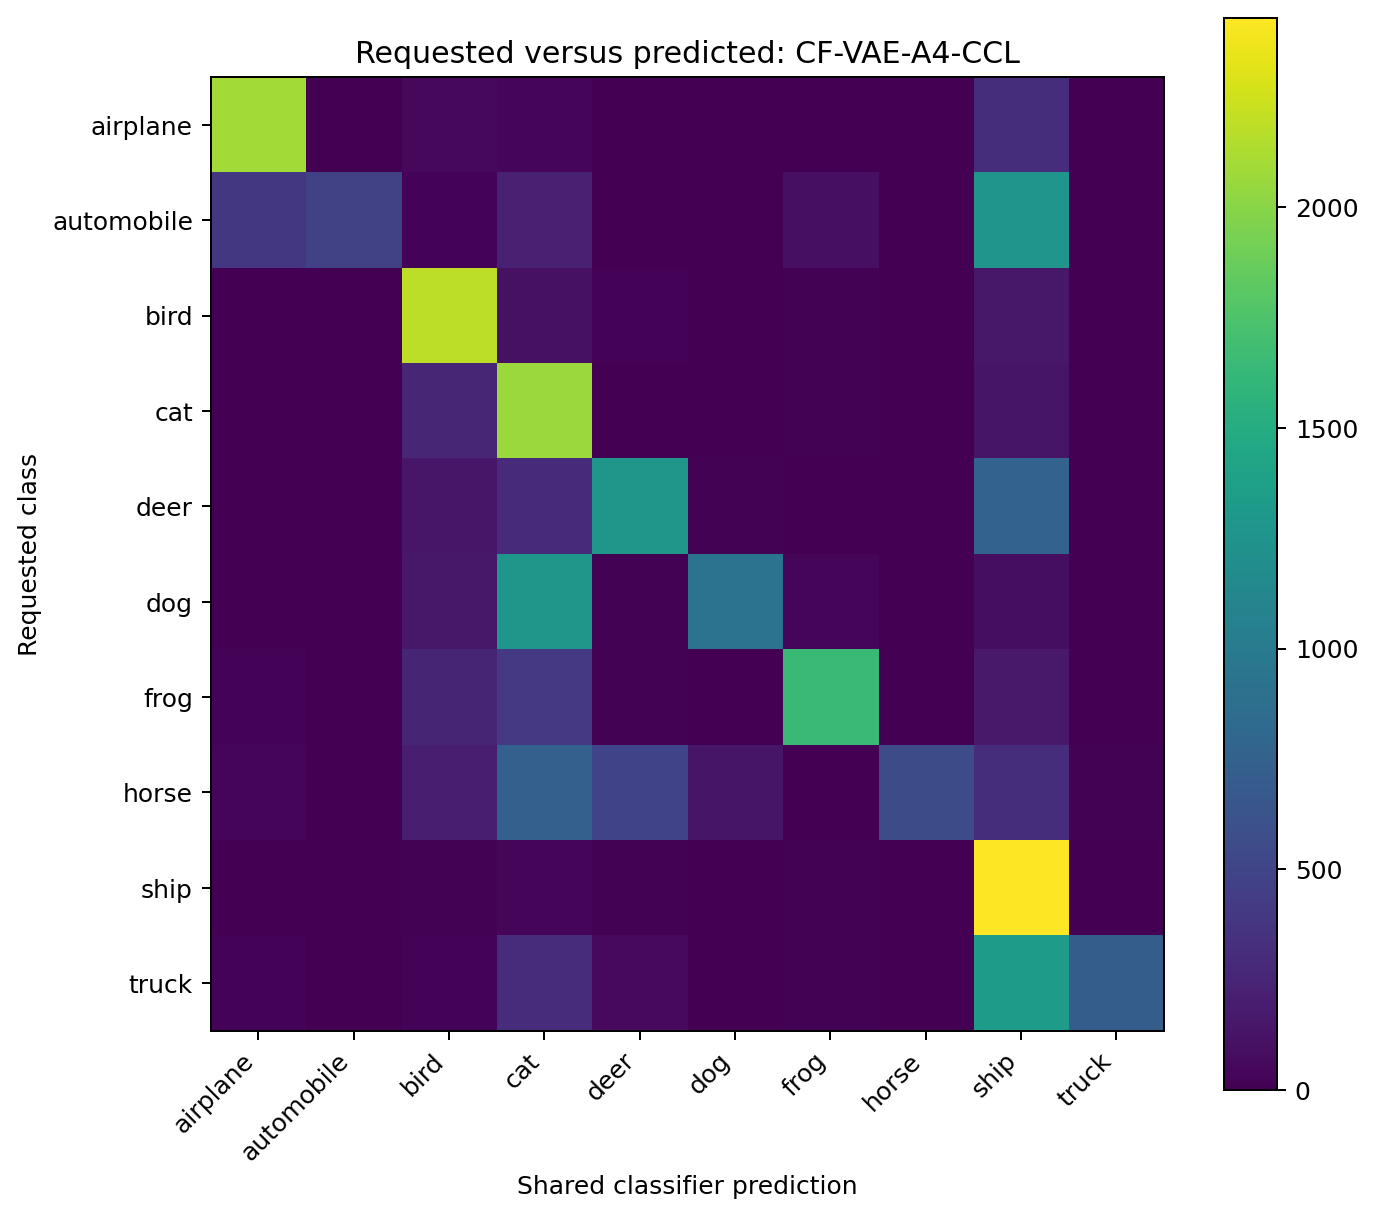

In [30]:
# Purpose: Display Chun Fei VAE A4's confusion matrix for class-specific error analysis.
if _review_is_active():
    _review_png(
        "CF-VAE-A4-CCL_confusion_matrix.png",
        "CF-VAE-A4-CCL — confusion matrix",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`CF-VAE-A4-CCL` does not follow the same dominant error pattern as the other
three finalists. Its most common confusion is **truck → ship**. This suggests
that the model sometimes preserves broad vehicle/large-object structure while
losing the finer cues needed to separate road vehicles from ship-like
silhouettes.


## 18.9 YX-VAE-B1 confusion matrix


### YX-VAE-B1 — confusion matrix

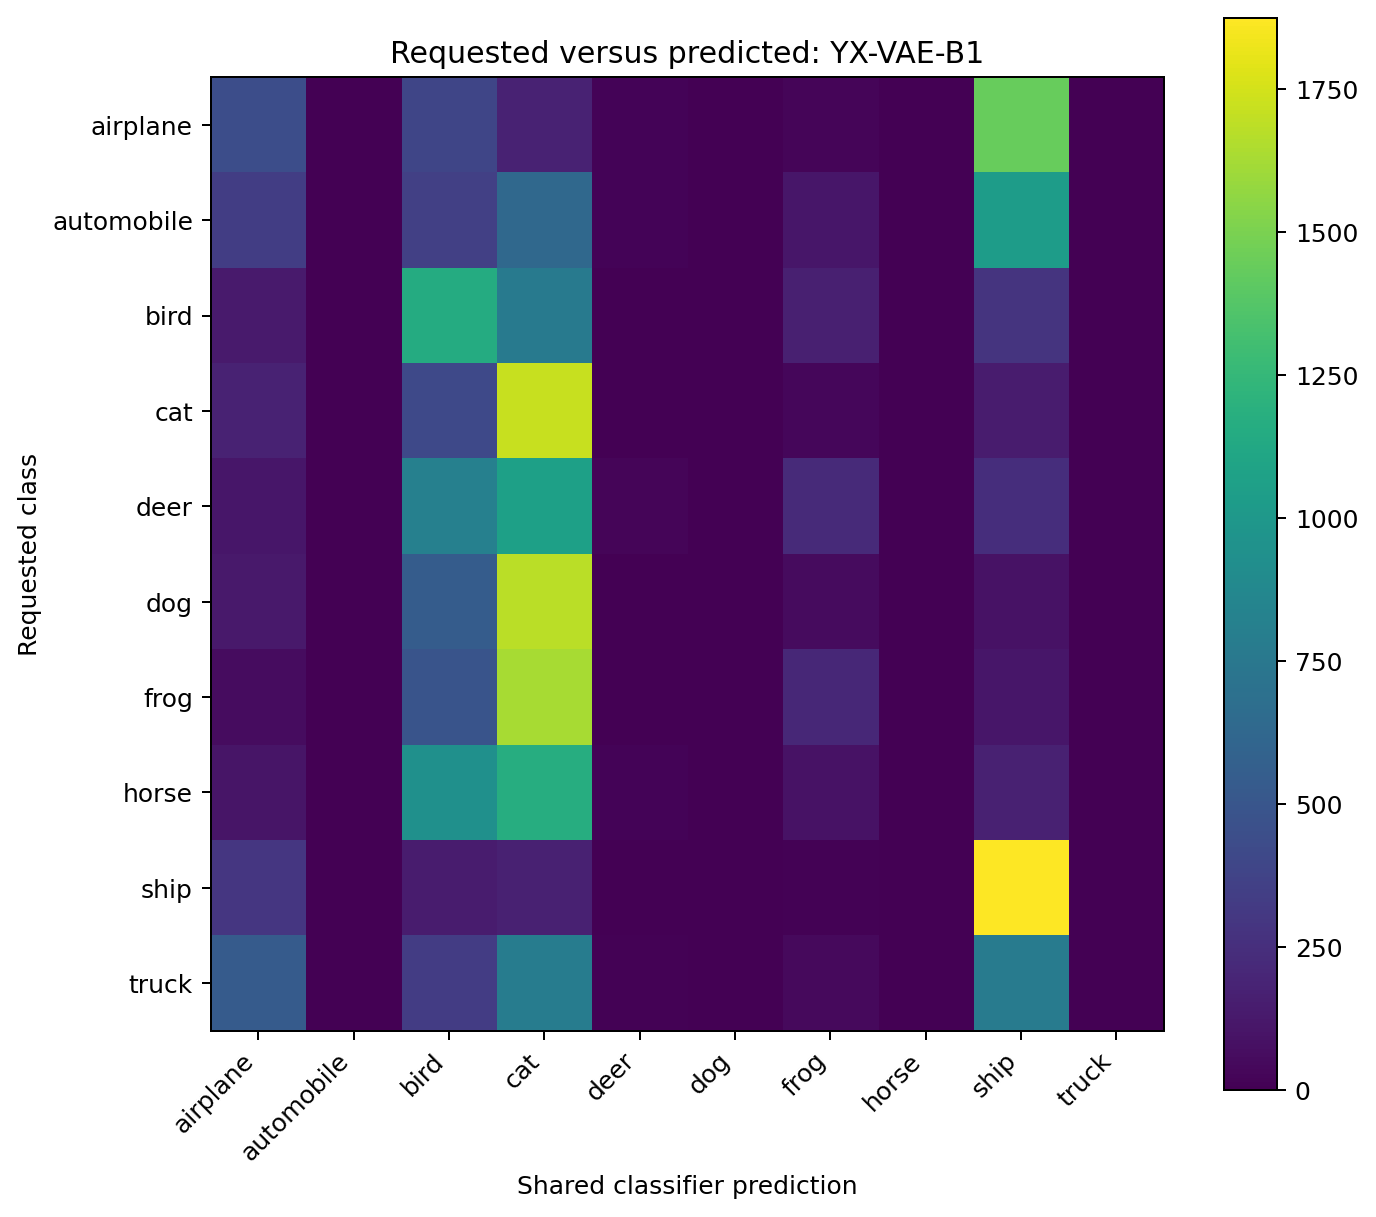

In [31]:
# Purpose: Display You Xuan VAE B1's confusion matrix for class-specific error analysis.
if _review_is_active():
    _review_png(
        "YX-VAE-B1_confusion_matrix.png",
        "YX-VAE-B1 — confusion matrix",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`YX-VAE-B1` shows very weak class control overall and its hardest class is
horse, where conditioning accuracy reaches 0%. Its dominant confusion includes
**dog → cat**, which is consistent with the broader difficulty of separating
similar animal categories at 32×32 resolution.


## 18.10 CF-GAN-A0-EQUAL-LR confusion matrix


### CF-GAN-A0-EQUAL-LR — confusion matrix

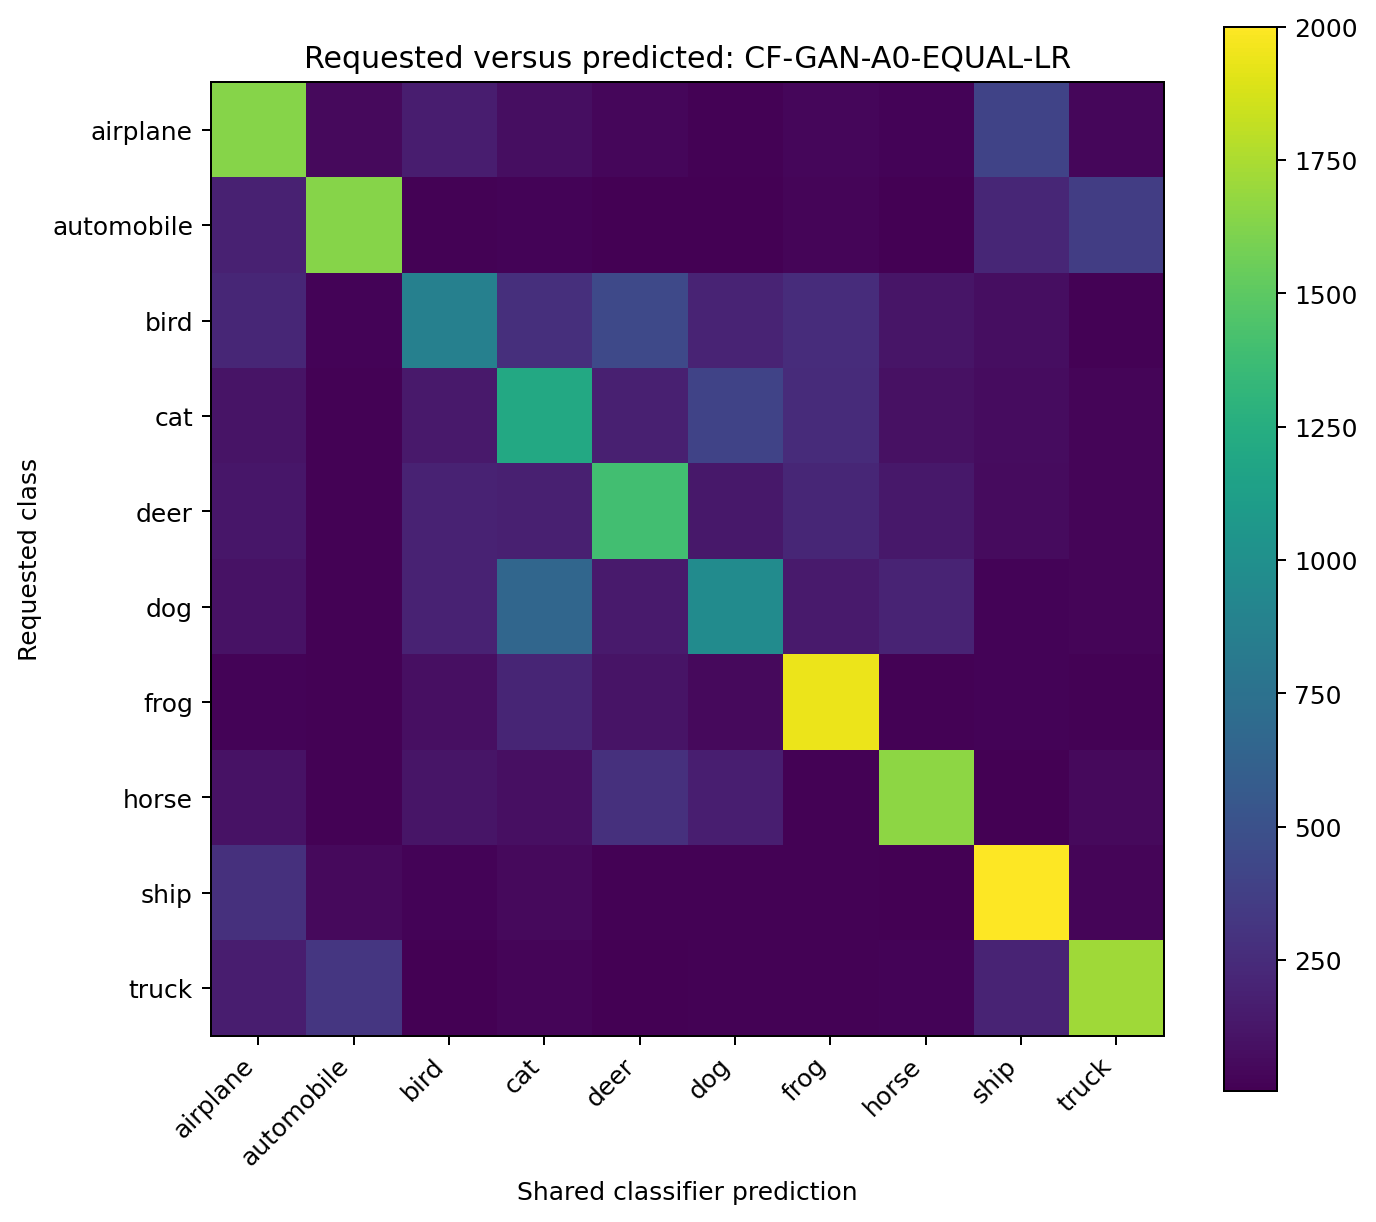

In [32]:
# Purpose: Display Chun Fei GAN A0's confusion matrix for class-specific error analysis.
if _review_is_active():
    _review_png(
        "CF-GAN-A0-EQUAL-LR_confusion_matrix.png",
        "CF-GAN-A0-EQUAL-LR — confusion matrix",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`CF-GAN-A0-EQUAL-LR` has much stronger generation quality than the VAEs, but
its class control is weaker than `YX-GAN-B4-E300`. A repeated error is
**dog → cat**, showing that sharpness and good FID/IS do not guarantee perfect
semantic conditioning.


## 18.11 YX-GAN-B4-E300 confusion matrix


### YX-GAN-B4-E300 — confusion matrix

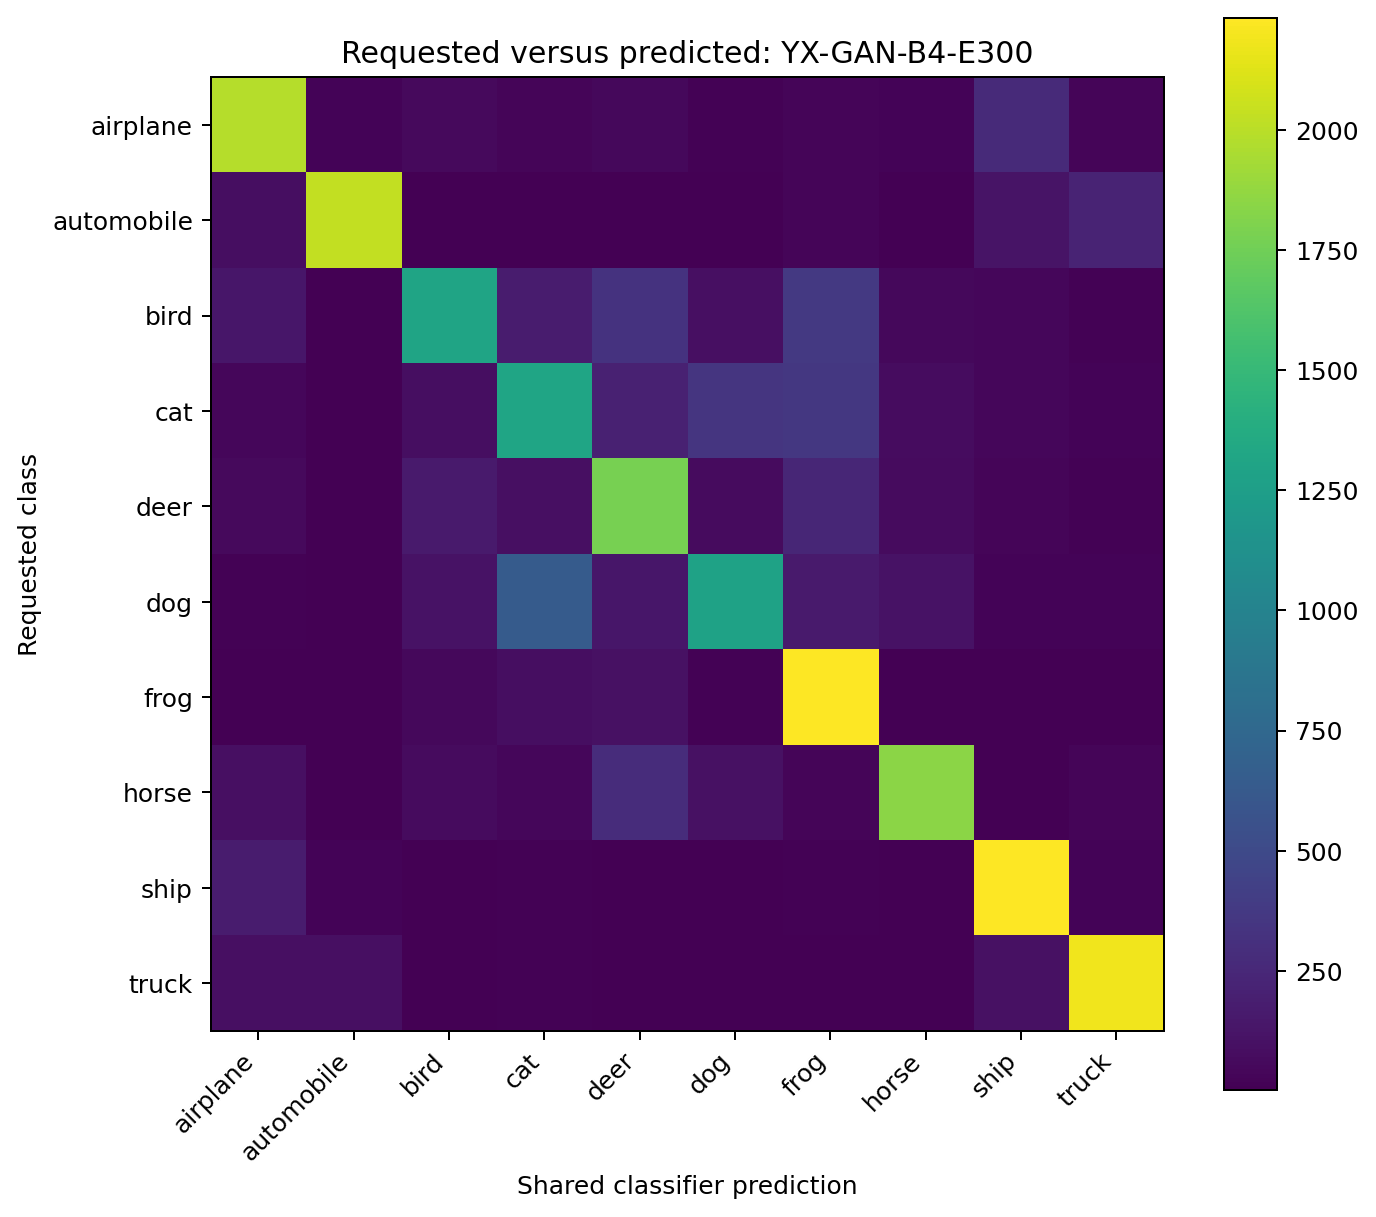

In [33]:
# Purpose: Display You Xuan GAN B4's confusion matrix for class-specific error analysis.
if _review_is_active():
    _review_png(
        "YX-GAN-B4-E300_confusion_matrix.png",
        "YX-GAN-B4-E300 — confusion matrix",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`YX-GAN-B4-E300` has the strongest overall requested-class accuracy, but dog
remains its hardest class and **dog → cat** is still a common confusion. This
shows that the selected winner is not error-free; its advantage is that class
control is stronger overall while maintaining GAN-level FID.


## 18.12 CF-VAE-A4-CCL fixed-seed generated grid


### CF-VAE-A4-CCL — balanced fixed-seed grid

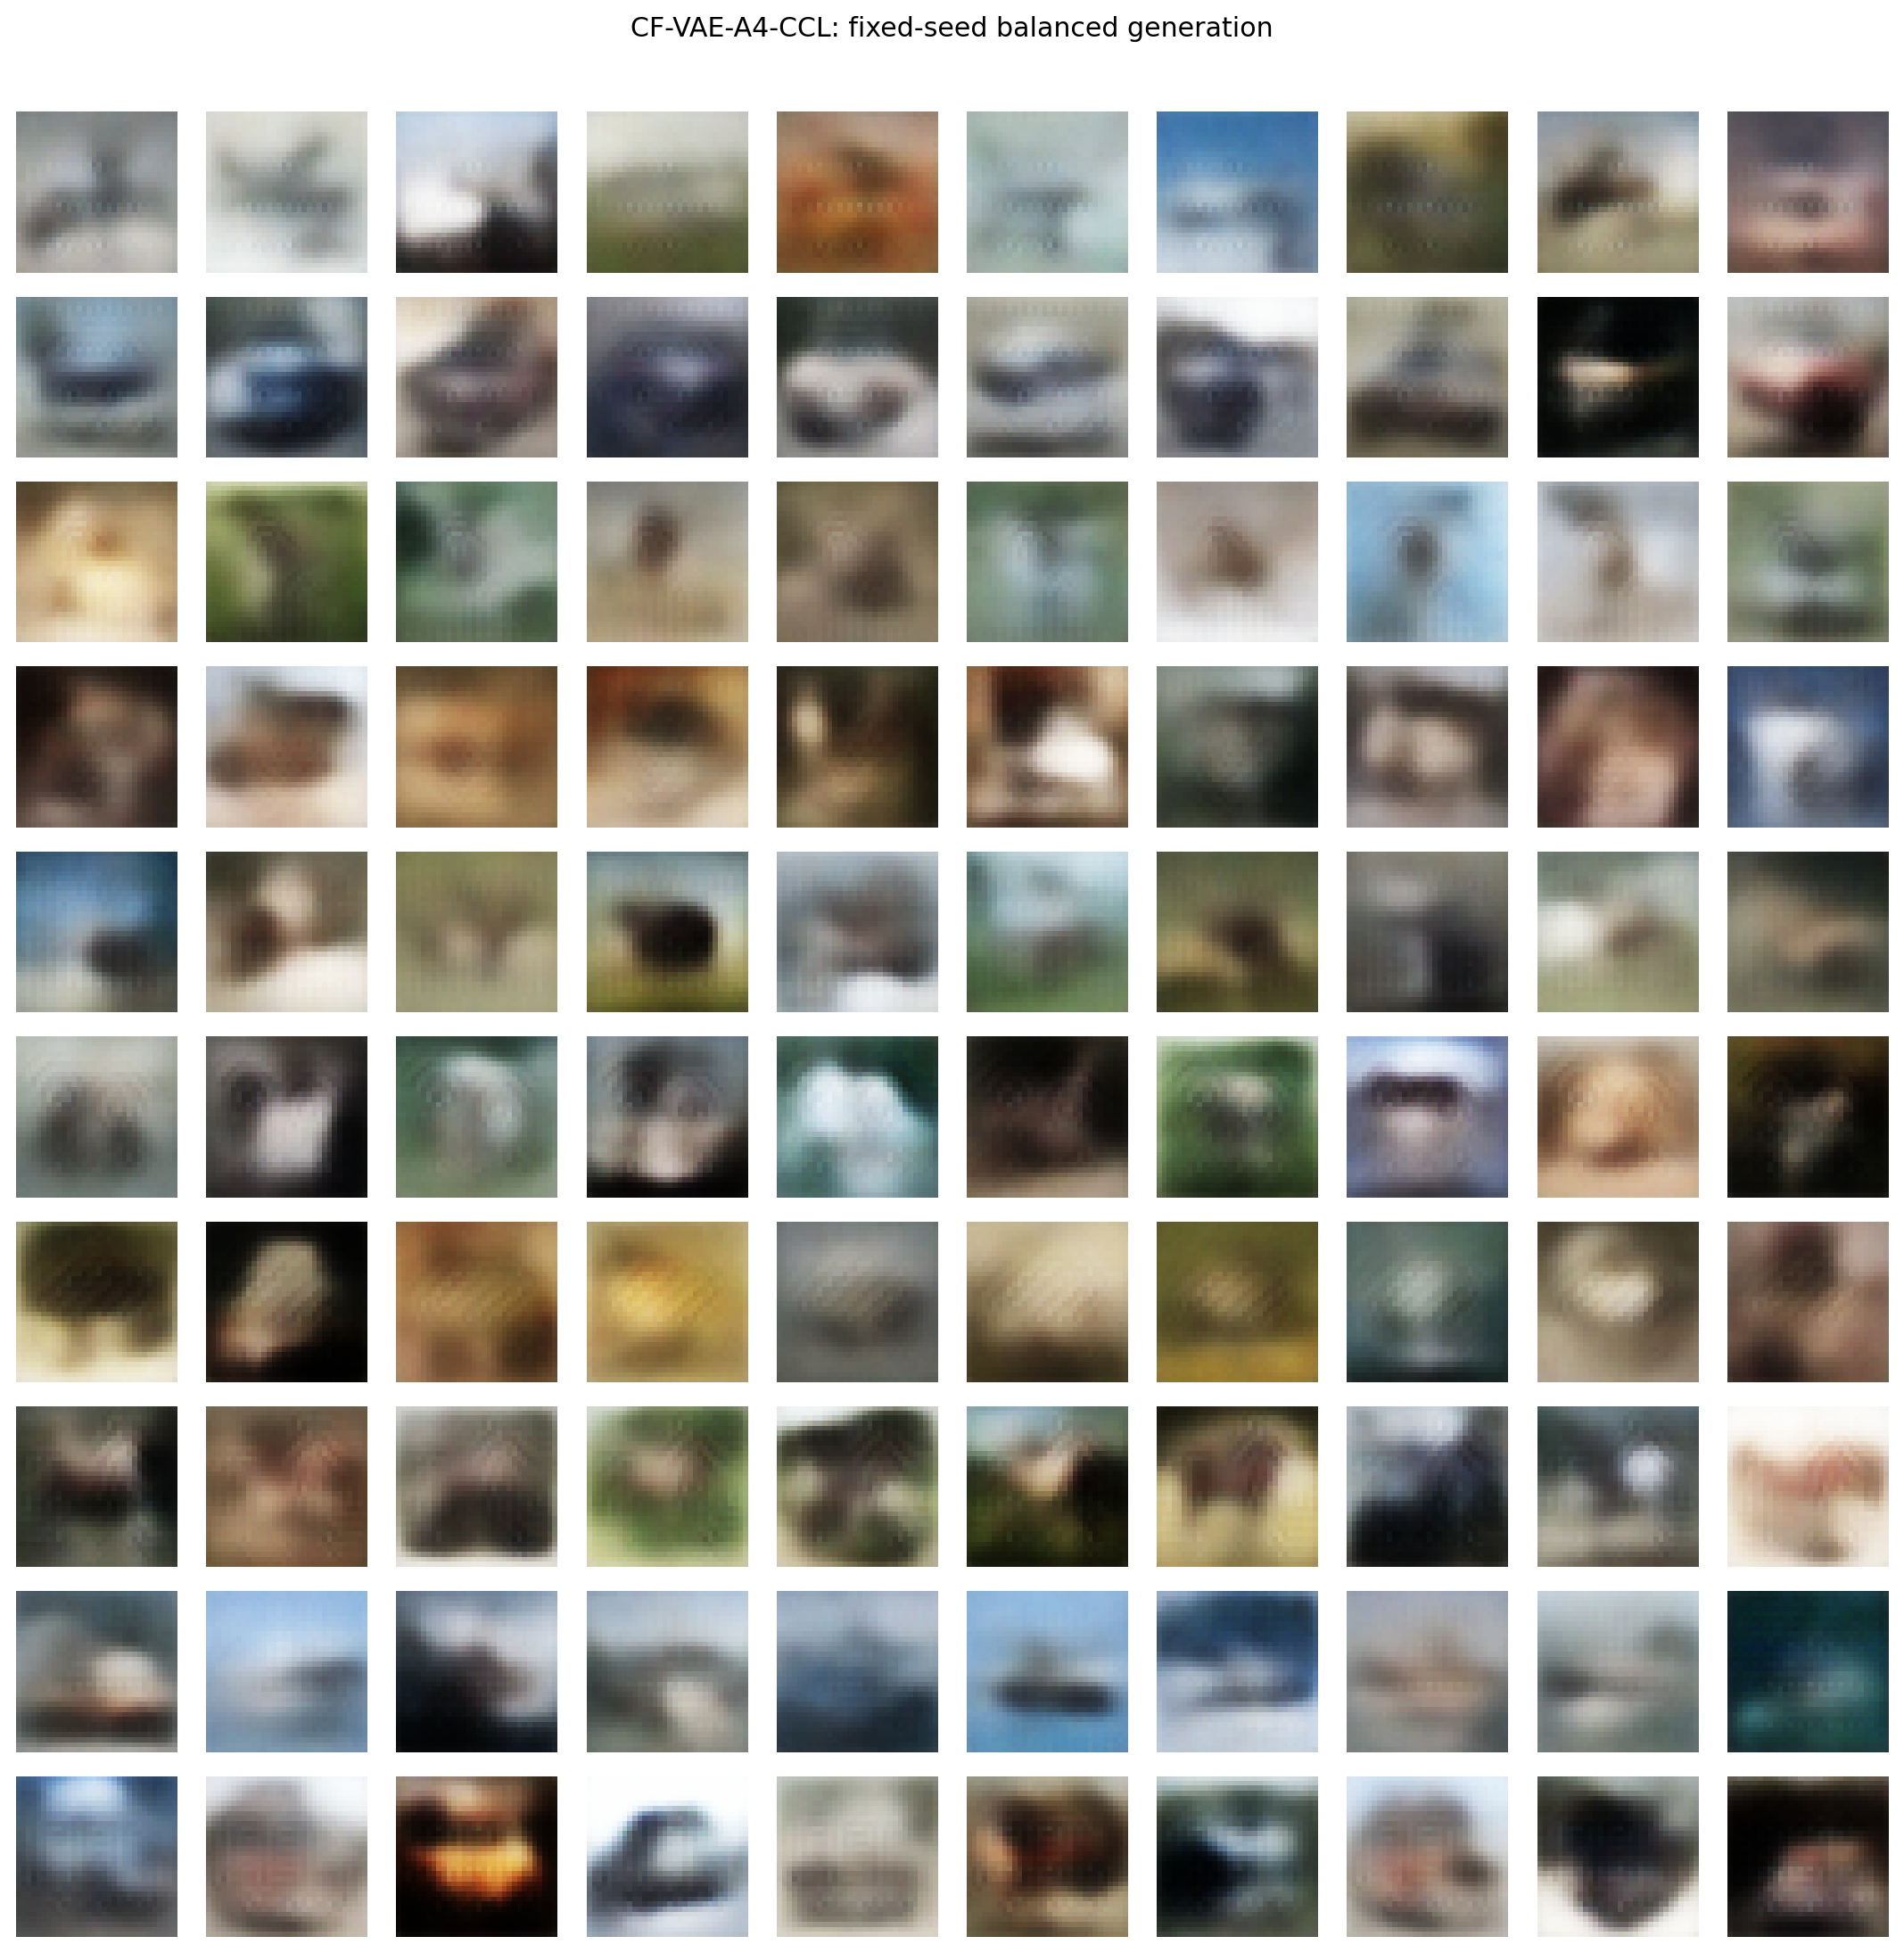

In [34]:
# Purpose: Display Chun Fei VAE A4's balanced fixed-seed generated grid.
if _review_is_active():
    _review_png(
        "CF-VAE-A4-CCL_fixed_grid.png",
        "CF-VAE-A4-CCL — balanced fixed-seed grid",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

Among the two VAEs, `CF-VAE-A4-CCL` is the stronger conditional generator.
Its outputs remain characteristically smooth, but the requested-class
structure is substantially more reliable than `YX-VAE-B1`, matching its much
higher conditioning accuracy and lower FID.


## 18.13 YX-VAE-B1 fixed-seed generated grid


### YX-VAE-B1 — balanced fixed-seed grid

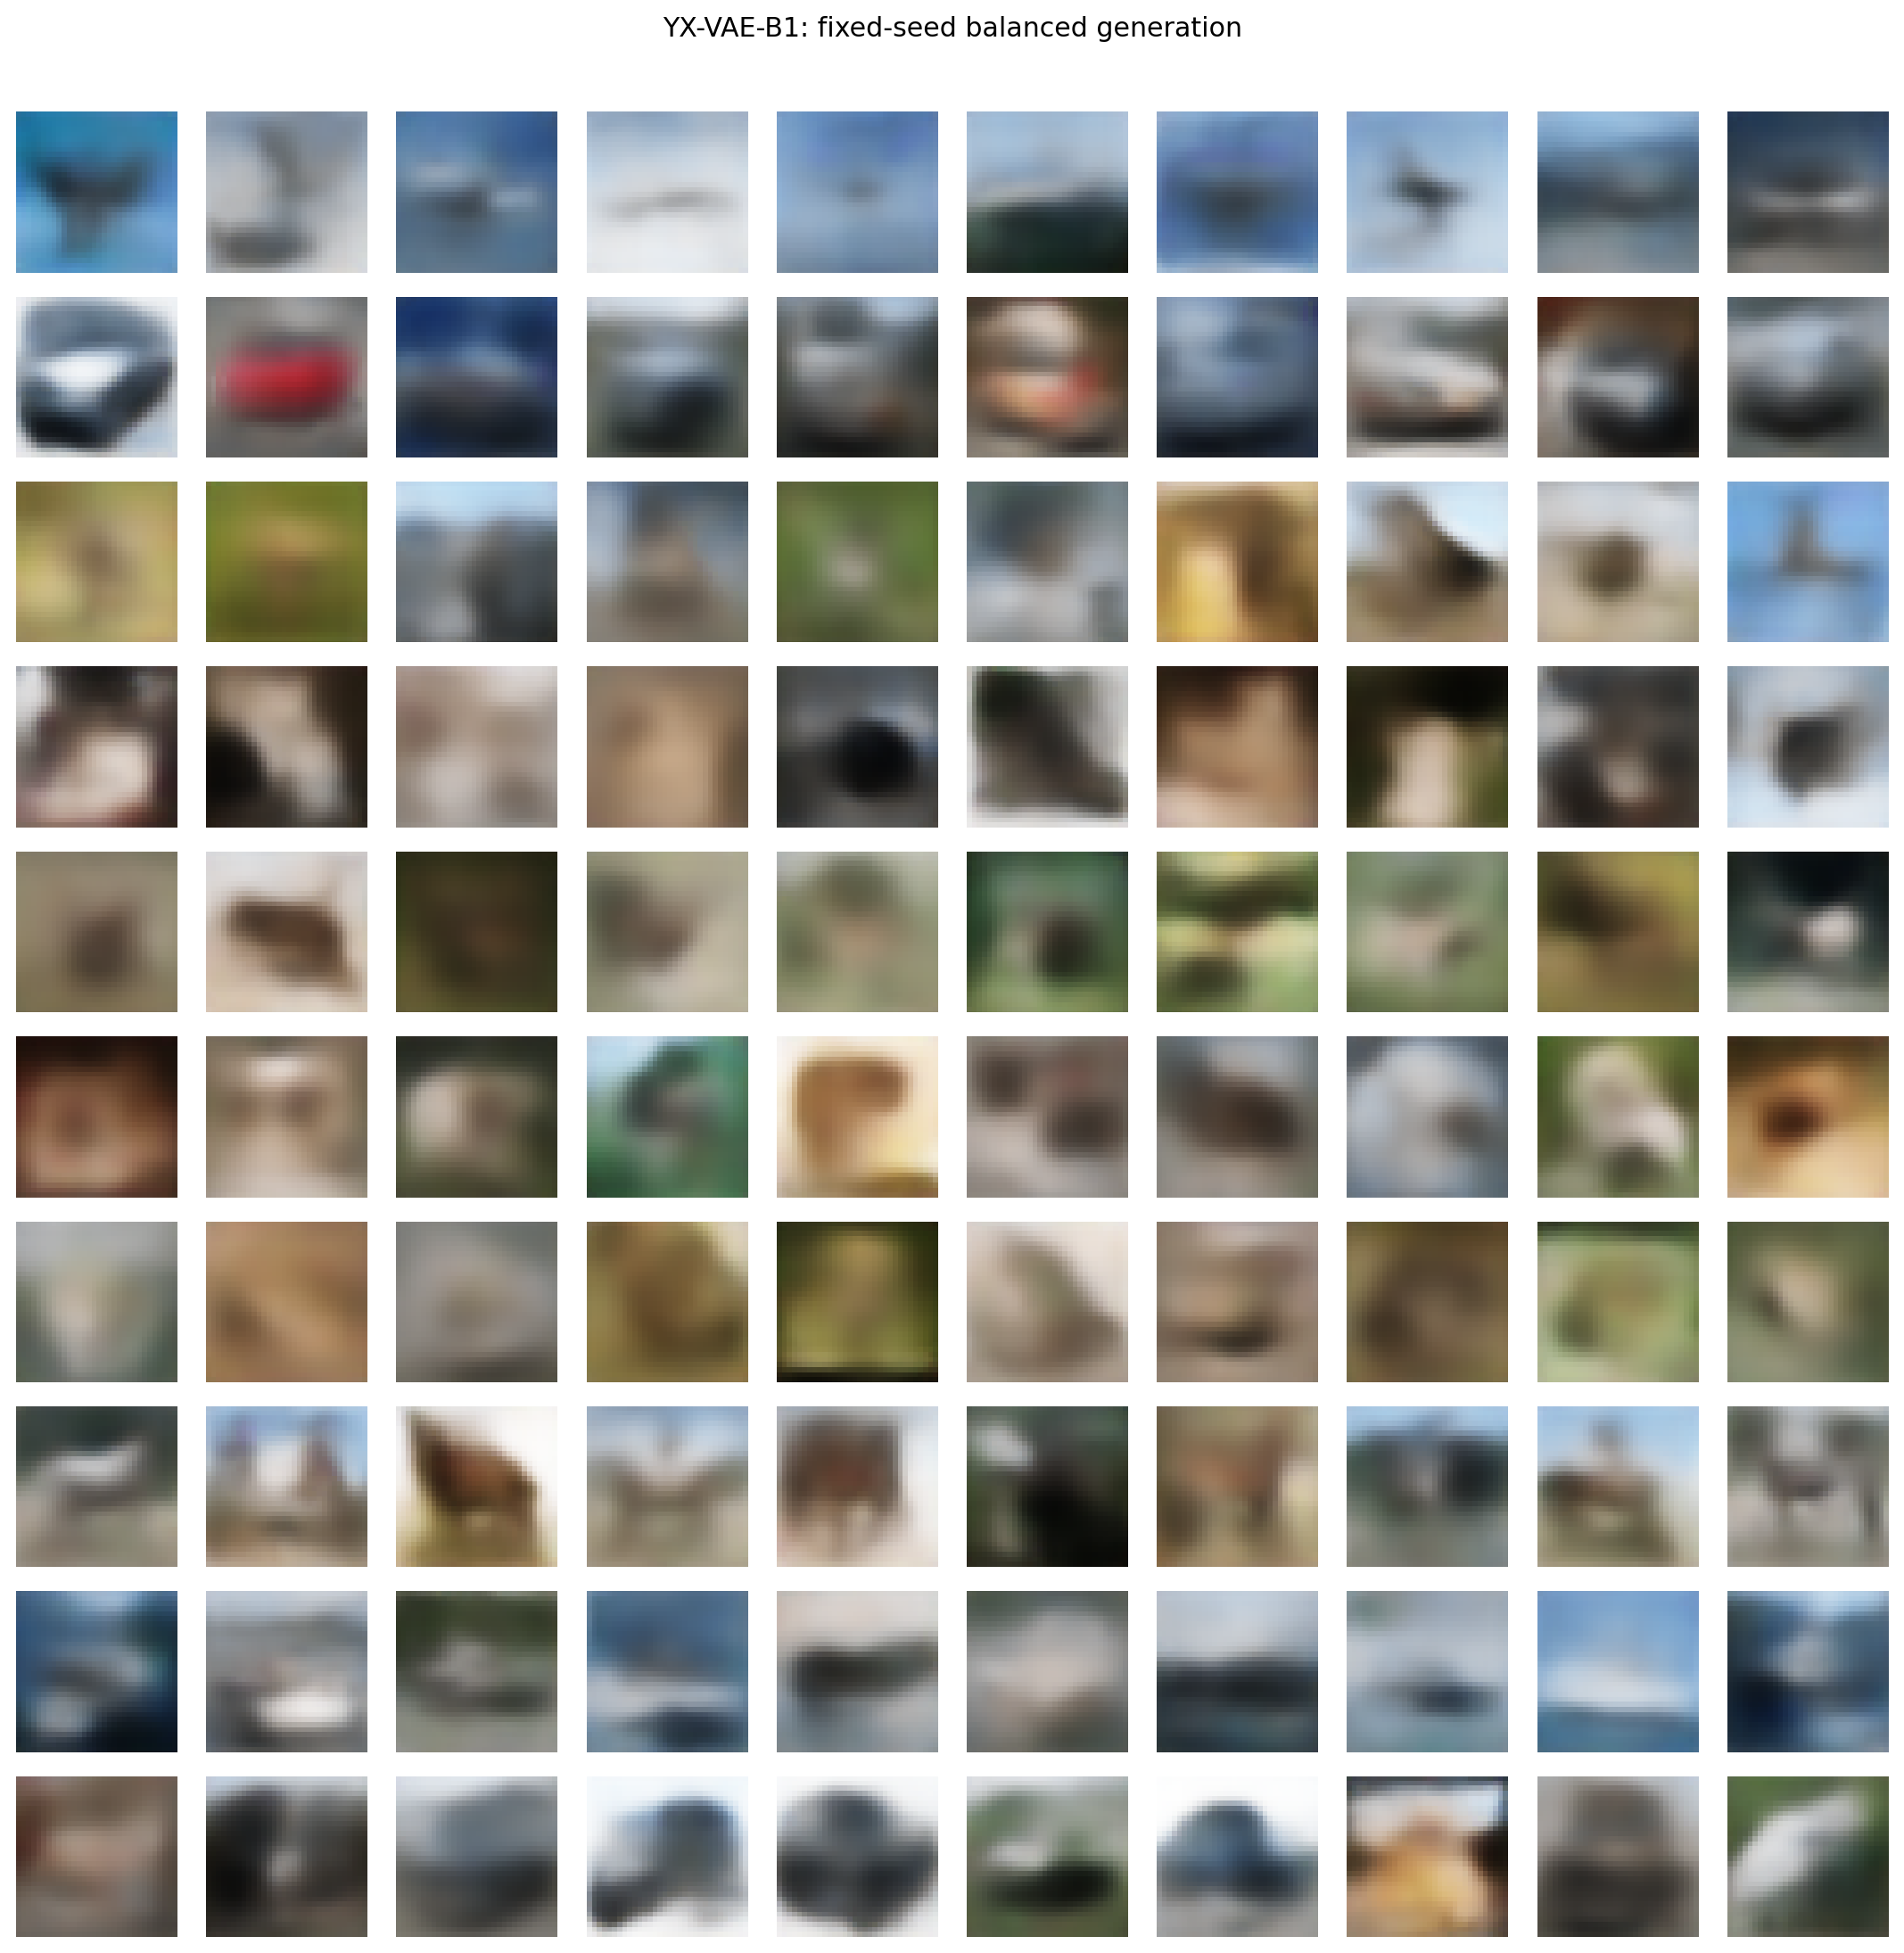

In [35]:
# Purpose: Display You Xuan VAE B1's balanced fixed-seed generated grid.
if _review_is_active():
    _review_png(
        "YX-VAE-B1_fixed_grid.png",
        "YX-VAE-B1 — balanced fixed-seed grid",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`YX-VAE-B1` demonstrates that a VAE can produce varied CIFAR-10-like samples,
but the grid should be read together with its low shared class-control score.
The model's small IS advantage over `CF-VAE-A4-CCL` does not compensate for
its weaker requested-class reliability and higher FID.


## 18.14 CF-GAN-A0-EQUAL-LR fixed-seed generated grid


### CF-GAN-A0-EQUAL-LR — balanced fixed-seed grid

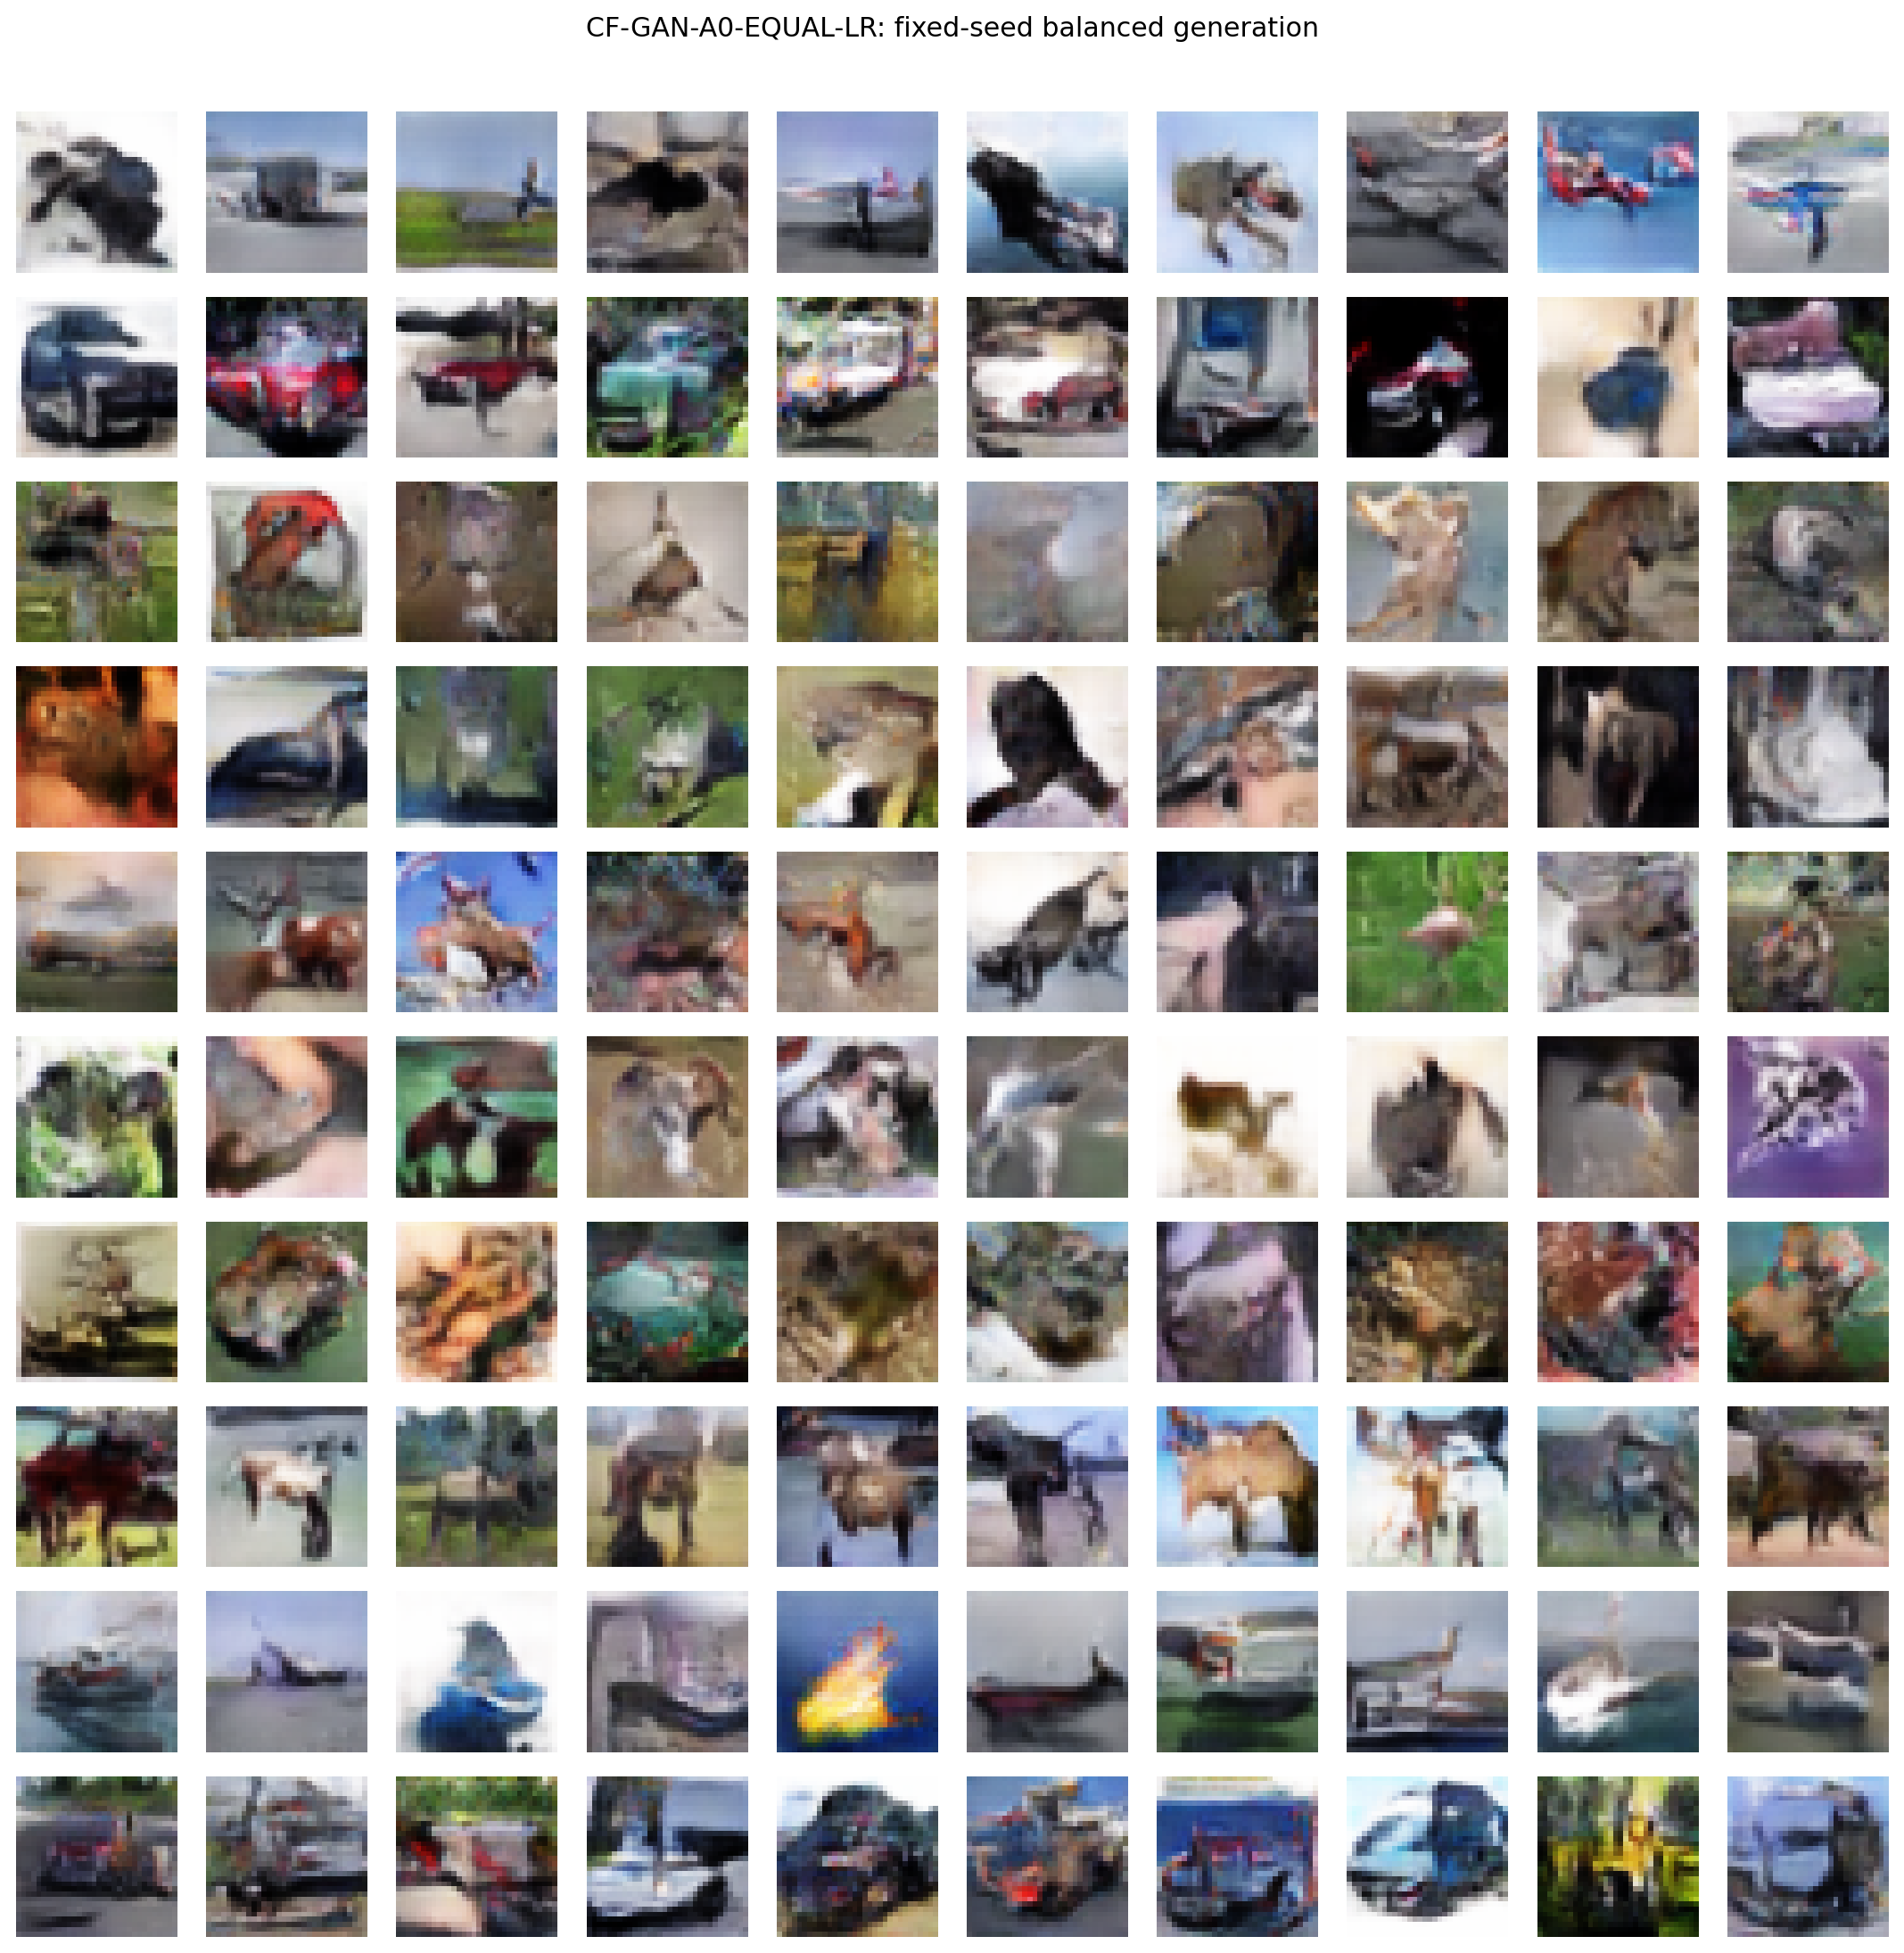

In [36]:
# Purpose: Display Chun Fei GAN A0's balanced fixed-seed generated grid.
if _review_is_active():
    _review_png(
        "CF-GAN-A0-EQUAL-LR_fixed_grid.png",
        "CF-GAN-A0-EQUAL-LR — balanced fixed-seed grid",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`CF-GAN-A0-EQUAL-LR` produces sharper and more textured samples than the VAE
finalists and achieves the highest Inception Score. Its weakness is not basic
image quality but class control: it follows the requested label less reliably
than `YX-GAN-B4-E300`.


## 18.15 YX-GAN-B4-E300 fixed-seed generated grid


### YX-GAN-B4-E300 — balanced fixed-seed grid

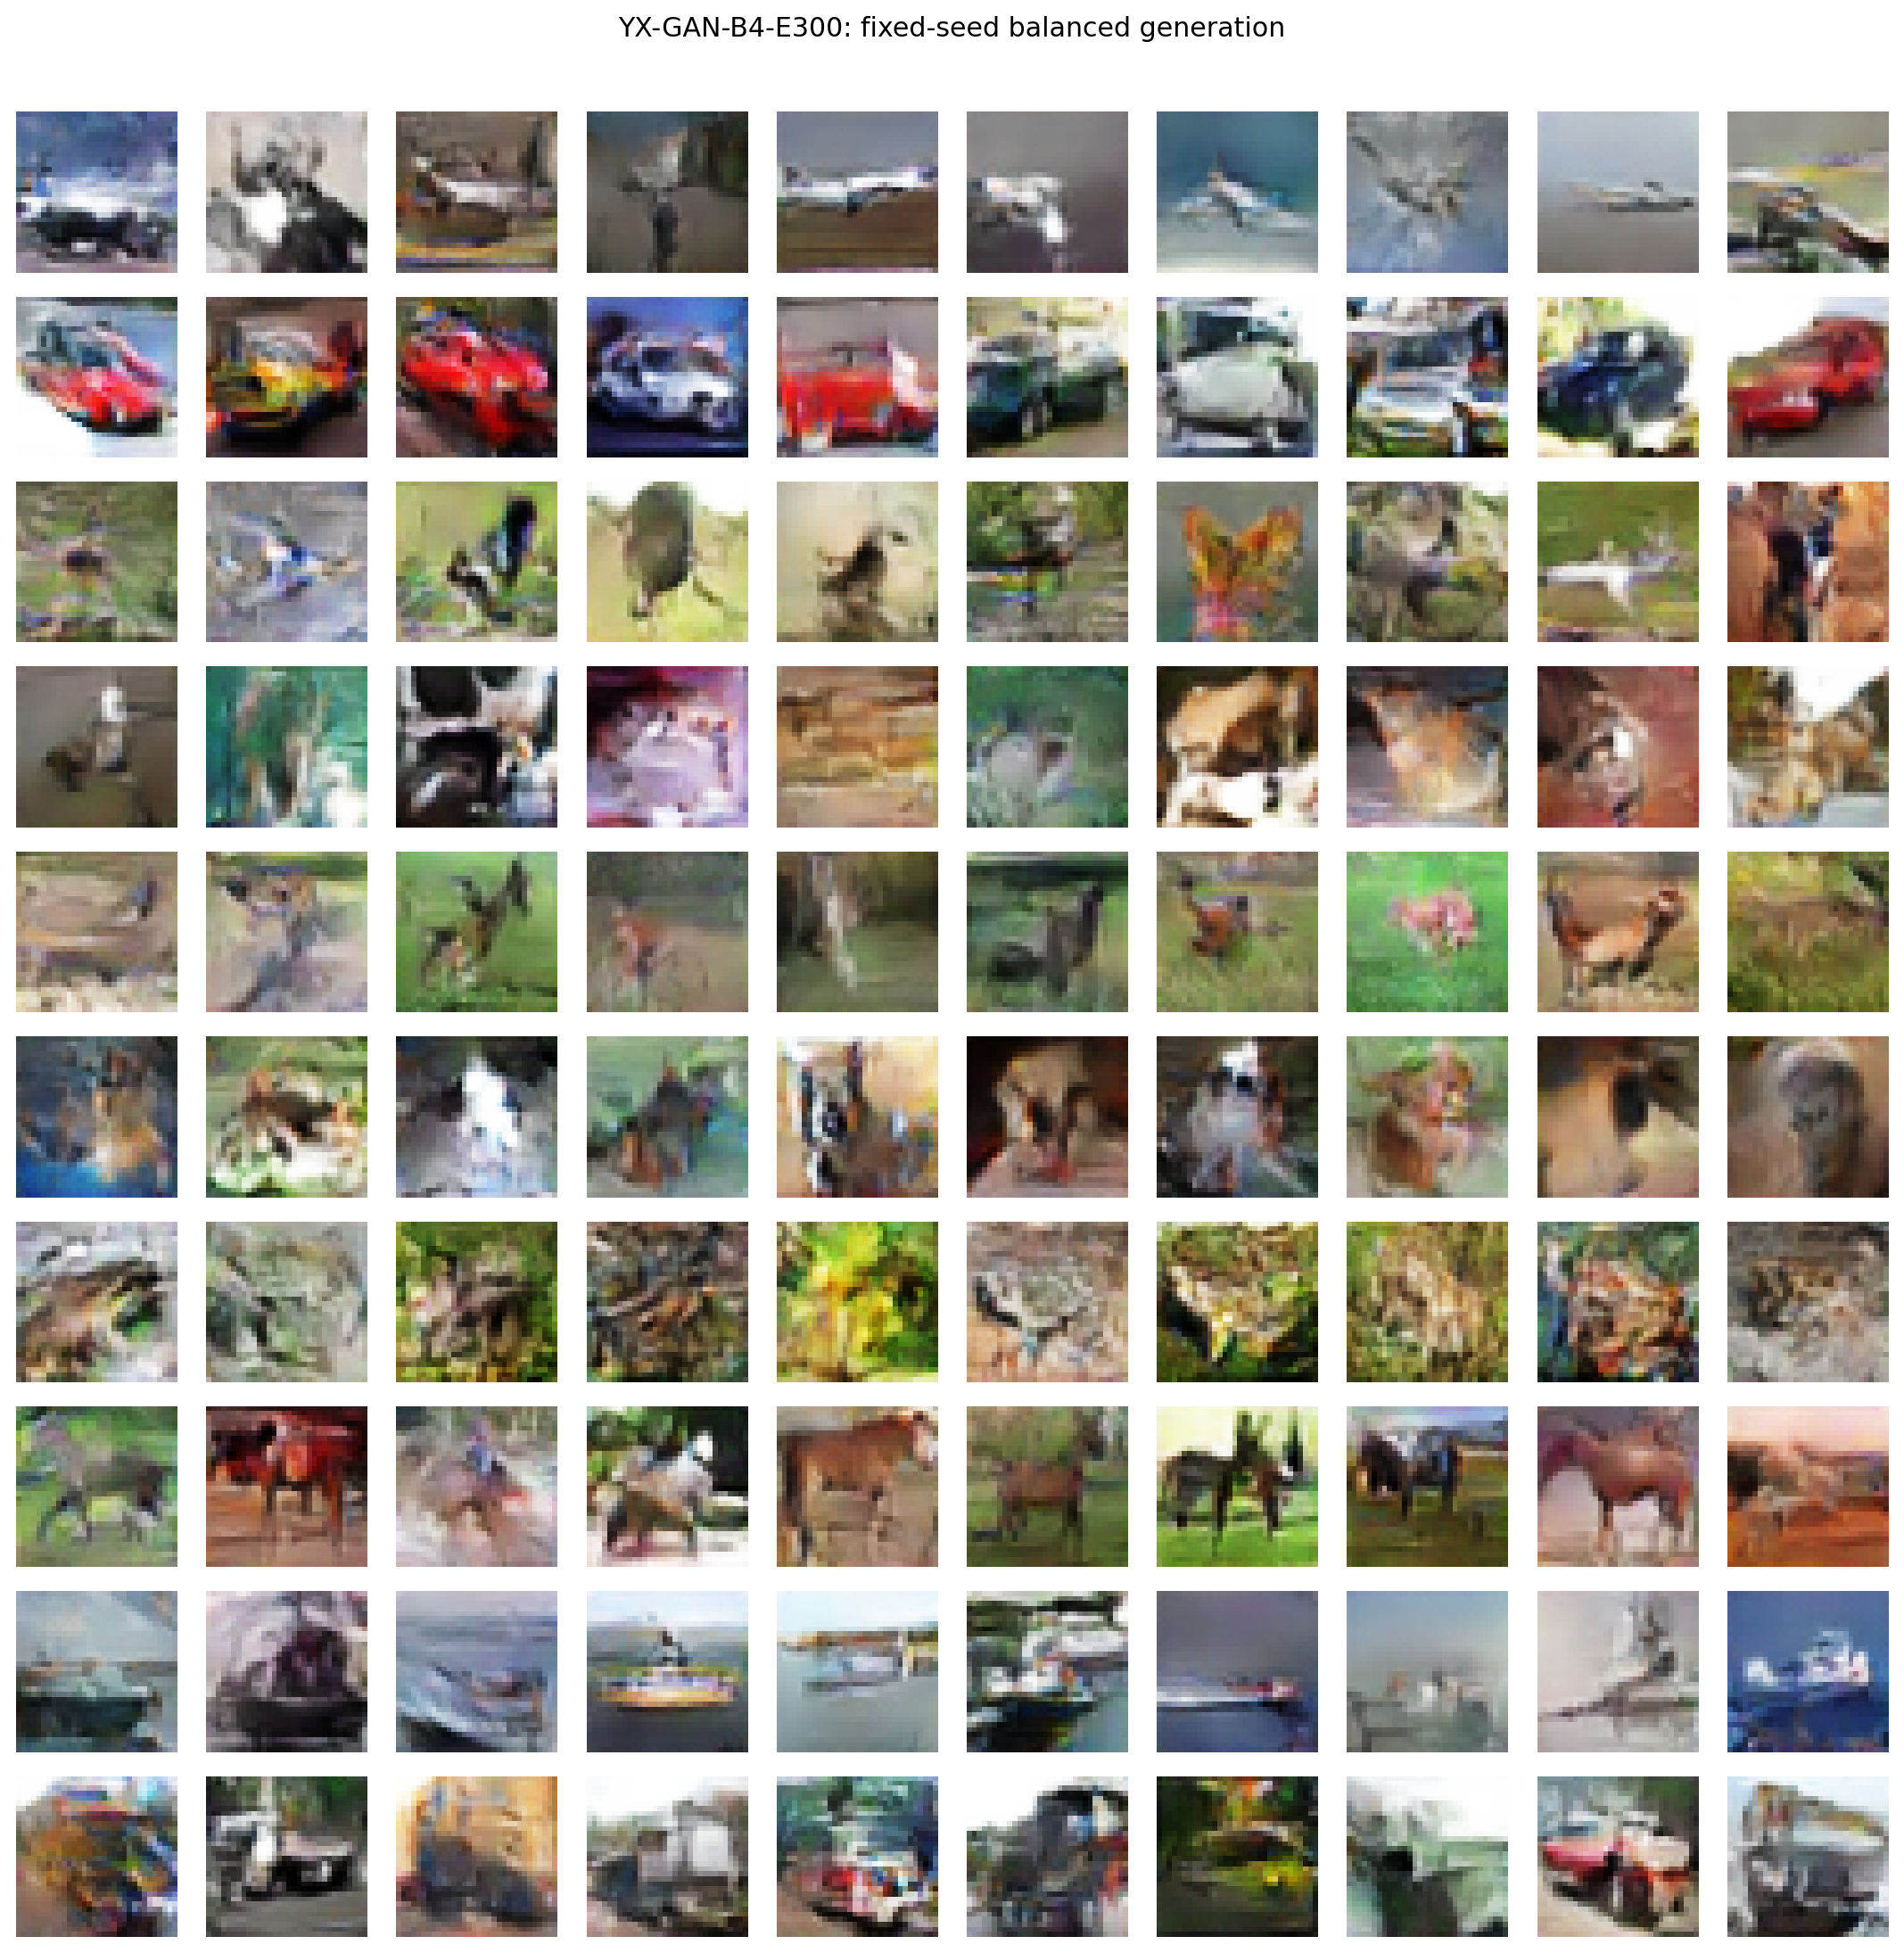

In [37]:
# Purpose: Display You Xuan GAN B4's balanced fixed-seed generated grid.
if _review_is_active():
    _review_png(
        "YX-GAN-B4-E300_fixed_grid.png",
        "YX-GAN-B4-E300 — balanced fixed-seed grid",
    )
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

`YX-GAN-B4-E300` combines GAN-level sharpness and low FID with the strongest
requested-class accuracy and confidence. The grid therefore supports its
selection as the overall winner, while the confusion analysis still highlights
remaining weaknesses in visually similar animal classes.


## 18.16 Optional VAE latent interpolation

Latent interpolation is supporting VAE analysis rather than a winner-selection
metric. When the interpolation stage has been run, the following cells display
the saved transitions separately for each VAE so the transitions can be inspected alongside the other saved evidence
without searching through a long block of figures.


### CF-VAE-A4-CCL interpolation cat

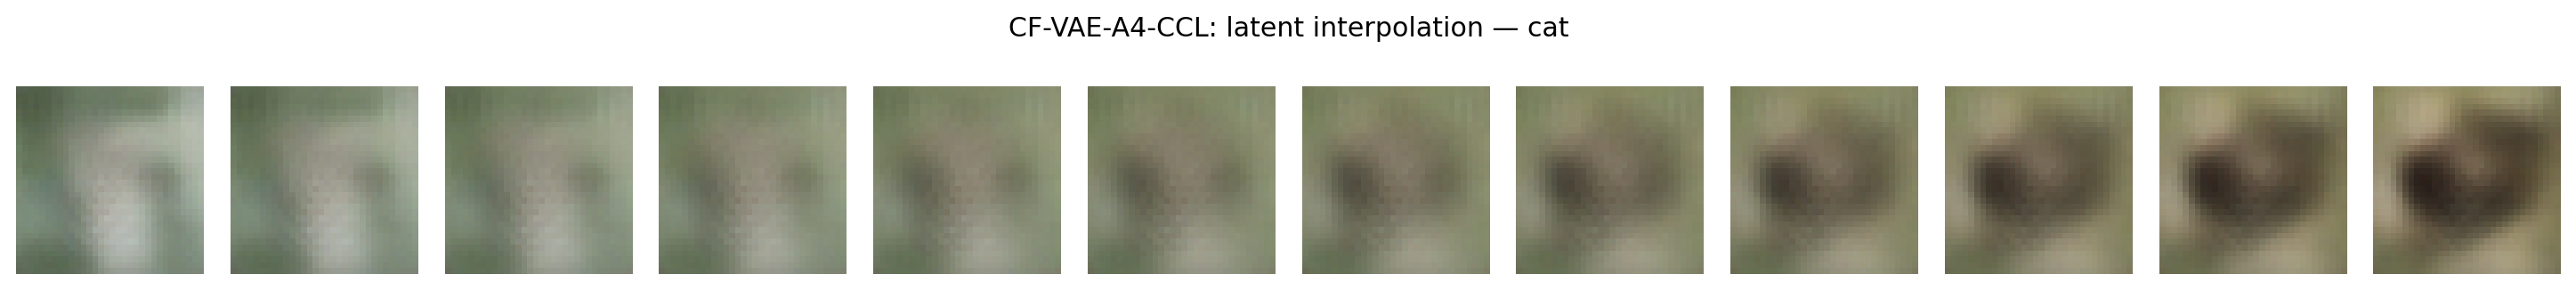

### CF-VAE-A4-CCL interpolation ship

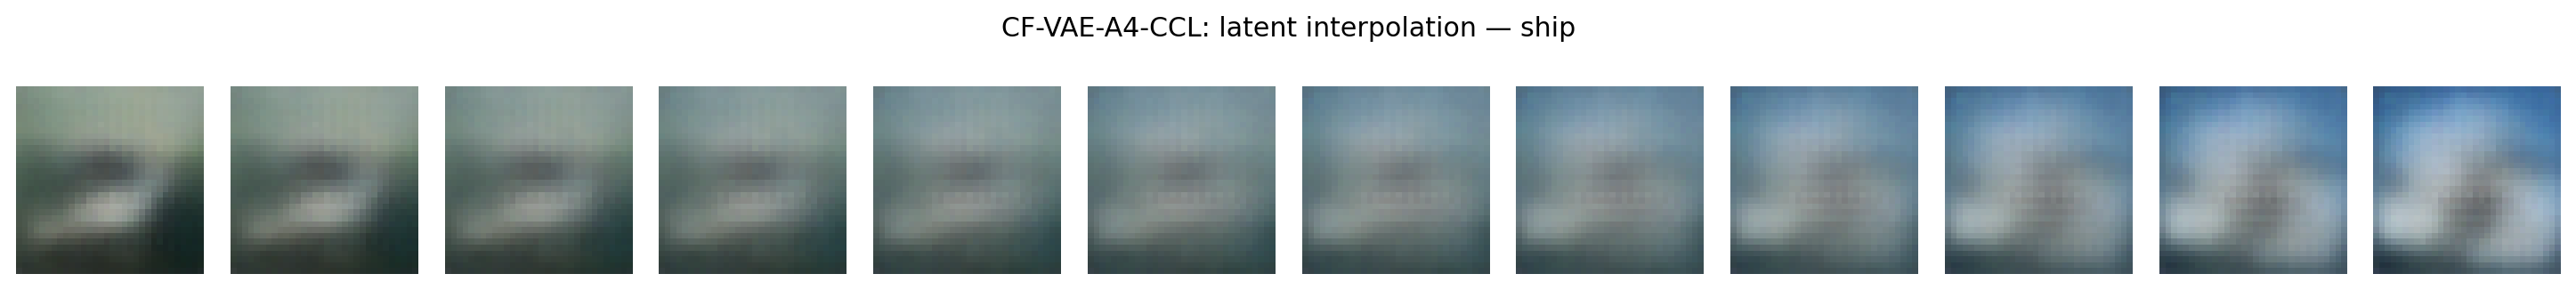

In [38]:
# Purpose: Display saved CF-VAE-A4 interpolation figures if that optional stage has been run.
if _review_is_active():
    paths = sorted(FIGURE_DIR.glob("CF-VAE-A4-CCL_interpolation_*.png"))
    if not paths:
        print("Saved CF-VAE-A4-CCL interpolation figures were not found in this workspace. "
              "RUN_VAE_INTERPOLATION can regenerate this optional evidence.")
    for path in paths:
        display(Markdown(f"### {path.stem.replace('_', ' ')}"))
        display(IPyImage(filename=str(path)))
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

For `CF-VAE-A4-CCL`, interpolation is used only to inspect whether decoded
images change gradually as the latent vector moves between two points. Smooth
transitions would support the interpretation that the learned latent space is
continuous. This evidence is supplementary and is not used to override the
shared FID, IS or class-control results.


### YX-VAE-B1 interpolation cat

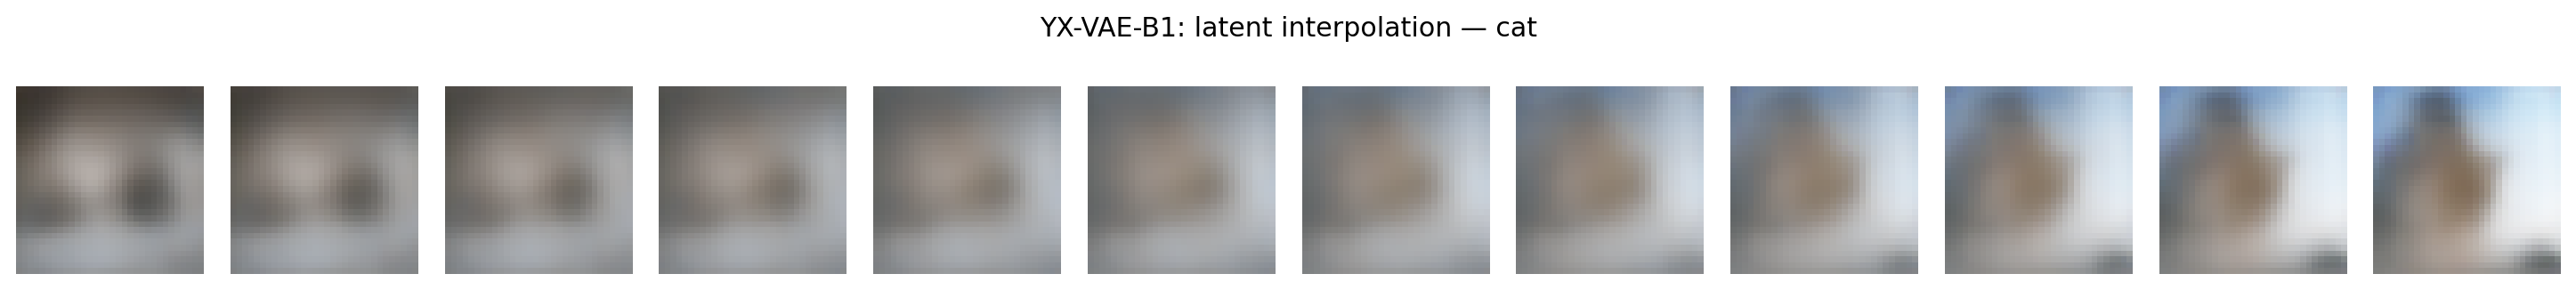

### YX-VAE-B1 interpolation ship

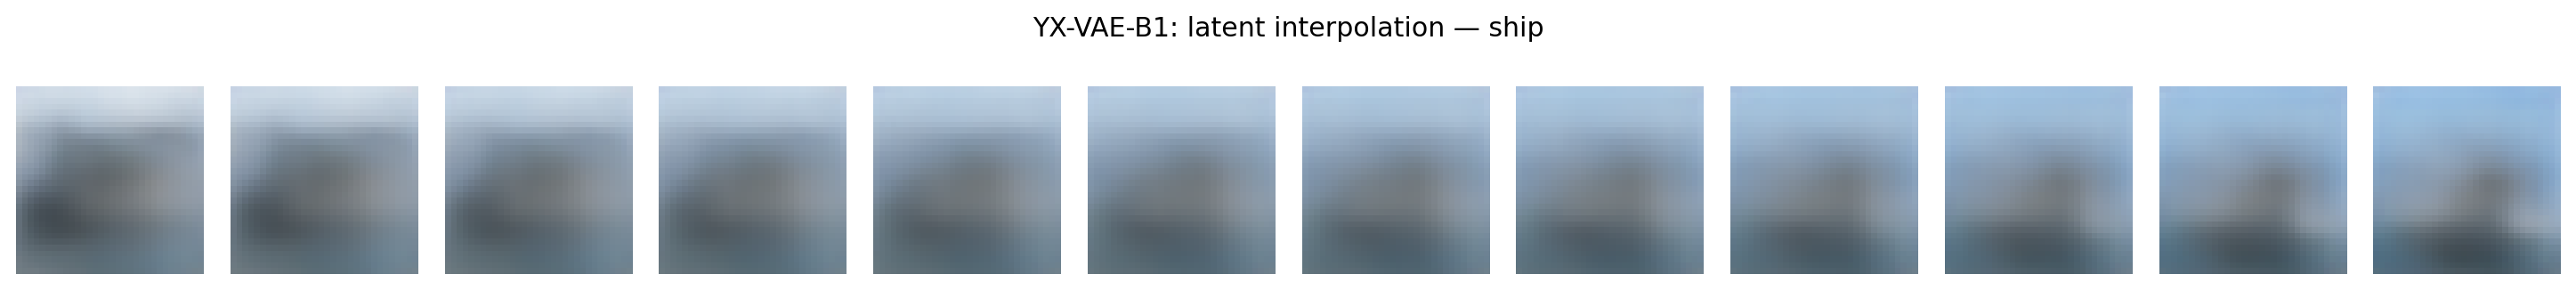

In [39]:
# Purpose: Display saved YX-VAE-B1 interpolation figures if that optional stage has been run.
if _review_is_active():
    paths = sorted(FIGURE_DIR.glob("YX-VAE-B1_interpolation_*.png"))
    if not paths:
        print("Saved YX-VAE-B1 interpolation figures were not found in this workspace. "
              "RUN_VAE_INTERPOLATION can regenerate this optional evidence.")
    for path in paths:
        display(Markdown(f"### {path.stem.replace('_', ' ')}"))
        display(IPyImage(filename=str(path)))
else:
    # Display only during the saved-results review stage.
    pass


### Evaluation

For `YX-VAE-B1`, the interpolation figures serve the same supporting purpose:
they show how smoothly the decoder changes between latent points. They are
useful for discussing VAE latent-space behaviour, but the final VAE selection
remains based primarily on the shared generative-quality and class-control
evidence.


# 19. Final shared model selection

## Best conditional VAE — `CF-VAE-A4-CCL`

`CF-VAE-A4-CCL` is selected because it has substantially lower FID than
`YX-VAE-B1` (200.076 versus 220.318), far stronger conditioning accuracy
(57.45% versus 21.73%), much higher requested-class confidence
(52.26% versus 19.65%), and fewer generation-component parameters.
`YX-VAE-B1` has only a very small IS advantage, which is insufficient to
offset these larger disadvantages.

## Best conditional GAN — `YX-GAN-B4-E300`

The two GANs have effectively tied FID. `CF-GAN-A0-EQUAL-LR` has the stronger
IS (4.567 versus 4.033), but `YX-GAN-B4-E300` has substantially stronger class
control: 72.75% conditioning accuracy versus 60.16%, and 69.59%
requested-class confidence versus 57.45%.

Because the goal is specified-class generation across ten named
classes, stronger class controllability is the deciding
evidence when FID is effectively tied.

## Overall winner — `YX-GAN-B4-E300`

Both GAN finalists substantially outperform the VAE finalists on FID and IS.
`YX-GAN-B4-E300` combines GAN-level distribution quality with the strongest
requested-class accuracy and confidence of all four finalists, so it is
selected as the generator for the final 1,000 images.

```text
Best VAE:
CF-VAE-A4-CCL

Best GAN:
YX-GAN-B4-E300

Overall winner:
YX-GAN-B4-E300
```

The decision is based on repeated FID/IS, requested-class accuracy and
confidence, per-class/confusion evidence, duplicate/diversity checks and the
fixed-seed visual comparison together. No arbitrary weighted score is used.


Final 1,000-image export: VERIFIED
Total class-folder PNGs: 1,000
Per class: 100 images × 10 classes
Recorded winning model: YX-GAN-B4-E300
The images are reused from the saved export; they are not regenerated during REVIEW_SAVED_OUTPUTS.


### Final 1,000-image contact sheet

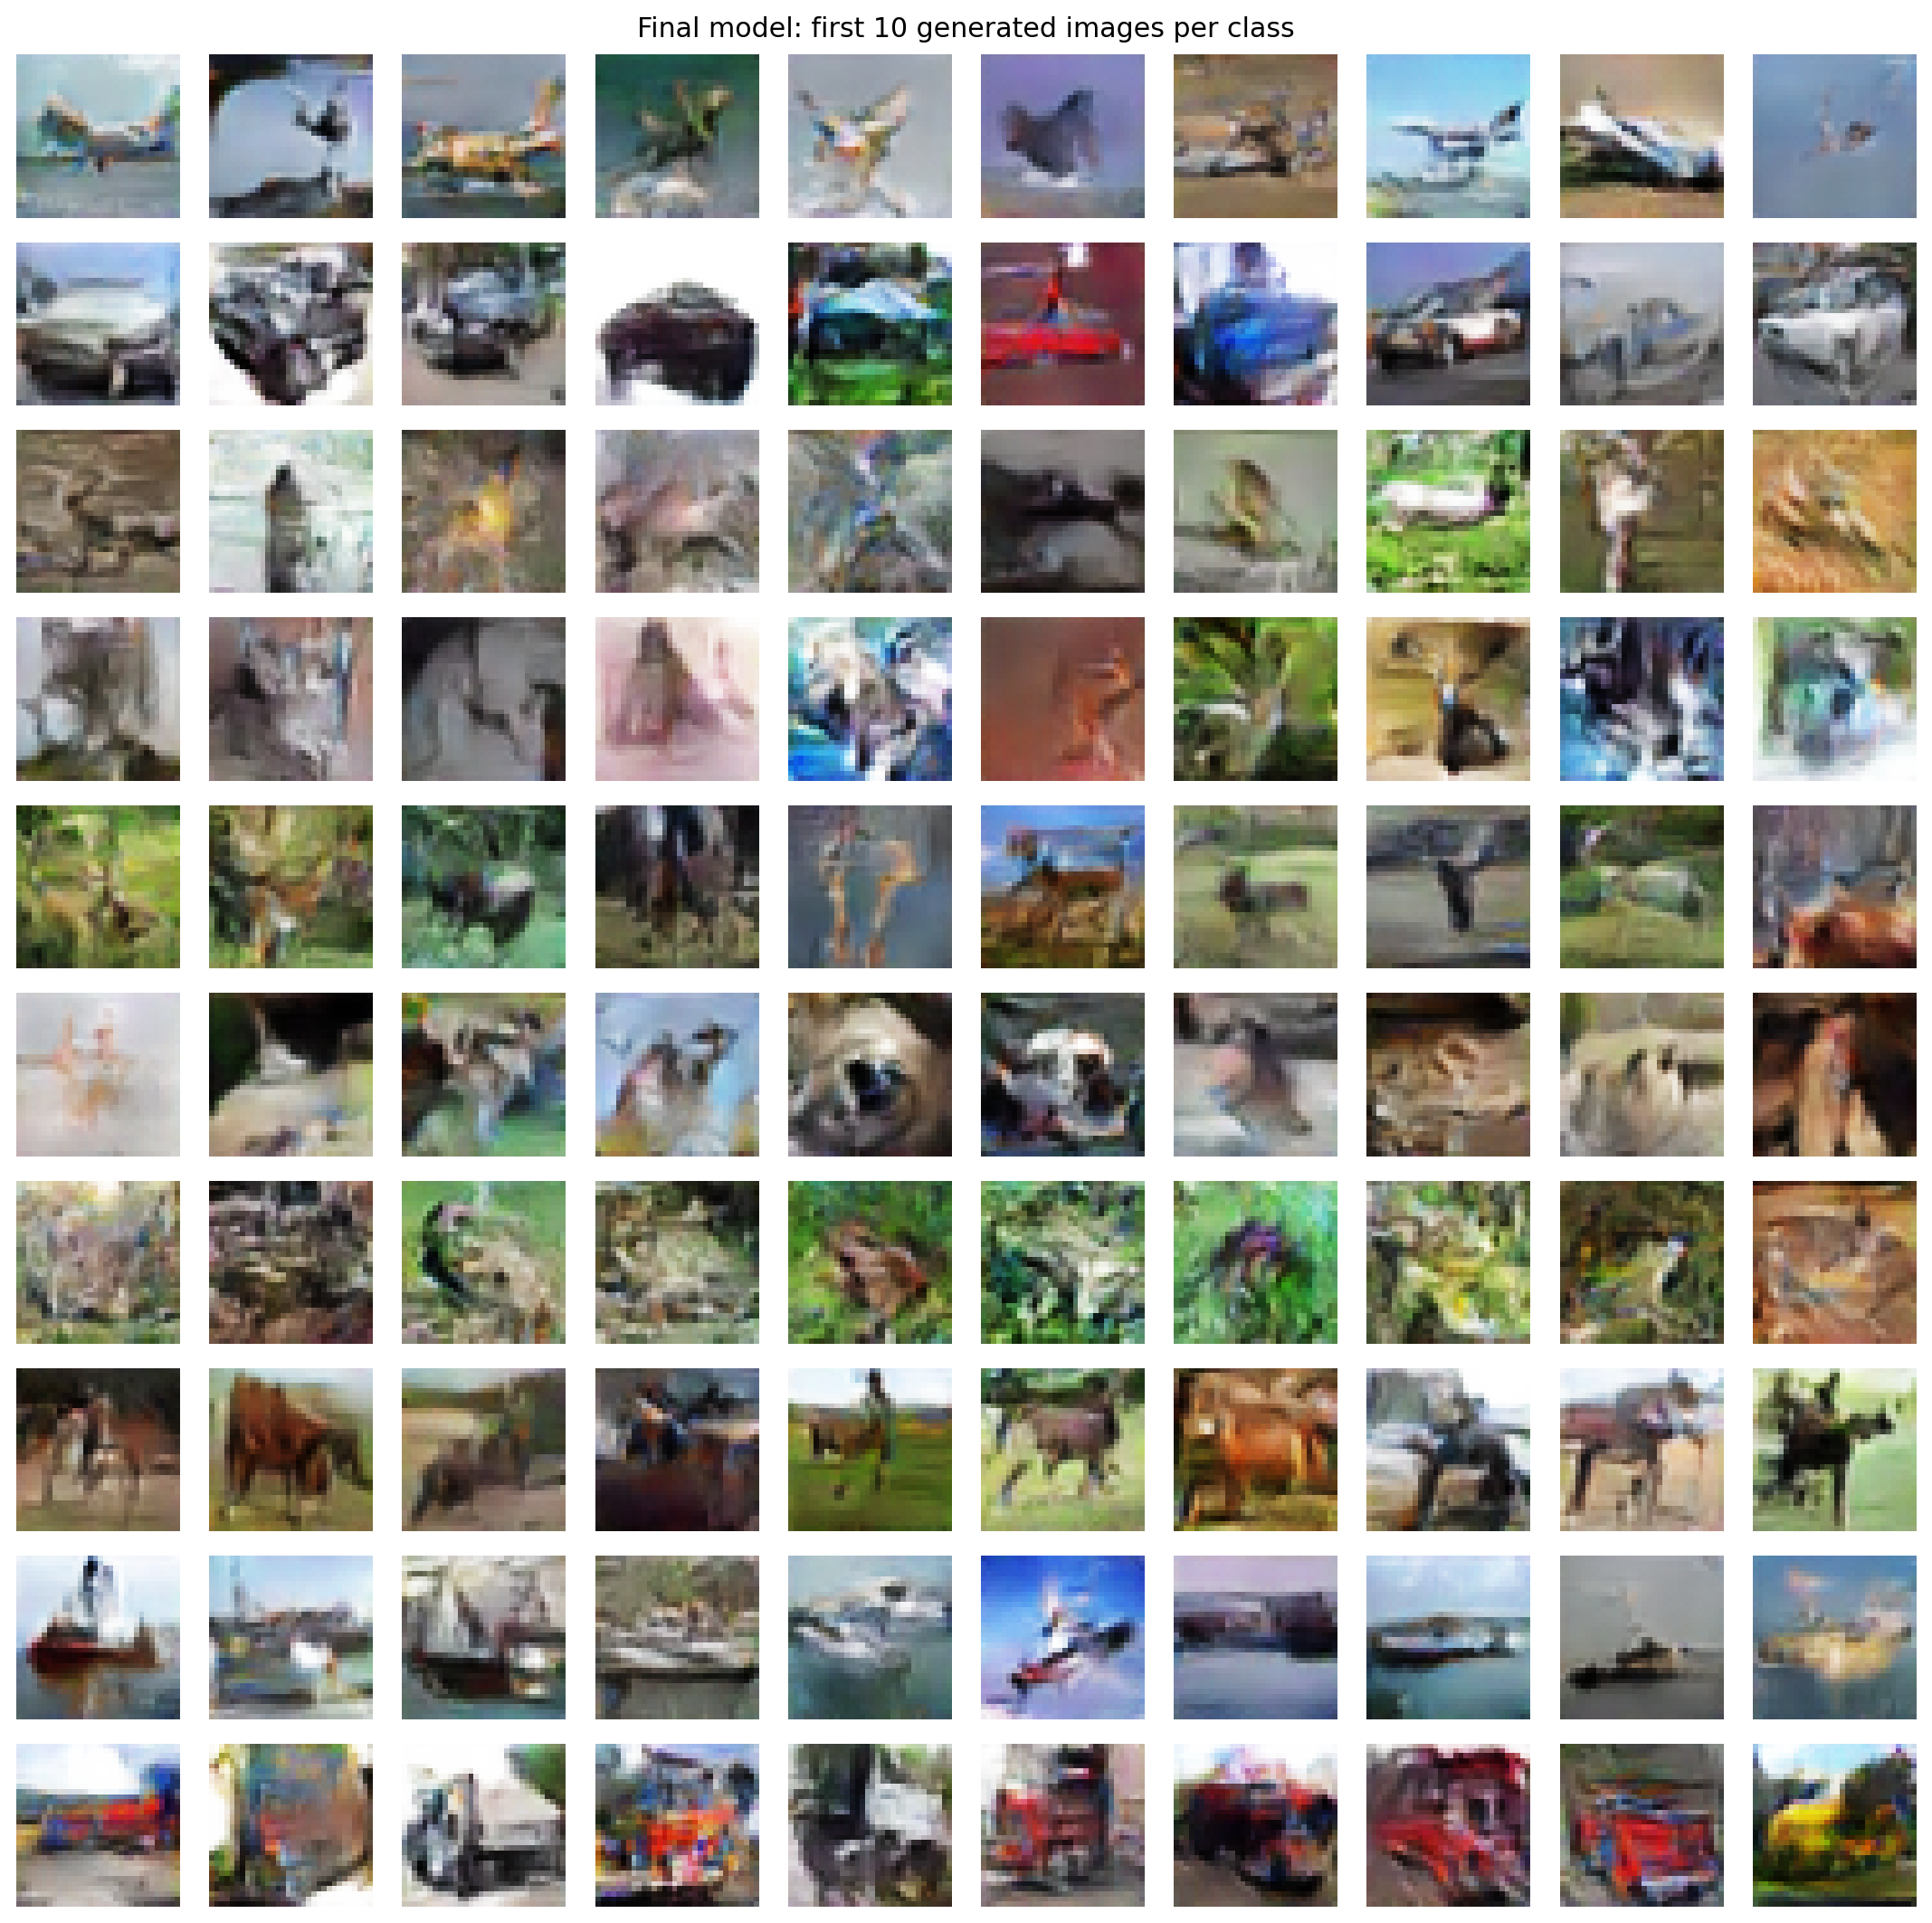

In [40]:
# Purpose: Export exactly 1,000 images from the recorded overall winner and verify 100 images per class.
# ============================================================
# 19. Final 1,000-image exporter
# ============================================================
def save_final_contact_sheet(images, labels):
    figure, axes = plt.subplots(
        NUM_CLASSES,
        10,
        figsize=(12, 12),
    )

    for class_id in range(NUM_CLASSES):
        class_images = images[labels == class_id][:10]

        for column, image in enumerate(class_images):
            axes[class_id, column].imshow(image)
            axes[class_id, column].axis("off")

            if column == 0:
                axes[class_id, column].set_ylabel(
                    CLASS_NAMES[class_id],
                    rotation=0,
                    ha="right",
                    va="center",
                    fontsize=8,
                )

    figure.suptitle(
        "Final model: first 10 generated images per class"
    )
    figure.tight_layout()
    figure.savefig(
        FINAL_DIR / "final_contact_sheet.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()


def export_final_1000(
    winner_model_id,
    seed=2026,
):
    if winner_model_id not in MODEL_SPECS:
        raise ValueError(
            "OVERALL_WINNER_ID must be one of: "
            f"{sorted(MODEL_SPECS)}"
        )

    if FINAL_DIR.exists() and any(FINAL_DIR.iterdir()):
        if not ALLOW_OVERWRITE_FINAL_EXPORT:
            raise FileExistsError(
                f"{FINAL_DIR} is not empty. "
                "Set ALLOW_OVERWRITE_FINAL_EXPORT=True only after "
                "confirming that overwriting is intended."
            )
        shutil.rmtree(FINAL_DIR)

    FINAL_DIR.mkdir(parents=True, exist_ok=True)

    # Reload the frozen winning generator; the export never retrains the model.
    model, spec = load_generation_model(
        winner_model_id
    )
    images, labels, latents = generate_balanced(
        model,
        spec,
        n_per_class=100,
        seed=seed,
        return_latents=True,
    )

    # Verify the generated batch is exactly balanced before writing any image files.
    counts = np.bincount(
        labels,
        minlength=NUM_CLASSES,
    )

    assert len(images) == 1_000
    assert np.all(counts == 100), counts

    # Save class, seed and checkpoint metadata for every exported image.
    metadata_rows = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        class_folder = FINAL_DIR / class_name
        class_folder.mkdir(
            parents=True,
            exist_ok=True,
        )

        class_indices = np.flatnonzero(
            labels == class_id
        )

        for local_index, global_index in enumerate(class_indices):
            filename = (
                f"{class_name}_{local_index:03d}.png"
            )
            relative_path = Path(class_name) / filename

            keras.utils.save_img(
                FINAL_DIR / relative_path,
                images[global_index],
            )

            metadata_rows.append({
                "filename": str(relative_path),
                "requested_class_id": class_id,
                "requested_class_name": class_name,
                "latent_row": int(global_index),
                "generation_seed": seed,
                "model_id": winner_model_id,
                "checkpoint": str(spec["checkpoint"]),
            })

    metadata = pd.DataFrame(metadata_rows)
    metadata.to_csv(
        FINAL_DIR / "generated_images_metadata.csv",
        index=False,
    )

    np.save(
        FINAL_DIR / "final_latent_vectors.npy",
        latents,
    )
    np.save(
        FINAL_DIR / "final_labels.npy",
        labels,
    )

    final_config = {
        "winner_model_id": winner_model_id,
        "owner": spec["owner"],
        "family": spec["family"],
        "checkpoint": str(spec["checkpoint"]),
        "latent_dim": int(spec["latent_dim"]),
        "seed": seed,
        "images_per_class": 100,
        "total_images": 1_000,
        "class_names": CLASS_NAMES,
    }

    with open(
        FINAL_DIR / "final_model_config.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(final_config, file, indent=2)

    save_final_contact_sheet(images, labels)

    # Final disk-level check: confirm 100 PNGs in every class folder.
    file_counts = {
        class_name: len(
            list(
                (FINAL_DIR / class_name).glob("*.png")
            )
        )
        for class_name in CLASS_NAMES
    }

    assert sum(file_counts.values()) == 1_000
    assert all(count == 100 for count in file_counts.values())

    print("Final model:", winner_model_id)
    print("Per-class file counts:", file_counts)
    print("Verified total: 1,000 images")

    return metadata


def verify_saved_final_export(show_contact_sheet=False):
    """Verify the saved final export independently of the current stage flag."""
    if not FINAL_DIR.exists():
        print(
            "Final 1,000-image export: NOT FOUND in this workspace. "
            "Run EXPORT_FINAL_1000 once first."
        )
        return False

    file_counts = {
        class_name: len(list((FINAL_DIR / class_name).glob("*.png")))
        for class_name in CLASS_NAMES
    }
    total_pngs = sum(file_counts.values())

    required_support_files = [
        FINAL_DIR / "generated_images_metadata.csv",
        FINAL_DIR / "final_latent_vectors.npy",
        FINAL_DIR / "final_labels.npy",
        FINAL_DIR / "final_model_config.json",
        FINAL_DIR / "final_contact_sheet.png",
    ]
    missing_support = [
        path.name for path in required_support_files if not path.exists()
    ]

    balanced = all(
        file_counts.get(class_name, 0) == 100
        for class_name in CLASS_NAMES
    )
    complete = (
        total_pngs == 1_000
        and balanced
        and not missing_support
    )

    if complete:
        winner_from_config = None
        config_path = FINAL_DIR / "final_model_config.json"
        try:
            with config_path.open("r", encoding="utf-8") as file:
                winner_from_config = json.load(file).get("winner_model_id")
        except Exception:
            winner_from_config = None

        print("Final 1,000-image export: VERIFIED")
        print("Total class-folder PNGs: 1,000")
        print("Per class: 100 images × 10 classes")
        if winner_from_config:
            print("Recorded winning model:", winner_from_config)
        print(
            f"The images are reused from the saved export; "
            f"they are not regenerated during {ACTIVE_STAGE}."
        )

        contact_sheet = FINAL_DIR / "final_contact_sheet.png"
        if show_contact_sheet and contact_sheet.exists():
            display(Markdown("### Final 1,000-image contact sheet"))
            display(IPyImage(filename=str(contact_sheet)))

        return True

    print("Final 1,000-image export: INCOMPLETE")
    print("Detected total class-folder PNGs:", total_pngs)
    print("Per-class counts:", file_counts)
    if missing_support:
        print("Missing support file(s):", missing_support)
    print(
        "Run EXPORT_FINAL_1000 first, or inspect the existing "
        "export folder if an interrupted export needs to be replaced."
    )
    return False


if ACTIVE_STAGE == "EXPORT_FINAL_1000":
    if OVERALL_WINNER_ID is None:
        raise ValueError(
            "Set OVERALL_WINNER_ID only after the shared "
            "evaluation decision is complete."
        )

    final_metadata = export_final_1000(
        OVERALL_WINNER_ID
    )
    verify_saved_final_export(show_contact_sheet=False)
else:
    # False means "do not regenerate now"; completion is verified from saved files.
    verify_saved_final_export(
        show_contact_sheet=(ACTIVE_STAGE == "REVIEW_SAVED_OUTPUTS")
    )


## Shared decision rule

No arbitrary weighted score is used. The final decision is based on the shared
evidence in this order:

1. reject severe collapse or unusable outputs;
2. compare repeated FID@5k and fixed-seed visual quality;
3. compare requested-class accuracy and requested-class confidence;
4. inspect per-class results and confusion matrices;
5. use IS and diversity/duplicate evidence as supporting measures;
6. use parameter count and training stability as secondary tie-breakers.

For the completed results, this leads to:

```text
CF-VAE-A4-CCL vs YX-VAE-B1
→ selected team VAE: CF-VAE-A4-CCL

CF-GAN-A0-EQUAL-LR vs YX-GAN-B4-E300
→ selected team GAN: YX-GAN-B4-E300

selected team VAE vs selected team GAN
→ overall winner: YX-GAN-B4-E300
→ final 1,000-image generator
```

The GAN choice explicitly acknowledges the trade-off: `CF-GAN-A0-EQUAL-LR`
has the higher IS, while `YX-GAN-B4-E300` has substantially stronger class
control and essentially tied FID. Class controllability is prioritised because
the goal is specified-class generation across ten named classes.


# Discussion

How each model generates a specified class is explained in the individual
notebooks, because it depends on each author's model design. This notebook
covers two further questions.

---

## 2. Would black-and-white images be easier or harder to generate well?

Black-and-white generation could be easier in some respects because the model
would predict one intensity channel instead of three colour channels. This
reduces output dimensionality and removes the need to learn RGB colour
combinations, so colour artefacts may be less common.

However, black-and-white generation could also be harder for recognition on
CIFAR-10. The images are only 32×32 pixels, and colour can provide useful class
cues. Colour may help distinguish sky, water, grass, animal fur and vehicle
surfaces when object shapes are already blurred by low resolution. Removing
colour may therefore simplify pixel generation while also removing semantic
information.

**Conclusion:** grayscale would probably be simpler computationally, but it
would not automatically produce more recognisable or higher-quality CIFAR-10
images. A fair empirical answer would require retraining otherwise identical
RGB and grayscale models. Since the four finalists here were trained only on
RGB CIFAR-10, this is a reasoned discussion rather than an experimental result.

---

## 3. Which classes are relatively easier or harder to generate, and why?

The completed shared per-class evaluation, refreshed during the comparison/review stages, identifies **ship as the easiest
class overall (85.37% mean conditioning accuracy)** and **dog as the hardest
(31.78%)**.

Ship is consistently strong: it is the easiest class for all four finalists.
The generated grids suggest a relatively consistent large-scale structure,
while the classifier results show that the requested ship label is usually
preserved.

Dog is much less reliable and is repeatedly confused with cat. The most common
wrong prediction for three finalists—`CF-GAN-A0-EQUAL-LR`,
`YX-GAN-B4-E300`, and `YX-VAE-B1`—is **dog → cat**. At 32×32 resolution these
animal classes can share coarse body shapes, fur-like textures and varied
poses/backgrounds, which makes their boundaries harder to preserve during
generation.

There are model-specific exceptions. `CF-VAE-A4-CCL` finds automobile hardest
and most often confuses truck with ship, while `YX-VAE-B1` reaches 0% on horse.
Therefore, class difficulty depends partly on the model, but the shared
evidence supports the overall conclusion that **ship is relatively easier and
dog relatively harder** for these finalists.


## Reproducibility and contribution statement

The individual architectures, training runs and checkpoints remain the work of
the named author. This notebook's official-test loading, balanced seed
schedule, shared Inception implementation, one frozen class-control evaluator,
diversity checks, comparison tables and final export are
shared group work.

The exact required checkpoints are:

```text
evaluation_classifier.weights.h5
CF_VAE_A4_full.weights.h5
CF_GAN_A0_generator.weights.h5
YX_VAE_B1_ep90.weights.h5
YX_GAN_B4_ep300.weights.h5
```

All four finalists use:

- the official CIFAR-10 10,000-image test set;
- the same frozen `evaluation_classifier.weights.h5` for class-control metrics;
- no second You Xuan classifier in the shared comparison;
- five balanced generated sets;
- 5,000 images per set;
- 500 images per class;
- the same five evaluation seeds;
- 299×299 bilinear Inception preprocessing;
- one shared ImageNet InceptionV3 implementation for FID and IS;
- the same generated set for FID, IS and conditioning evaluation per repeat;
- sample standard deviation across five repeat-level values (`ddof=1`).

The input-check stage saves file sizes and SHA-256 hashes in
`results/input_checkpoint_manifest.csv`. Each model result also records the
model-checkpoint and shared-classifier hashes, making the exact evaluated files
auditable.
